# Домашняя работа: TCR CD4/CD8 и BCR
Выполнила Шилина Виктория, Б06-304а

Исходные файлы: `ImmuneSem_students.zip` для TCR и `BCR_homework.zip` для BCR.


## Импорты

In [ ]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q',
                'repseq==0.1.3','logomaker','scikit-learn','psutil'],check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'repseq==0.1.3', 'logomaker', 'scikit-learn', 'psutil'], returncode=0)

In [ ]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import zipfile
from google.colab import files

PROJECT=Path('/content/Immune_homework')
(PROJECT/'results').mkdir(parents=True,exist_ok=True)
(PROJECT/'notebooks').mkdir(exist_ok=True)
(PROJECT/'environment.yml').write_text('# Colab project\n')
os.chdir(PROJECT)


## Клоносеты

In [ ]:
archive=Path('/content/ImmuneSem_students.zip')
if not archive.is_file():
    print('Выберите ImmuneSem_students.zip')
    uploaded=files.upload(target_dir='/content')
    assert archive.is_file(), 'Ожидался ImmuneSem_students.zip'
    del uploaded
target=Path('/content/tcr_input');target.mkdir(exist_ok=True)
with zipfile.ZipFile(archive) as z:
    assert all((target/item.filename).resolve().is_relative_to(target.resolve()) for item in z.infolist())
    z.extractall(target)
matches=list(target.rglob('ucb_figshare_TRB_metadata.csv'))
assert len(matches)==1, 'Проверьте структуру архива TCR'
clonosets_ucb_dir=str(matches[0].parent)


Выберите ImmuneSem_students.zip


Saving ImmuneSem_students.zip to /content/ImmuneSem_students.zip


In [ ]:
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False,
                                        offtarget_threshold=0.01
                                       )
clonosets


,sample_id,chain,filename
0,c5_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
1,o4_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
2,c1_nTreg_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
3,a13_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
4,a10_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
...,...,...,...
82,UCB2_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
83,o5_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
84,o3_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...
85,UCB3_nTreg_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...


## Метаданные

In [ ]:
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
metadata.tail()


,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


## Фильтры

В анализ включены только продуктивные клонотипы. Отдельного столбца UMI в этих таблицах нет, поэтому при `by_umi=True` repseq использует `reads`. В данном наборе этот счётчик отражает молекулярные наблюдения после обработки данных.

Глубину даунсэмплирования выбрали по самому небольшому функциональному репертуару, округлив число наблюдений вниз до сотни. Так удалось сохранить все образцы. Основная глубина составила 5900 для CD4 и 6300 для CD8. Чтобы проверить, насколько результаты зависят от глубины, расчёты повторили при 2950 и 3150 наблюдениях соответственно.

Из-за фиксированного seed в фильтре все три итерации используют одну и ту же подвыборку. Поэтому такое повторение не позволяет оценить случайный разброс результатов. В работе проверяется их зависимость от глубины. При расчёте rarefaction seed меняется между повторами, поэтому там используются разные подвыборки.


In [ ]:
# Путь к таблице аминокислотных свойств в установленном пакете repseq.
import repseq
resource=Path(repseq.__file__).parent/'resourses'/'aa_property_table.txt'
assert resource.is_file(), resource
stats.AA_PROPS_PATH=str(resource)


# Анализ CD4

In [ ]:
WORKING_DIR=str(PROJECT/'results'/'nCD4')
os.makedirs(WORKING_DIR,exist_ok=True)


## Клоносеты

In [ ]:
clonosets_cd4 = clonosets.merge(metadata).query("subset == 'nCD4'").reset_index(drop=True)
clonosets_cd4


,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,a13_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,adults,a13,nCD4,PB
1,a10_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,adults,a10,nCD4,PB
2,c5_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,children,c5,nCD4,PB
3,UCB11_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB11,nCD4,UCB
4,c4_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,children,c4,nCD4,PB
5,o6_mnCD4_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,older_adults,o6,nCD4,PB
6,UCB10_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB10,nCD4,UCB
7,a1_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,adults,a1,nCD4,PB
8,UCB13_mnCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB13,nCD4,UCB
9,UCB3_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB3,nCD4,UCB


In [ ]:
display(clonosets_cd4.groupby('experimental_group',observed=False).size().rename('n').to_frame())


,n
experimental_group,
preterm,3
term,6
late,4
children,4
adults,9
older_adults,4


## Статистика

In [ ]:
clonoset_stats_cd4 = stats.calc_clonoset_stats(clonosets_cd4, cpu=2)
clonoset_stats_cd4


Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,a13_mnCD4_TRB_1,TRB,33295,32233,25054,7179,1062,0.031897,43351,42144,1207,0.027842,NaN,NaN,NaN,NaN,NaN
1,a10_mnCD4_TRB_1,TRB,42295,40299,26583,13716,1996,0.047192,64662,62407,2255,0.034874,NaN,NaN,NaN,NaN,NaN
2,c5_mnCD4_TRB_1,TRB,26673,25952,21374,4578,721,0.027031,32840,32077,763,0.023234,NaN,NaN,NaN,NaN,NaN
3,UCB11_nCD4_TRB_1,TRB,64477,61724,28126,33598,2753,0.042697,143556,140002,3554,0.024757,NaN,NaN,NaN,NaN,NaN
4,c4_mnCD4_TRB_1,TRB,9912,9515,6818,2697,397,0.040052,14155,13695,460,0.032497,NaN,NaN,NaN,NaN,NaN
5,o6_mnCD4_TRB_2,TRB,118217,111009,62896,48113,7208,0.060973,218088,209275,8813,0.040410,NaN,NaN,NaN,NaN,NaN
6,UCB10_nCD4_TRB_1,TRB,125688,119344,54212,65132,6344,0.050474,262503,254528,7975,0.030381,NaN,NaN,NaN,NaN,NaN
7,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN
8,UCB13_mnCD4_TRB_1,TRB,32131,30931,25049,5882,1200,0.037347,40266,39016,1250,0.031044,NaN,NaN,NaN,NaN,NaN
9,UCB3_nCD4_TRB_1,TRB,38736,36701,25164,11537,2035,0.052535,55515,53298,2217,0.039935,NaN,NaN,NaN,NaN,NaN


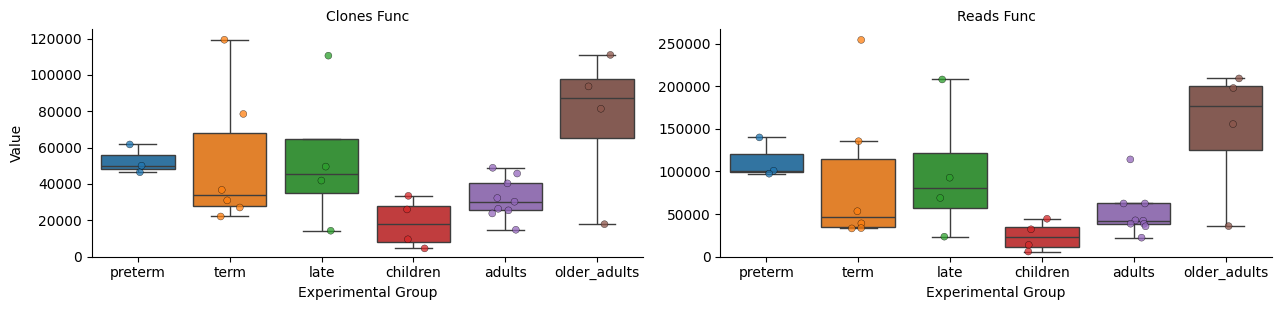

In [ ]:
rsplot.clonoset_stats(clonoset_stats_cd4, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)


In [ ]:
clonoset_stats_cd4.sort_values(by="reads_func")


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
27,c2_mnCD4_TRB_1,TRB,4667,4508,3481,1027,159,0.034069,6084,5912,172,0.028271,NaN,NaN,NaN,NaN,NaN
4,c4_mnCD4_TRB_1,TRB,9912,9515,6818,2697,397,0.040052,14155,13695,460,0.032497,NaN,NaN,NaN,NaN,NaN
23,a7_mnCD4_TRB_1,TRB,15395,14760,10071,4689,635,0.041247,22940,22220,720,0.031386,NaN,NaN,NaN,NaN,NaN
14,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
2,c5_mnCD4_TRB_1,TRB,26673,25952,21374,4578,721,0.027031,32840,32077,763,0.023234,NaN,NaN,NaN,NaN,NaN
20,UCB6_nCD4_TRB_1,TRB,23056,22069,14572,7497,987,0.042809,34149,33053,1096,0.032095,NaN,NaN,NaN,NaN,NaN
10,UCB12_mnCD4_TRB_1,TRB,28150,27005,22218,4787,1145,0.040675,34663,33459,1204,0.034734,NaN,NaN,NaN,NaN,NaN
17,a9_mnCD4_TRB_1,TRB,24536,23743,16874,6869,793,0.032320,36490,35572,918,0.025158,NaN,NaN,NaN,NaN,NaN
29,o5_mnCD4_TRB_1,TRB,19077,17835,9580,8255,1242,0.065105,37447,35797,1650,0.044062,NaN,NaN,NaN,NaN,NaN
7,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN


In [ ]:
depth=int(clonoset_stats_cd4.reads_func.min()//100*100)
assert depth>1
half_depth=depth//2
print('Основная глубина:',depth,'; дополнительная:',half_depth)


Основная глубина: 5900 ; дополнительная: 2950


## Фильтры

In [ ]:
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=depth, by_umi=True, seed=100)


In [ ]:
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter


In [ ]:
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter


In [ ]:
downsample_filter = clf.Filter(functionality="f", downsample=depth, by_umi=True, seed=100)
downsample_filter


## CDR3 свойства

In [ ]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd4, cl_filter=func_filter, cpu=1)
cdr3_properties


Using 1 core
CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,a13_mnCD4_TRB_1,TRB,43.742383,7.479997,0.021118,0.000031,-3.704198,-3.723470,0.129034,-0.319263,...,5.822250,15.144052,4.496033,14.376130,4.826838,14.286198,0.289599,0.787836,2.355211,2.782104
1,a10_mnCD4_TRB_1,TRB,43.851523,7.531335,0.020430,0.000025,-3.790137,-4.070470,0.129072,-0.326774,...,5.846552,15.204746,4.483801,14.403366,4.820777,14.315065,0.289203,0.789993,2.414296,2.864278
2,c5_mnCD4_TRB_1,TRB,42.867912,7.039748,0.021760,0.000039,-4.255295,-3.586878,0.068990,-0.253983,...,5.868865,14.890013,4.494778,14.055780,4.789094,13.975501,0.288526,0.769026,2.467594,2.698787
3,UCB11_nCD4_TRB_1,TRB,42.023485,5.444629,0.091856,0.000016,-3.929454,-3.313216,0.147141,-0.197369,...,5.760543,14.462995,4.528264,13.824702,4.847559,13.767604,0.291705,0.757527,2.212433,2.330767
4,c4_mnCD4_TRB_1,TRB,43.589704,7.223804,0.021468,0.000105,-3.764936,-3.890383,0.104418,-0.367725,...,5.858721,15.107782,4.479762,14.326391,4.820558,14.231157,0.289242,0.785058,2.394670,2.820591
5,o6_mnCD4_TRB_2,TRB,43.461947,7.081973,0.023362,0.000009,-3.973663,-3.456339,0.074600,-0.293948,...,5.893835,15.110378,4.476302,14.240984,4.794362,14.173627,0.289013,0.780200,2.519847,2.917334
6,UCB10_nCD4_TRB_1,TRB,42.659185,6.214106,0.051621,0.000008,-3.774383,-3.432034,0.131447,-0.272622,...,5.808512,14.739529,4.502695,14.017260,4.833382,13.953409,0.290439,0.767275,2.309746,2.530209
7,a1_mnCD4_TRB_1,TRB,43.414410,7.593281,0.019825,0.000039,-3.806782,-3.703336,0.133659,-0.265707,...,5.820975,15.027118,4.499575,14.268155,4.822275,14.172570,0.289014,0.779843,2.355116,2.696305
8,UCB13_mnCD4_TRB_1,TRB,42.373385,6.013994,0.067434,0.000032,-3.806382,-3.242834,0.141198,-0.200789,...,5.781895,14.607298,4.524297,13.955109,4.829587,13.840683,0.291215,0.761860,2.258791,2.491798
9,UCB3_nCD4_TRB_1,TRB,42.068839,5.514147,0.087020,0.000027,-4.112897,-3.699036,-0.012421,-0.392979,...,5.845735,14.570026,4.523018,13.829758,4.802395,13.743637,0.290124,0.756167,2.373785,2.518631


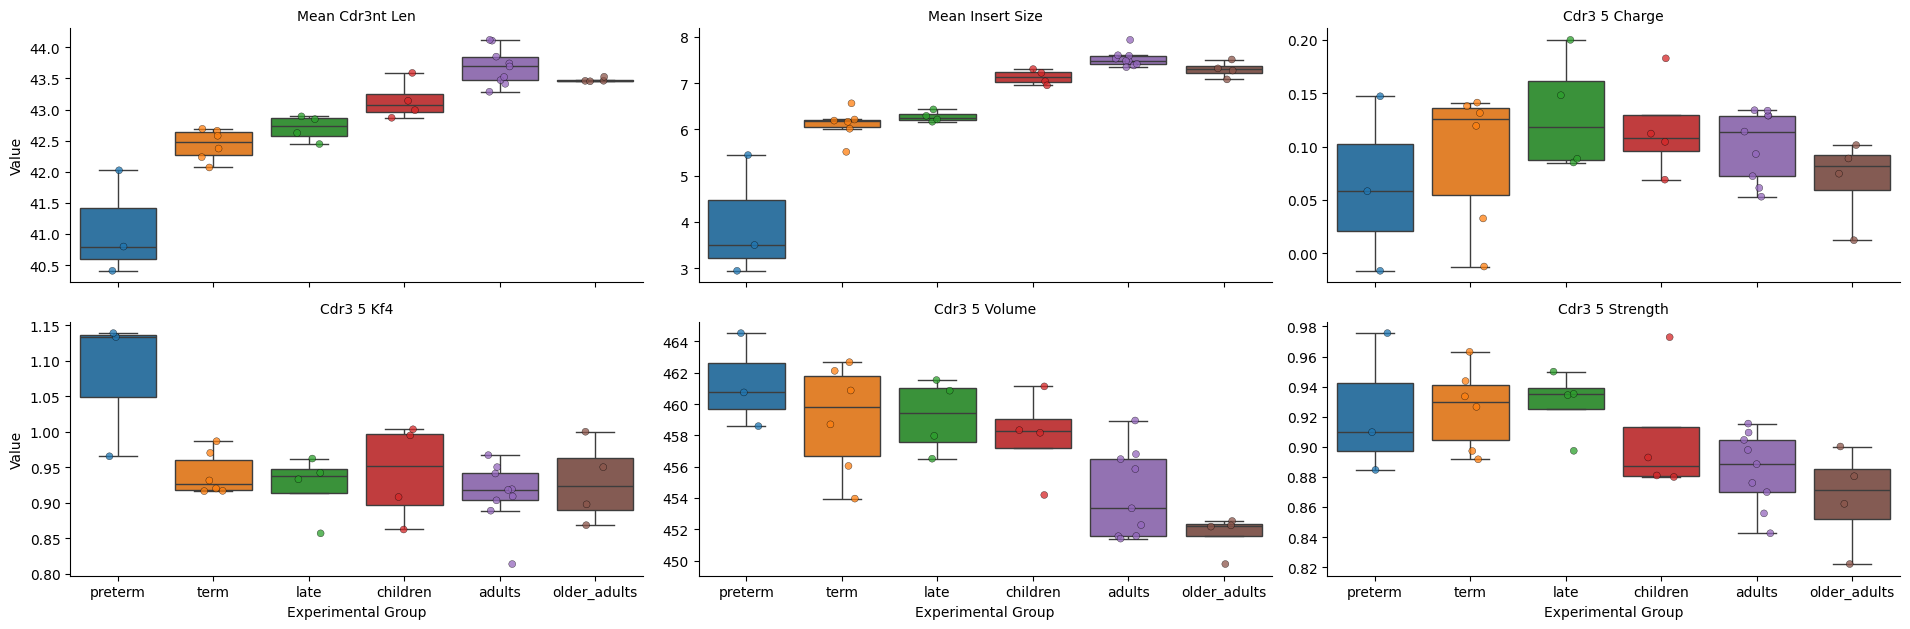

In [ ]:
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )


In [ ]:
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)


## CDR3len распределение

In [ ]:
preterm_late_cd4 = clonosets_cd4.query("experimental_group in ['preterm', 'late']")
preterm_late_cd4


,sample_id,chain,filename,experimental_group,donor_id,subset,source
3,UCB11_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB11,nCD4,UCB
13,UCB5_nCD4_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB5,nCD4,UCB
14,UCB4_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB4,nCD4,UCB
22,UCB9_nCD4_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB9,nCD4,UCB
24,UCB1_nCD4_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB1,nCD4,UCB
25,UCB8_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB8,nCD4,UCB
28,UCB7_nCD4_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB7,nCD4,UCB


In [ ]:
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_cd4,
                                                        cl_filter=func_filter,
                                                        cpu=2,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs


Using 2 cores
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD4_TRB_1,TRB,4,0.000000
1,UCB11_nCD4_TRB_1,TRB,5,0.000007
2,UCB11_nCD4_TRB_1,TRB,6,0.000021
3,UCB11_nCD4_TRB_1,TRB,7,0.000129
4,UCB11_nCD4_TRB_1,TRB,8,0.000371
...,...,...,...,...
156,UCB9_nCD4_TRB_2,TRB,22,0.000053
157,UCB9_nCD4_TRB_2,TRB,23,0.000038
158,UCB9_nCD4_TRB_2,TRB,24,0.000010
159,UCB9_nCD4_TRB_2,TRB,25,0.000010


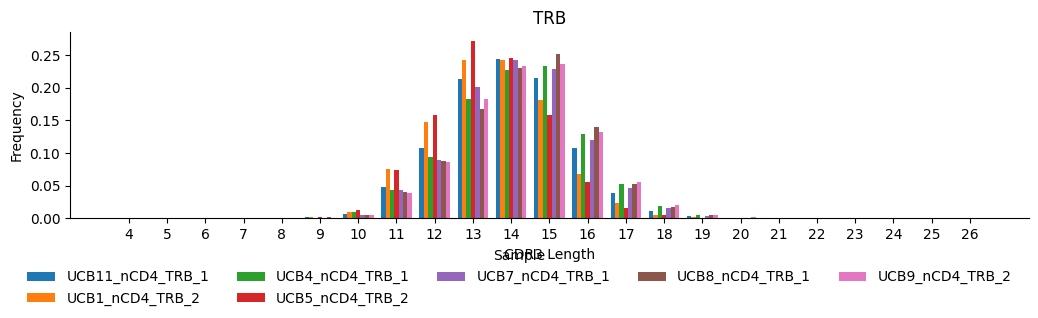

In [ ]:
rsplot.cdr3_length_distributions(cdr3_len_distribs)


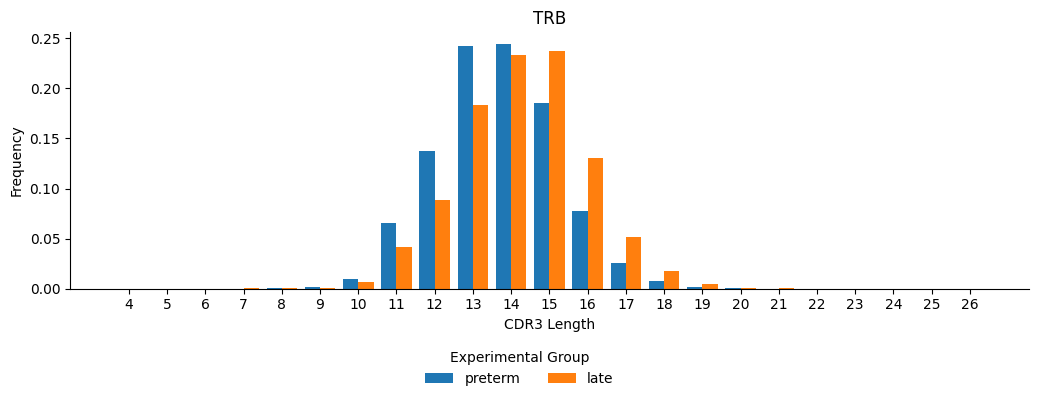

In [ ]:
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)


## V-usage

In [ ]:
v_usage = stats.calc_segment_usage(clonosets_cd4, segment="v", cl_filter=func_filter, table="long")
v_usage


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,v,usage
0,a13_mnCD4_TRB_1,TRB,TRBV1,0.000308
1,a10_mnCD4_TRB_1,TRB,TRBV1,0.000353
2,c5_mnCD4_TRB_1,TRB,TRBV1,0.000156
3,UCB11_nCD4_TRB_1,TRB,TRBV1,0.000457
4,c4_mnCD4_TRB_1,TRB,TRBV1,0.000584
...,...,...,...,...
1825,UCB8_nCD4_TRB_1,TRB,TRBV7-1,0.000000
1826,c1_mnCD4_TRB_1,TRB,TRBV7-1,0.000000
1827,c2_mnCD4_TRB_1,TRB,TRBV7-1,0.000000
1828,UCB7_nCD4_TRB_1,TRB,TRBV7-1,0.000000


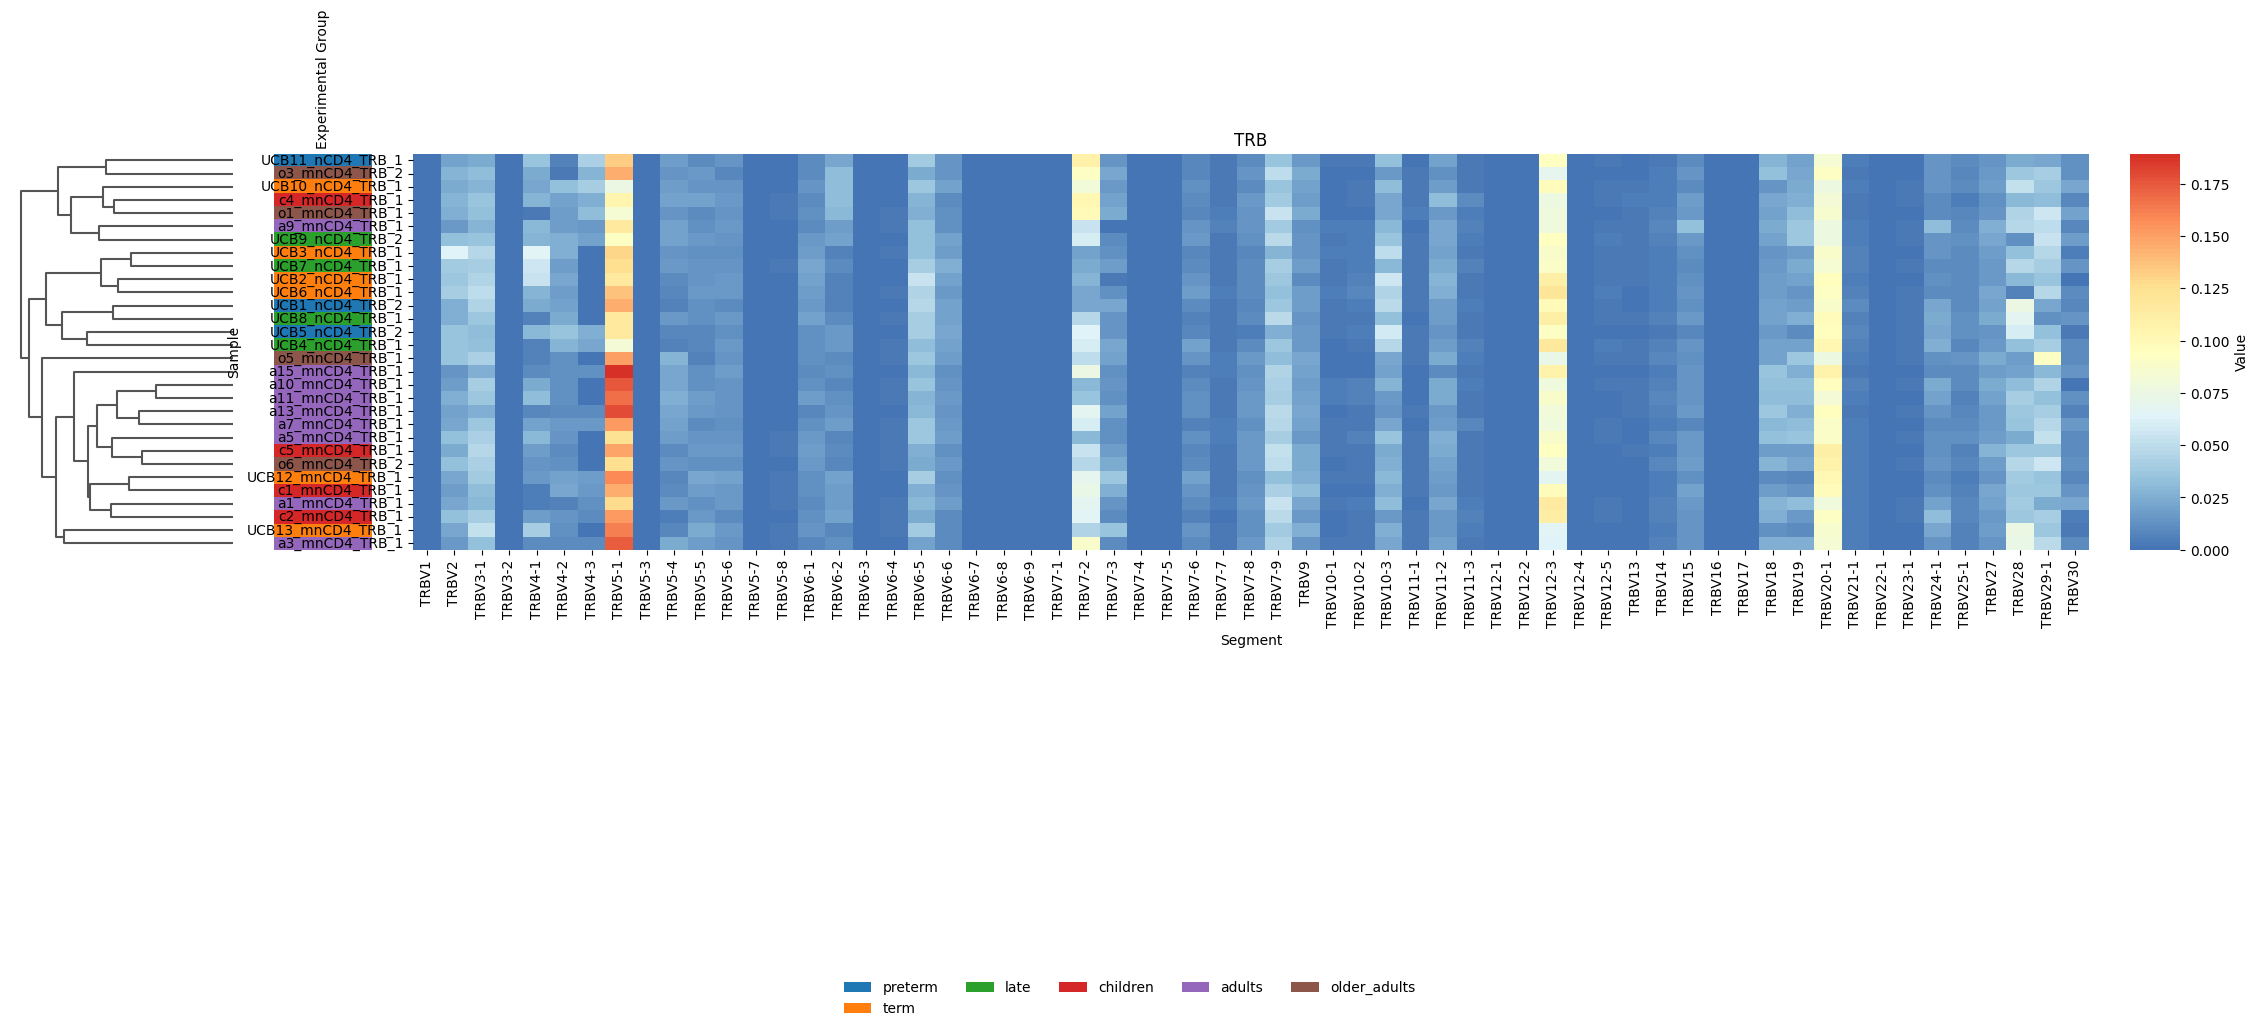

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)


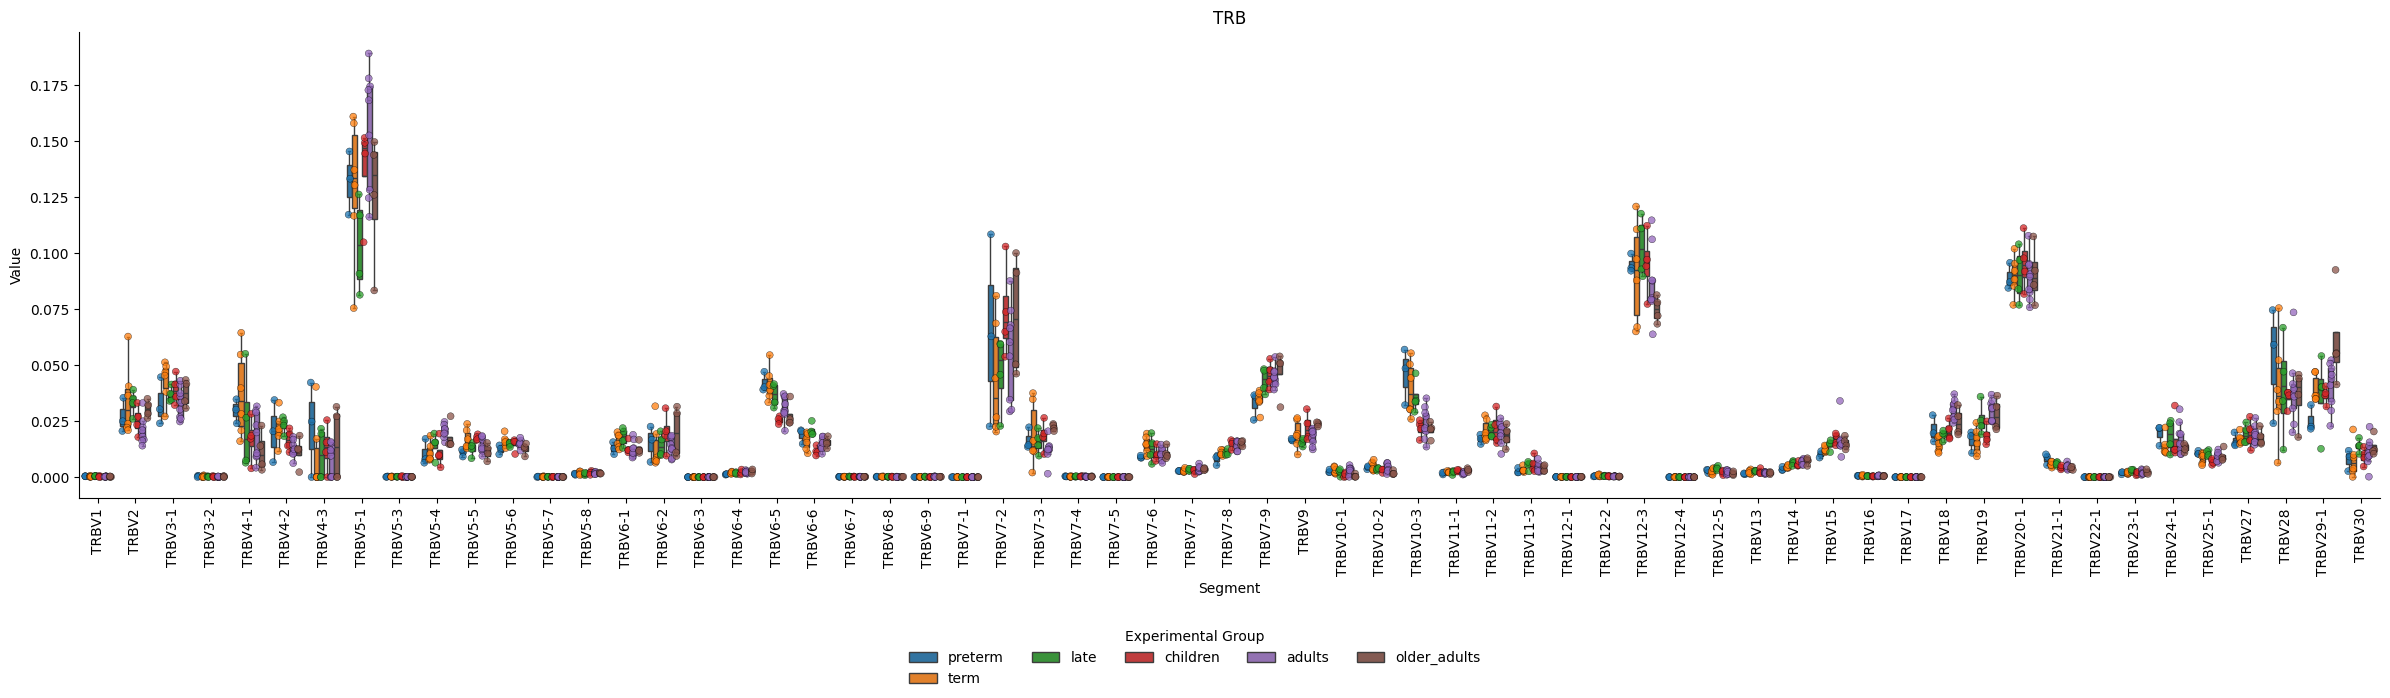

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )


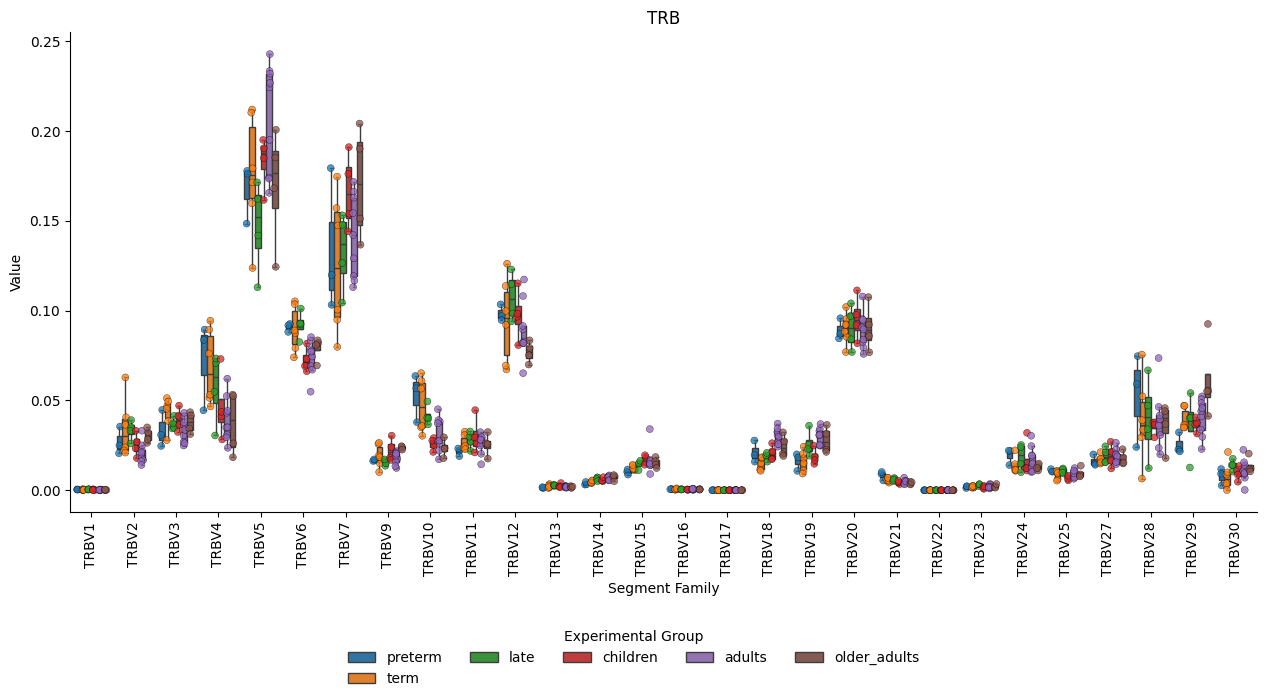

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)


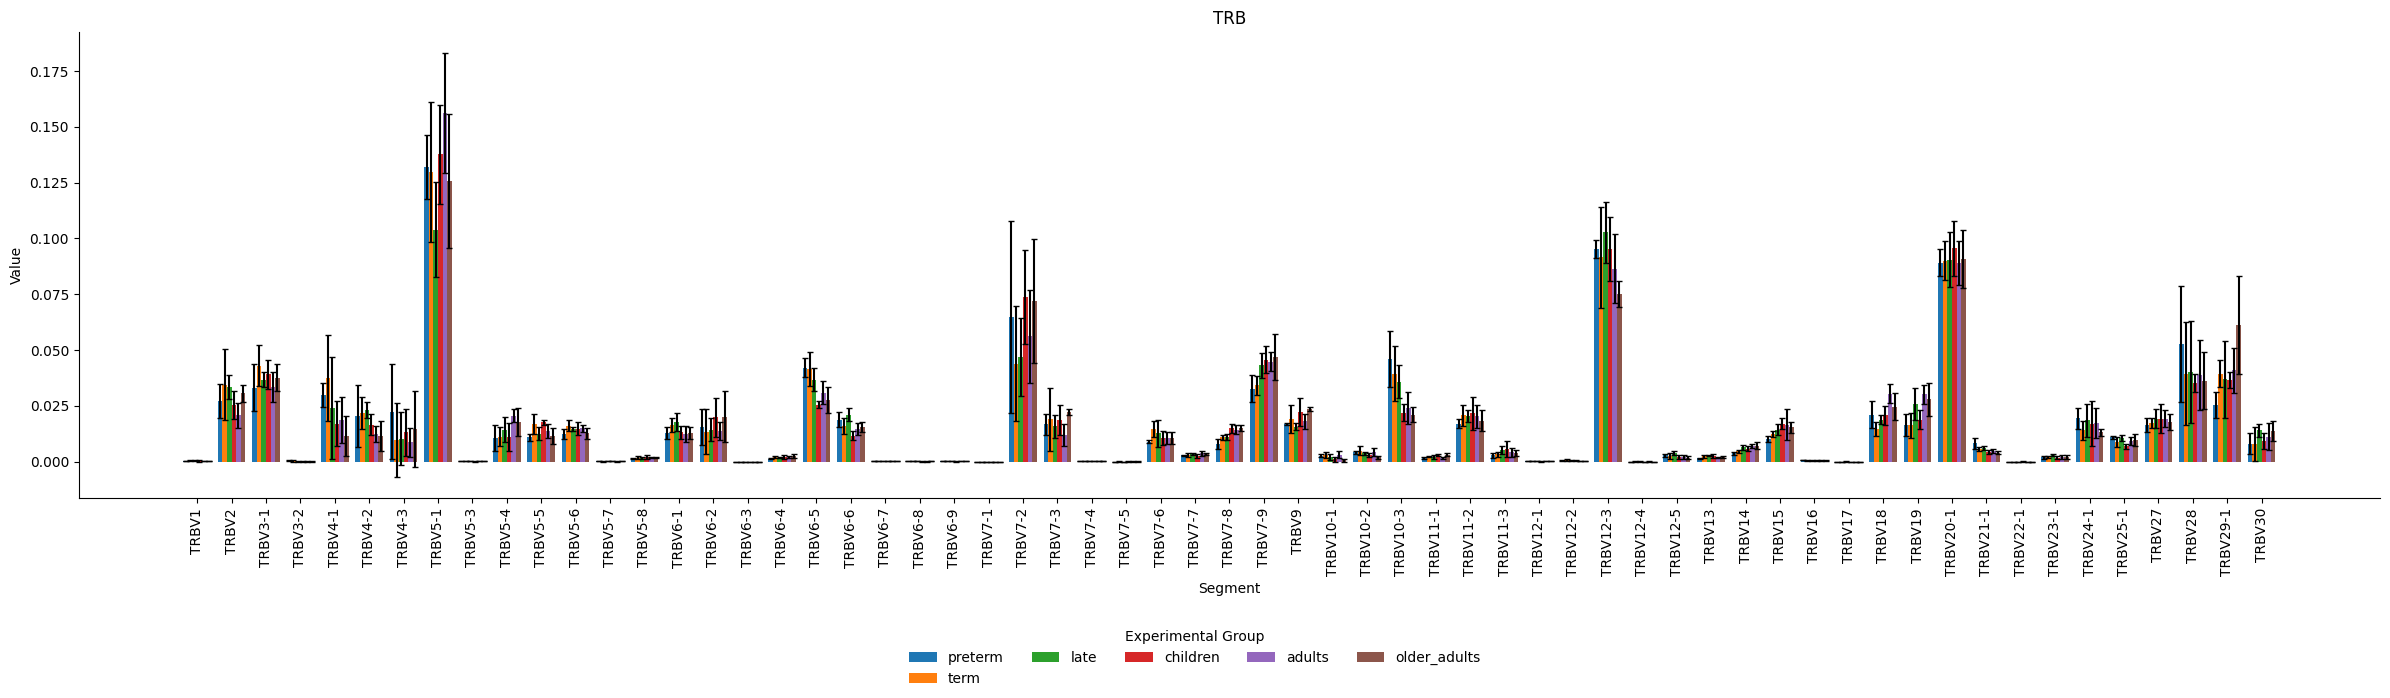

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)


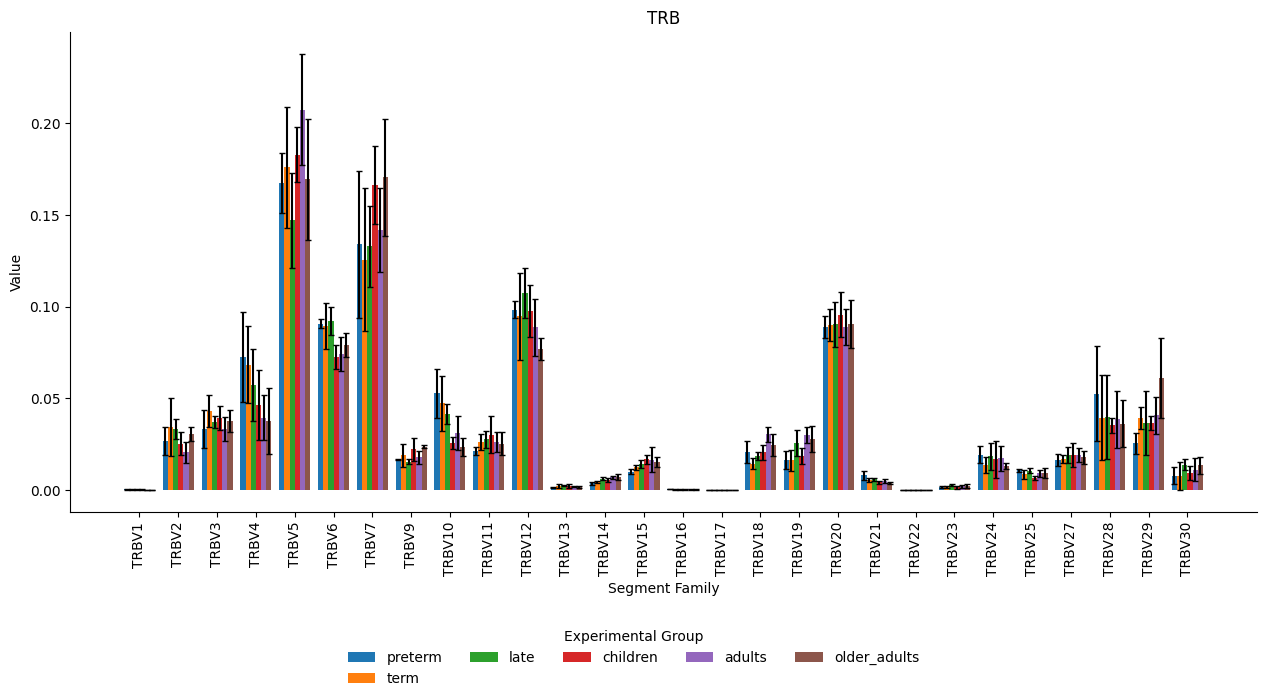

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)


## J-usage

In [ ]:
j_usage = stats.calc_segment_usage(clonosets_cd4, segment="j", cl_filter=func_filter)
j_usage


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,j,usage
0,a13_mnCD4_TRB_1,TRB,TRBJ1-1,0.098946
1,a10_mnCD4_TRB_1,TRB,TRBJ1-1,0.079158
2,c5_mnCD4_TRB_1,TRB,TRBJ1-1,0.139882
3,UCB11_nCD4_TRB_1,TRB,TRBJ1-1,0.090006
4,c4_mnCD4_TRB_1,TRB,TRBJ1-1,0.065717
...,...,...,...,...
385,UCB8_nCD4_TRB_1,TRB,TRBJ2-7,0.184718
386,c1_mnCD4_TRB_1,TRB,TRBJ2-7,0.106471
387,c2_mnCD4_TRB_1,TRB,TRBJ2-7,0.081867
388,UCB7_nCD4_TRB_1,TRB,TRBJ2-7,0.147903


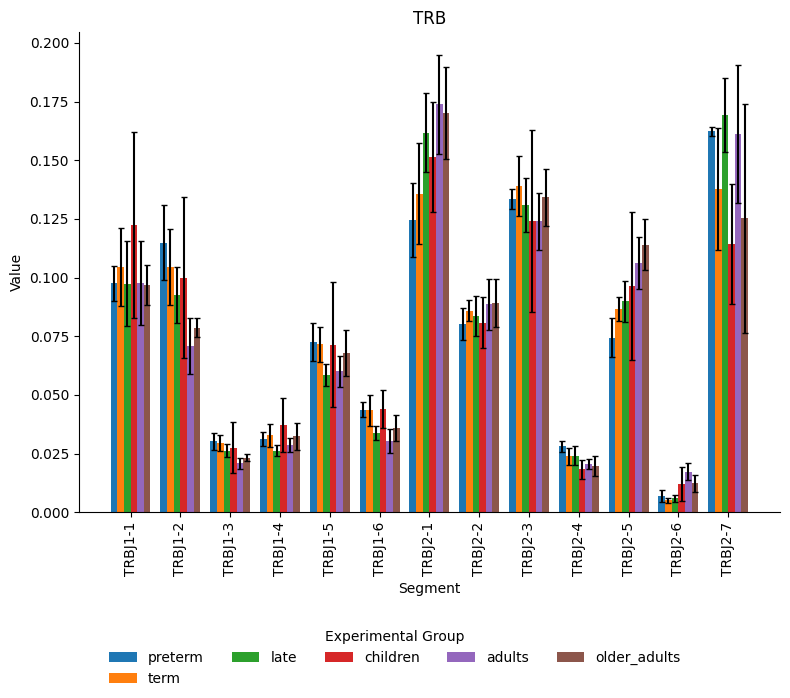

In [ ]:
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)


## Convergence

In [ ]:
convergence = stats.calc_convergence(clonosets_cd4,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence


CalcConvergence settings: seed=42, downsample=5900, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): a13_mnCD4_TRB_1, a10_mnCD4_TRB_1, c5_mnCD4_TRB_1, UCB11_nCD4_TRB_1, c4_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB10_nCD4_TRB_1, a1_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB12_mnCD4_TRB_1, UCB2_nCD4_TRB_1, o1_mnCD4_TRB_1, UCB5_nCD4_TRB_2, UCB4_nCD4_TRB_1, a11_mnCD4_TRB_1, a5_mnCD4_TRB_1, a9_mnCD4_TRB_1, a3_mnCD4_TRB_1, a15_mnCD4_TRB_1, UCB6_nCD4_TRB_1, o3_mnCD4_TRB_2, UCB9_nCD4_TRB_2, a7_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB8_nCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 30/30 calcultaion(s) proc

,sample_id,chain,convergence,convergence_v,convergence_vj
0,a13_mnCD4_TRB_1,TRB,1.002504,1.000357,1.000357
1,a10_mnCD4_TRB_1,TRB,1.003245,1.000360,1.000360
2,c5_mnCD4_TRB_1,TRB,1.003972,1.001080,1.001080
3,UCB11_nCD4_TRB_1,TRB,1.015722,1.001619,1.001619
4,c4_mnCD4_TRB_1,TRB,1.005436,1.001458,1.001458
5,o6_mnCD4_TRB_2,TRB,1.001920,1.000348,1.000348
6,UCB10_nCD4_TRB_1,TRB,1.007361,1.001218,1.001218
7,a1_mnCD4_TRB_1,TRB,1.001857,1.000371,1.000371
8,UCB13_mnCD4_TRB_1,TRB,1.010289,1.000715,1.000715
9,UCB3_nCD4_TRB_1,TRB,1.010698,1.002155,1.002155


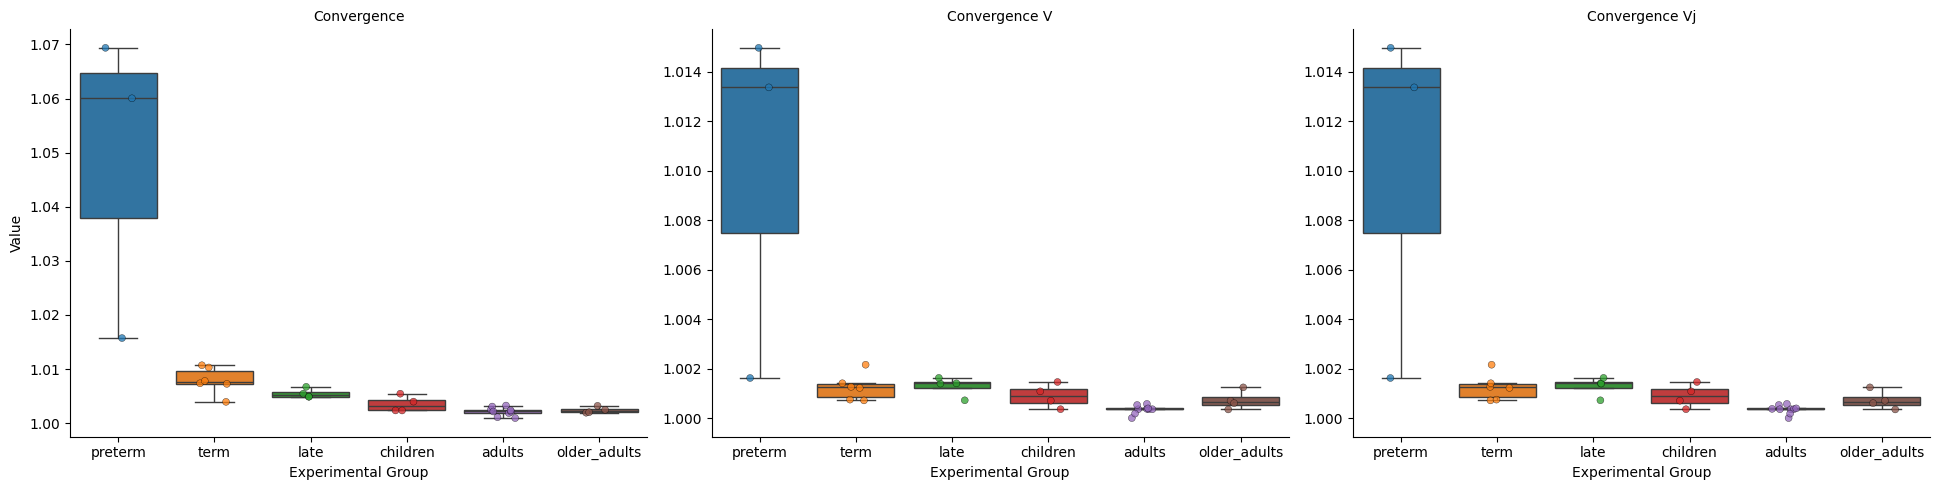

In [ ]:
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )


## Разнообразие

In [ ]:
diversity_stats = stats.calc_diversity_stats(clonosets_cd4,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False,
                                             verbose=True
                                            )
diversity_stats


CalcDiversityStats settings: seed=123, downsample=5900, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): a13_mnCD4_TRB_1, a10_mnCD4_TRB_1, c5_mnCD4_TRB_1, UCB11_nCD4_TRB_1, c4_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB10_nCD4_TRB_1, a1_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB12_mnCD4_TRB_1, UCB2_nCD4_TRB_1, o1_mnCD4_TRB_1, UCB5_nCD4_TRB_2, UCB4_nCD4_TRB_1, a11_mnCD4_TRB_1, a5_mnCD4_TRB_1, a9_mnCD4_TRB_1, a3_mnCD4_TRB_1, a15_mnCD4_TRB_1, UCB6_nCD4_TRB_1, o3_mnCD4_TRB_2, UCB9_nCD4_TRB_2, a7_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB8_nCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(

,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,a13_mnCD4_TRB_1,TRB,5631.0,0.997982,0.002018,8.618615,63568.775100,5631.0,63450.731204,0.089492,0.476114,0.000186,5390.213688,0.999814,0.000508,0.043571
1,a10_mnCD4_TRB_1,TRB,5590.0,0.997701,0.002299,8.608893,54182.690972,5590.0,54155.993432,0.103220,0.472272,0.000188,5321.002751,0.999812,0.000508,0.049828
2,c5_mnCD4_TRB_1,TRB,5635.0,0.997920,0.002080,8.618788,68733.165217,5635.0,68642.901846,0.086780,0.476486,0.000186,5381.880025,0.999814,0.000678,0.043071
3,UCB11_nCD4_TRB_1,TRB,5587.0,0.997336,0.002664,8.605209,59060.596958,5587.0,65379.923208,0.101017,0.471989,0.000191,5234.586466,0.999809,0.001695,0.050609
4,c4_mnCD4_TRB_1,TRB,4929.0,0.992291,0.007709,8.437339,18325.622257,4929.0,18057.861993,0.299153,0.401501,0.000237,4217.349164,0.999763,0.001186,0.142052
5,o6_mnCD4_TRB_2,TRB,5763.0,0.998975,0.001025,8.650340,124818.473684,5763.0,125006.250000,0.046102,0.488114,0.000177,5634.509550,0.999823,0.000508,0.022684
6,UCB10_nCD4_TRB_1,TRB,5770.0,0.999025,0.000975,8.651985,132065.722222,5770.0,132063.041219,0.043729,0.488735,0.000177,5647.306944,0.999823,0.000508,0.021553
7,a1_mnCD4_TRB_1,TRB,5458.0,0.996616,0.003384,8.575723,39364.183511,5458.0,39308.954022,0.144068,0.459509,0.000197,5077.304551,0.999803,0.000678,0.069714
8,UCB13_mnCD4_TRB_1,TRB,5663.0,0.998177,0.001823,8.625957,75067.708920,5663.0,74736.282082,0.078305,0.479075,0.000184,5440.762738,0.999816,0.000508,0.038650
9,UCB3_nCD4_TRB_1,TRB,5617.0,0.997848,0.002152,8.614971,61687.109804,5617.0,61445.518780,0.093559,0.474809,0.000187,5360.332615,0.999813,0.000508,0.045777


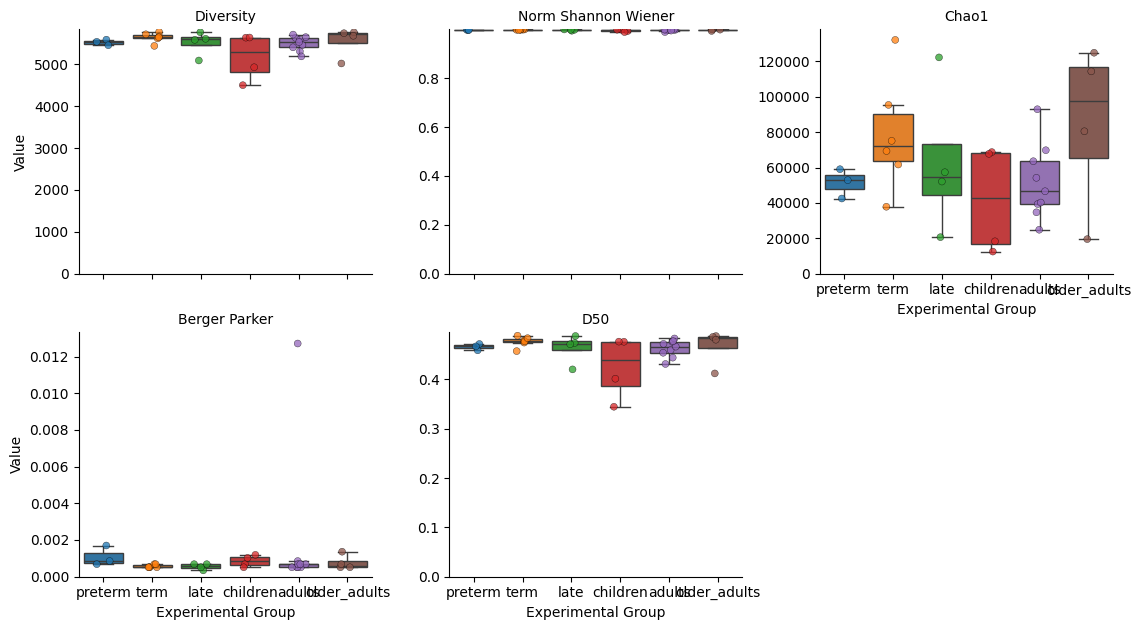

In [ ]:
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )


## Downsample sensitivity

CalcDiversityStats settings: seed=123, downsample=2950, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): a13_mnCD4_TRB_1, a10_mnCD4_TRB_1, c5_mnCD4_TRB_1, UCB11_nCD4_TRB_1, c4_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB10_nCD4_TRB_1, a1_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB12_mnCD4_TRB_1, UCB2_nCD4_TRB_1, o1_mnCD4_TRB_1, UCB5_nCD4_TRB_2, UCB4_nCD4_TRB_1, a11_mnCD4_TRB_1, a5_mnCD4_TRB_1, a9_mnCD4_TRB_1, a3_mnCD4_TRB_1, a15_mnCD4_TRB_1, UCB6_nCD4_TRB_1, o3_mnCD4_TRB_2, UCB9_nCD4_TRB_2, a7_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB8_nCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(

,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,a13_mnCD4_TRB_1,TRB,2875.0,0.998764,0.001236,7.953961,58145.436620,2875.0,58111.668191,0.050169,0.486957,0.000357,2803.640464,0.999643,0.001017,0.024795
1,a10_mnCD4_TRB_1,TRB,2872.0,0.998717,0.001283,7.952551,55674.837838,2872.0,55649.367481,0.052203,0.486421,0.000357,2798.231511,0.999643,0.001017,0.025758
2,c5_mnCD4_TRB_1,TRB,2870.0,0.998598,0.001402,7.950902,60331.911765,2870.0,59635.000378,0.052203,0.486063,0.000359,2787.475977,0.999641,0.001017,0.026468
3,UCB11_nCD4_TRB_1,TRB,2876.0,0.998661,0.001339,7.953491,59911.000000,2876.0,66838.596966,0.048814,0.487135,0.000358,2791.051956,0.999642,0.002034,0.024507
4,c4_mnCD4_TRB_1,TRB,2715.0,0.996088,0.003912,7.875618,18231.184080,2715.0,18418.362492,0.153220,0.456722,0.000398,2513.720393,0.999602,0.001695,0.073749
5,o6_mnCD4_TRB_2,TRB,2919.0,0.999476,0.000524,7.974815,146771.275862,2919.0,146544.729660,0.020678,0.494690,0.000346,2887.358991,0.999654,0.001017,0.010404
6,UCB10_nCD4_TRB_1,TRB,2921.0,0.999530,0.000470,7.975932,147072.241379,2921.0,148568.103448,0.019661,0.495036,0.000346,2893.118351,0.999654,0.000678,0.009733
7,a1_mnCD4_TRB_1,TRB,2824.0,0.997885,0.002115,7.929108,35477.214286,2824.0,35296.109973,0.083051,0.477691,0.000370,2706.001244,0.999630,0.001017,0.041006
8,UCB13_mnCD4_TRB_1,TRB,2886.0,0.998911,0.001089,7.958953,71660.137931,2886.0,71383.008830,0.042373,0.488912,0.000354,2821.822309,0.999646,0.001017,0.021257
9,UCB3_nCD4_TRB_1,TRB,2881.0,0.998856,0.001144,7.956781,63771.630769,2881.0,63715.603484,0.046102,0.488025,0.000355,2814.521345,0.999645,0.001017,0.022861


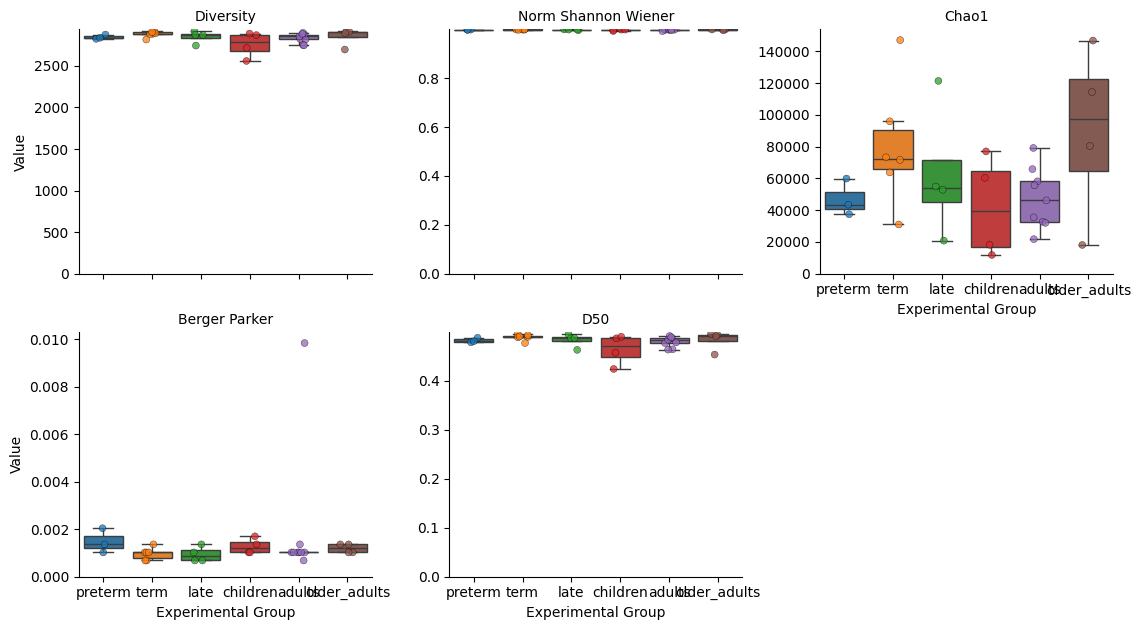

In [ ]:
smaller_filter=clf.Filter(functionality='f',downsample=half_depth,by_umi=True,seed=100)
diversity_half=stats.calc_diversity_stats(clonosets_cd4,cl_filter=smaller_filter,
    seed=123,cpu=2,iterations=3,drop_small_samples=False,verbose=True)
display(diversity_half)
rsplot.diversity_stats(diversity_half,metadata=metadata,group='experimental_group')


## Rarefaction

In [ ]:
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd4, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD4_TRB_1,TRB,32,32.000000
1,UCB10_nCD4_TRB_1,TRB,100,100.000000
2,UCB10_nCD4_TRB_1,TRB,316,316.000000
3,UCB10_nCD4_TRB_1,TRB,1000,995.333333
4,UCB10_nCD4_TRB_1,TRB,3162,3123.000000
...,...,...,...,...
239,o6_mnCD4_TRB_2,TRB,3162,3118.333333
240,o6_mnCD4_TRB_2,TRB,10000,9570.000000
241,o6_mnCD4_TRB_2,TRB,31623,27684.000000
242,o6_mnCD4_TRB_2,TRB,100000,69475.333333


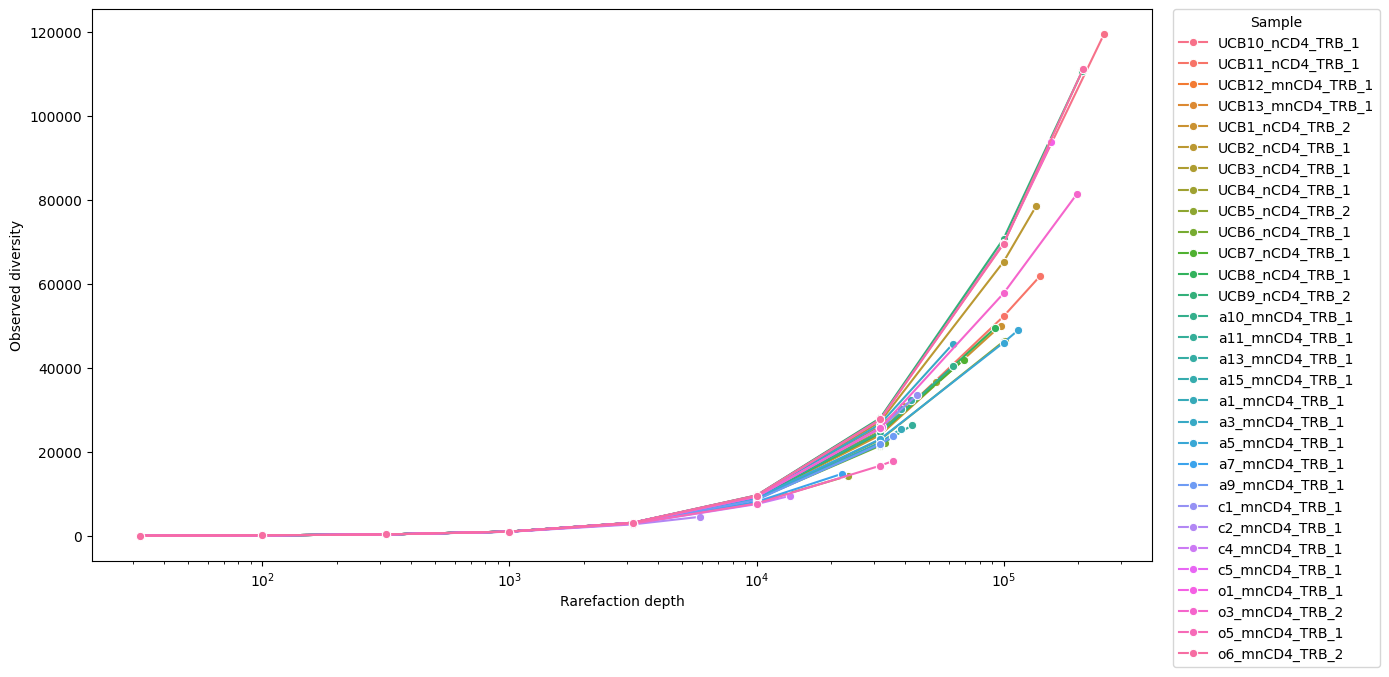

In [ ]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)


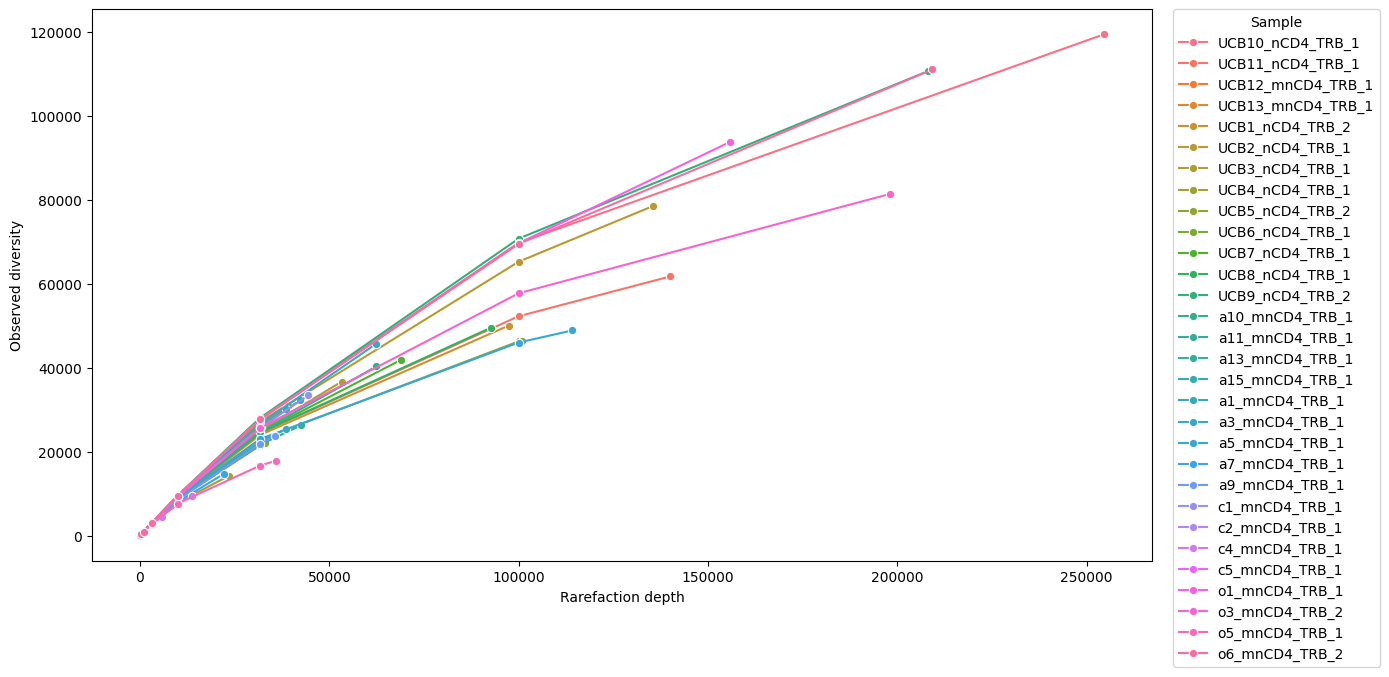

In [ ]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)


## Beta-diversity

In [ ]:
beta_diversity = beta.metrics(clonosets_cd4,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=2                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )


Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 30/30 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 435/435 pairs processed


In [ ]:
beta_diversity.keys()


dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [ ]:
beta_diversity["f2"]


sample2,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB12_mnCD4_TRB_1,UCB13_mnCD4_TRB_1,UCB1_nCD4_TRB_2,UCB2_nCD4_TRB_1,UCB3_nCD4_TRB_1,UCB4_nCD4_TRB_1,UCB5_nCD4_TRB_2,UCB6_nCD4_TRB_1,...,a7_mnCD4_TRB_1,a9_mnCD4_TRB_1,c1_mnCD4_TRB_1,c2_mnCD4_TRB_1,c4_mnCD4_TRB_1,c5_mnCD4_TRB_1,o1_mnCD4_TRB_1,o3_mnCD4_TRB_2,o5_mnCD4_TRB_1,o6_mnCD4_TRB_2
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD4_TRB_1,1.000000,0.002993,0.002315,0.003022,0.008806,0.002654,0.004717,0.003161,0.008949,0.001835,...,0.001397,0.000847,0.001186,0.001281,0.001620,0.000339,0.000847,0.001186,0.000649,0.001257
UCB11_nCD4_TRB_1,0.002993,1.000000,0.005816,0.005560,0.018506,0.003291,0.008050,0.003964,0.023426,0.003989,...,0.001935,0.001736,0.001596,0.002422,0.003216,0.001525,0.002497,0.001567,0.001959,0.001381
UCB12_mnCD4_TRB_1,0.002315,0.005816,1.000000,0.003402,0.007296,0.002034,0.003894,0.002034,0.012992,0.001736,...,0.001356,0.000579,0.001666,0.000409,0.001451,0.001017,0.001596,0.001496,0.001087,0.000579
UCB13_mnCD4_TRB_1,0.003022,0.005560,0.003402,1.000000,0.013497,0.003191,0.005342,0.004233,0.014544,0.002274,...,0.001906,0.000847,0.002129,0.000847,0.002583,0.000847,0.001017,0.003017,0.001087,0.001356
UCB1_nCD4_TRB_2,0.008806,0.018506,0.007296,0.013497,1.000000,0.008404,0.020847,0.009481,0.050471,0.006502,...,0.003566,0.002202,0.003701,0.005126,0.002369,0.002104,0.001356,0.002654,0.003427,0.003047
UCB2_nCD4_TRB_1,0.002654,0.003291,0.002034,0.003191,0.008404,1.000000,0.004597,0.004576,0.011481,0.000678,...,0.001720,0.001157,0.001525,0.000409,0.001087,0.001327,0.000678,0.000818,0.000579,0.001017
UCB3_nCD4_TRB_1,0.004717,0.008050,0.003894,0.005342,0.020847,0.004597,1.000000,0.004352,0.023190,0.002369,...,0.001521,0.001403,0.002180,0.001058,0.001597,0.001567,0.001835,0.001525,0.001906,0.001257
UCB4_nCD4_TRB_1,0.003161,0.003964,0.002034,0.004233,0.009481,0.004576,0.004352,1.000000,0.008893,0.000988,...,0.000918,0.002046,0.001211,0.001842,0.001550,0.000649,0.001496,0.001596,0.000678,0.000847
UCB5_nCD4_TRB_2,0.008949,0.023426,0.012992,0.014544,0.050471,0.011481,0.023190,0.008893,1.000000,0.005709,...,0.003540,0.003658,0.003456,0.003164,0.004445,0.002708,0.003945,0.003117,0.002662,0.003485


In [ ]:
beta_diversity["full_table"].query("pair == 'UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1'")


,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CSAVSTAEAFF,TRBV20-1,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
1,CASSFIGTHTGELFF,TRBV5-1,0,1,0.000000,0.000169,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
2,CSVKTSGGVSNEQFF,TRBV29-1,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
3,CSARSGRETQYF,TRBV20-1,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
4,CASSLAETQYF,TRBV6-5,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
...,...,...,...,...,...,...,...,...,...
11287,CASSLATAIGAYF,TRBV12-3,2,0,0.000339,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
11288,CASSGTPMNTEAFF,TRBV25-1,0,1,0.000000,0.000169,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
11289,CASSLSGTLNTGELFF,TRBV5-1,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
11290,CASRPGTGVNQPQHF,TRBV6-1,1,0,0.000169,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1


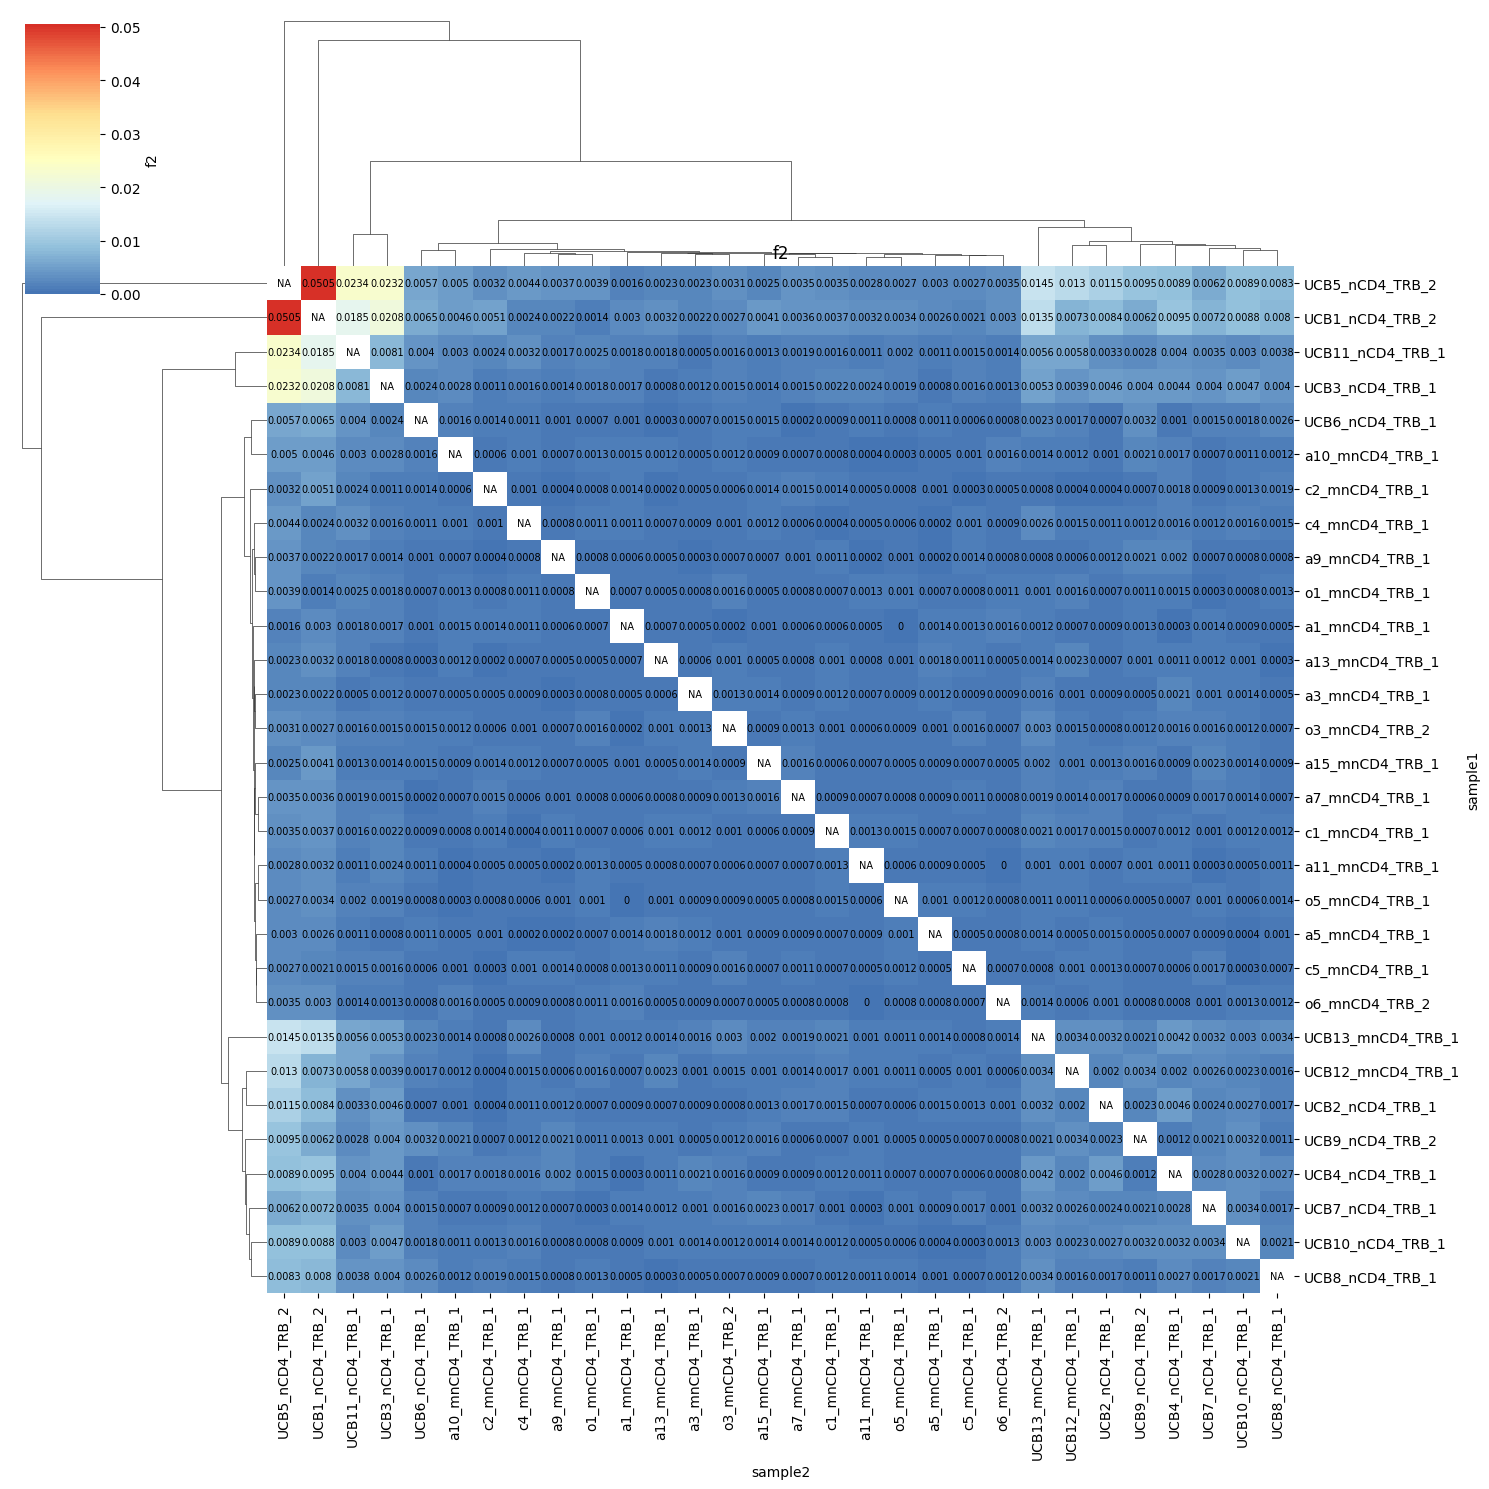

In [ ]:
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )


In [ ]:
ucb_cd4_mds = beta.mds(beta_diversity)
ucb_cd4_mds


,sample_id,MDS1,MDS2
0,UCB10_nCD4_TRB_1,0.340452,-0.056744
1,UCB11_nCD4_TRB_1,0.147531,0.006120
2,UCB12_mnCD4_TRB_1,-0.266474,0.109607
3,UCB13_mnCD4_TRB_1,-0.015659,0.048011
4,UCB1_nCD4_TRB_2,0.030365,0.158616
5,UCB2_nCD4_TRB_1,0.144618,0.020480
6,UCB3_nCD4_TRB_1,-0.023218,0.164861
7,UCB4_nCD4_TRB_1,-0.220015,-0.157120
8,UCB5_nCD4_TRB_2,-0.011136,-0.036151
9,UCB6_nCD4_TRB_1,0.212990,0.365099


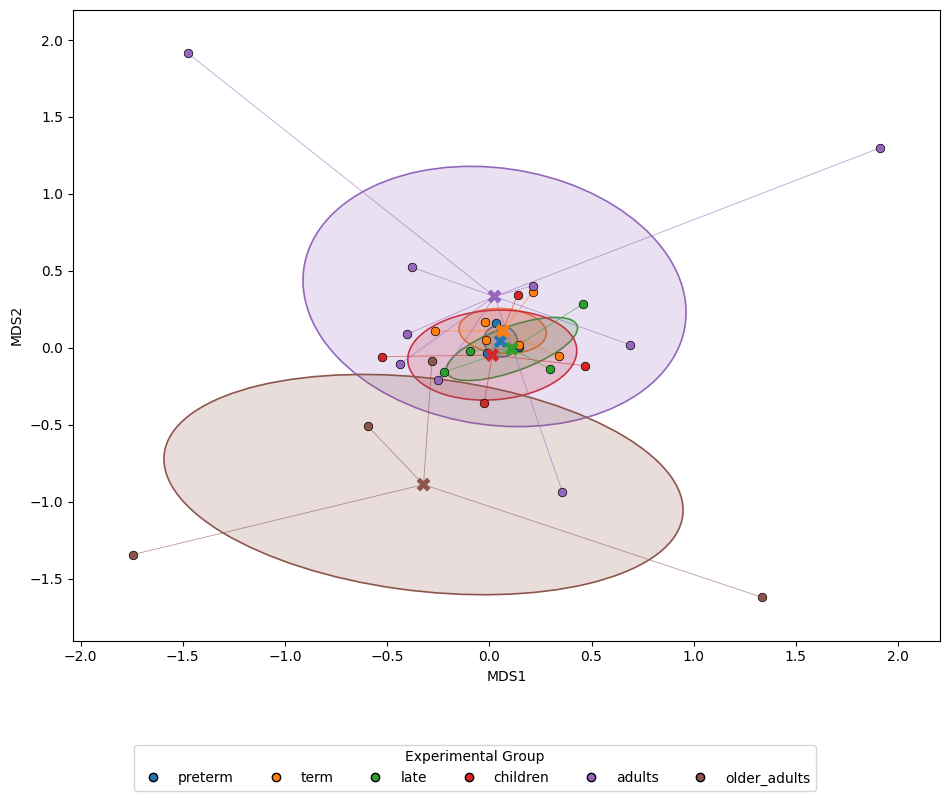

In [ ]:
rsplot.beta_mds(ucb_cd4_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)


## Кластеризация

In [ ]:
clusters = clustering.Clusters()
clusters


Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
clusters.read_from_clonosets_df(clonosets_cd4, cl_filter=downsample_filter)


Pooled 164840 clonotypes from 30 samples


In [ ]:
clusters.create_clusters(overlap_type='aaV', mismatches=1, cpu=1)


Nodes list created: 164840 nodes
Using 1 core
Find neighbour clonotypes |##################################################| 727/727 tasks processed
found 78220 edges
-----------------------------
NexworkX graph created
Found 8520 clusters (2 or more nodes) and 123811 single nodes. Total: 132331


In [ ]:
clusters.add_metadata(metadata)


In [ ]:
clusters_df = clusters.as_dataframe()
clusters_df


,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,147234,CASSLGQGKETQYF,TRBV5-1,TRBJ2-5,TGCGCCAGCAGCTTGGGACAGGGTAAAGAGACCCAGTACTTC,UCB13_mnCD4_TRB_1,0.000169,1,None,5,term,UCB13,nCD4,UCB
1,0,70938,CASSLGGQGYEQYF,TRBV5-1,TRBJ2-7,TGCGCCAGCAGCTTGGGGGGACAGGGTTACGAGCAGTACTTC,UCB9_nCD4_TRB_2,0.000169,1,None,6,late,UCB9,nCD4,UCB
2,0,80628,CASSPQTSTDTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCCCCCAGACTAGCACAGATACGCAGTATTTT,UCB1_nCD4_TRB_2,0.000169,1,None,3,preterm,UCB1,nCD4,UCB
3,0,96642,CASSTSGGADTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCACTAGCGGGGGGGCCGATACGCAGTATTTT,UCB10_nCD4_TRB_1,0.000169,1,None,4,term,UCB10,nCD4,UCB
4,0,147336,CASSLAGGTDTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCTTGGCGGGAGGCACAGATACGCAGTATTTT,UCB13_mnCD4_TRB_1,0.000169,1,None,38,term,UCB13,nCD4,UCB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164835,132326,60304,WSARQGAAEAFF,TRBV20-1,TRBJ1-1,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,o5_mnCD4_TRB_1,0.000169,1,None,0,older_adults,o5,nCD4,PB
164836,132327,25238,WTSDYGGDSNQPQHF,TRBV7-6,TRBJ1-5,TGGACTAGCGACTACGGGGGGGATAGCAATCAGCCCCAGCATTTT,UCB6_nCD4_TRB_1,0.000169,1,None,0,term,UCB6,nCD4,UCB
164837,132328,94122,WVTGQGRNEQFF,TRBV19,TRBJ2-1,TGGGTTACAGGACAGGGTCGCAATGAGCAGTTCTTC,c4_mnCD4_TRB_1,0.000169,1,None,0,children,c4,nCD4,PB
164838,132329,134747,YASSLEGNTEAFF,TRBV7-9,TRBJ1-1,TATGCCAGCAGCTTAGAGGGGAACACTGAAGCTTTCTTT,UCB2_nCD4_TRB_1,0.000169,1,None,0,term,UCB2,nCD4,UCB


In [ ]:
cluster_properties = clusters.properties(cpu=1)
cluster_properties


Using 1 core
Calculating cluster properties |##################################################| 132331/132331 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,1204,4002,1311,27,0.005526,21.428571,CASSLGGGTDTQYF,TGCGCCAGCAGCTTGGGGGGGGGCACAGATACGCAGTACTTC,TRBV5-1,TRBJ2-3
1,1,cluster_1,1086,3304,1201,37,0.005608,27.049724,CASSLGGGGTNEQFF,TGCGCCAGCAGCTTGGGAGGGGGGGGCACCGATGAGCAGTTCTTC,TRBV5-1,TRBJ2-1
2,2,cluster_2,559,3071,623,18,0.019691,13.125224,CASSLGGDEQYF,TGCGCCAGCAGCTTGGGCGGCGATGAGCAGTACTTC,TRBV5-1,TRBJ2-7
3,3,cluster_3,530,3274,609,16,0.023355,11.916981,CASSLGGNTEAFF,TGCGCCAGCAGCTTGGGGGGGAACACTGAAGCTTTCTTT,TRBV5-1,TRBJ1-1
4,4,cluster_4,406,1400,464,12,0.017029,8.642857,CASSLGGGNTEAFF,TGCGCCAGCAGCTTGGGGGGGGGGAACACTGAAGCTTTCTTT,TRBV5-1,TRBJ1-1
...,...,...,...,...,...,...,...,...,...,...,...,...
132326,132326,cluster_132326,1,0,1,0,0.000000,0.000000,WSARQGAAEAFF,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1
132327,132327,cluster_132327,1,0,1,0,0.000000,0.000000,WTSDYGGDSNQPQHF,TGGACTAGCGACTACGGGGGGGATAGCAATCAGCCCCAGCATTTT,TRBV7-6,TRBJ1-5
132328,132328,cluster_132328,1,0,1,0,0.000000,0.000000,WVTGQGRNEQFF,TGGGTTACAGGACAGGGTCGCAATGAGCAGTTCTTC,TRBV19,TRBJ2-1
132329,132329,cluster_132329,1,0,1,0,0.000000,0.000000,YASSLEGNTEAFF,TATGCCAGCAGCTTAGAGGGGAACACTGAAGCTTTCTTT,TRBV7-9,TRBJ1-1


In [ ]:
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
14,14,cluster_14,220,939,243,10,0.038979,7.054545,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV12-3,TRBJ1-1
20,20,cluster_20,150,729,171,9,0.065235,6.613333,CASSLGGNQPQHF,TGTGCCAGCAGTTTAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
23,23,cluster_23,139,279,160,23,0.029090,16.438849,CSVGRGTETQYF,TGCAGCGTTGGAGGGGGCACAGAGACCCAGTACTTC,TRBV29-1,TRBJ2-5
27,27,cluster_27,130,296,140,17,0.035301,13.307692,CASSLGGGTNEQFF,TGTGCCAGCAGTTTAGGGGGGGGCACCAATGAGCAGTTCTTC,TRBV12-3,TRBJ2-1
31,31,cluster_31,119,368,134,11,0.052414,8.226891,CASSLGGGNQPQHF,TGTGCCAGCAGTTTAGGGGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
...,...,...,...,...,...,...,...,...,...,...,...,...
132326,132326,cluster_132326,1,0,1,0,0.000000,0.000000,WSARQGAAEAFF,TGGAGTGCACGACAGGGGGCGGCTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1
132327,132327,cluster_132327,1,0,1,0,0.000000,0.000000,WTSDYGGDSNQPQHF,TGGACTAGCGACTACGGGGGGGATAGCAATCAGCCCCAGCATTTT,TRBV7-6,TRBJ1-5
132328,132328,cluster_132328,1,0,1,0,0.000000,0.000000,WVTGQGRNEQFF,TGGGTTACAGGACAGGGTCGCAATGAGCAGTTCTTC,TRBV19,TRBJ2-1
132329,132329,cluster_132329,1,0,1,0,0.000000,0.000000,YASSLEGNTEAFF,TATGCCAGCAGCTTAGAGGGGAACACTGAAGCTTTCTTT,TRBV7-9,TRBJ1-1


## Кластеры

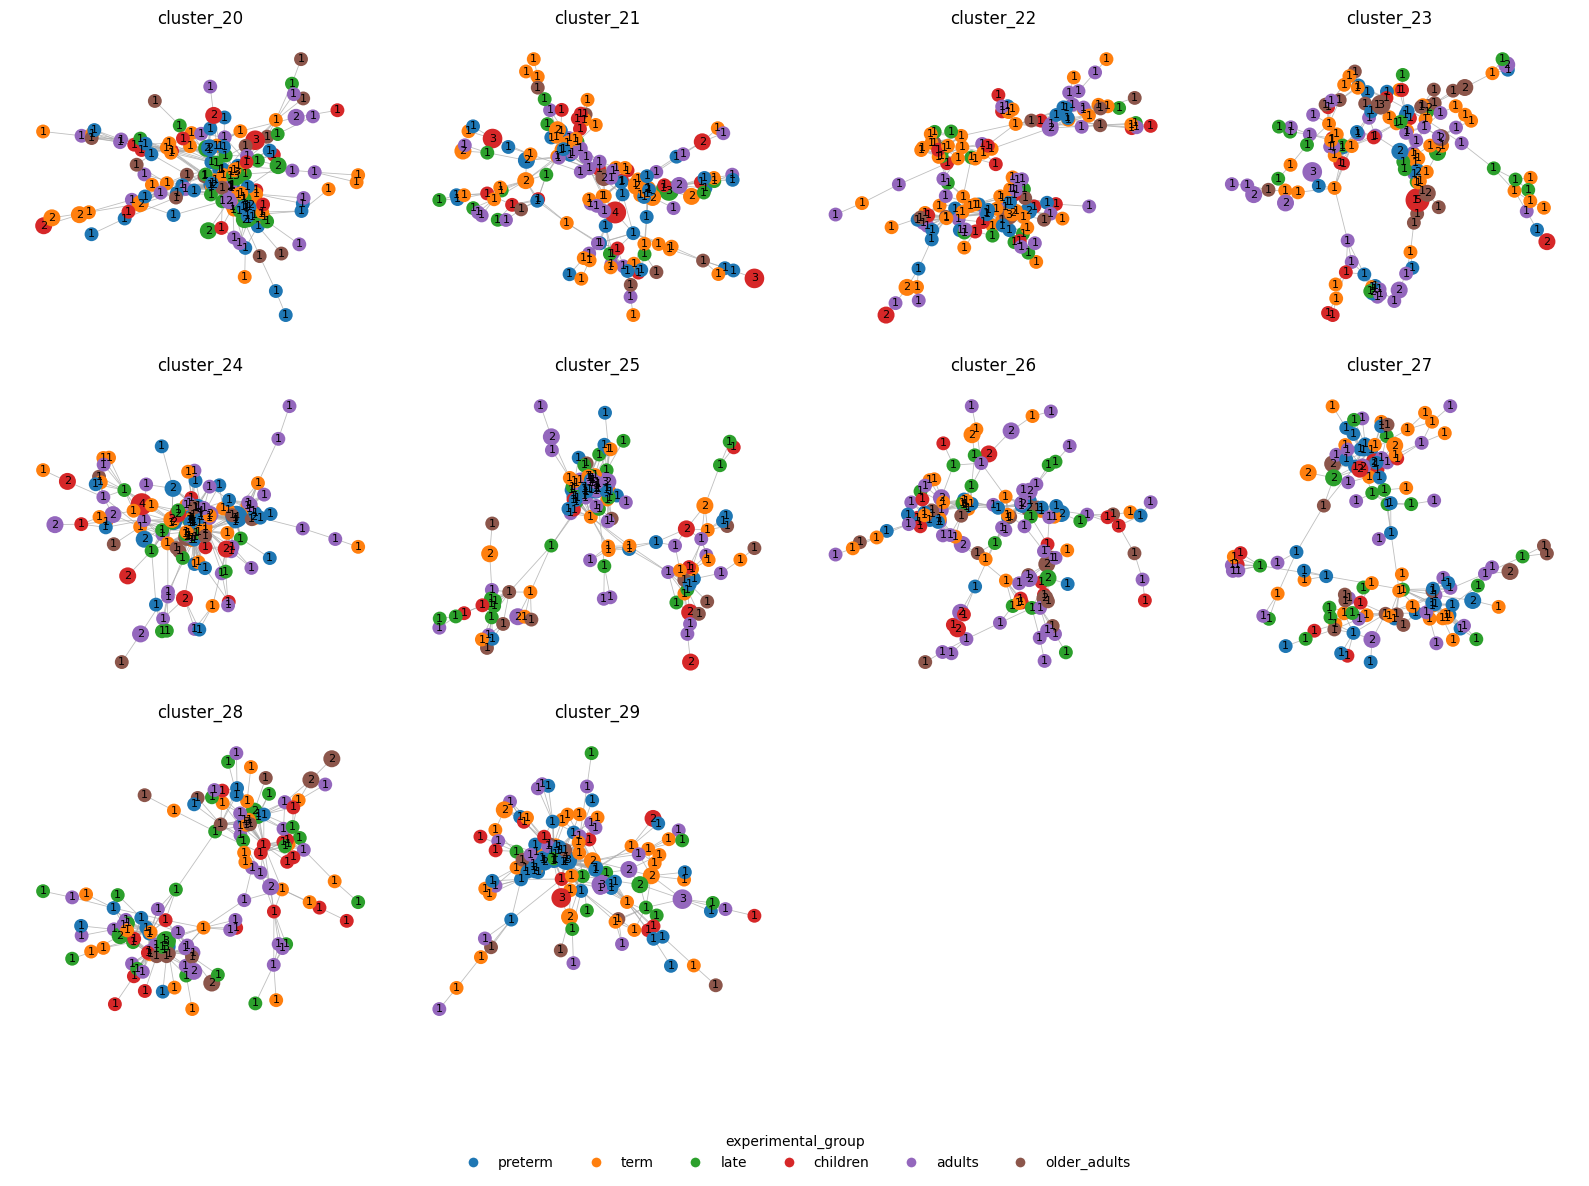

In [ ]:
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)


## Результаты

В следующей ячейке рассчитаны медианы по группам и сравнены результаты на двух глубинах. F2 показывает сходство репертуаров, а координаты MDS помогают представить их взаимное расположение. Кластеры aaV объединяют похожие последовательности, но сами по себе не доказывают общую антигенную специфичность.


In [ ]:
stats_table=diversity_stats.merge(metadata[['sample_id','experimental_group']],on='sample_id',validate='one_to_one')
summary=stats_table.groupby('experimental_group',observed=False)[['diversity','shannon_wiener','clonality','inverse_simpson']].median()
display(summary)
sensitivity=diversity_stats[['sample_id','diversity','shannon_wiener']].merge(
    diversity_half[['sample_id','diversity','shannon_wiener']],on='sample_id',suffixes=('_main','_half'),validate='one_to_one')
sensitivity['richness_ratio']=sensitivity.diversity_half/sensitivity.diversity_main
sensitivity['shannon_change']=sensitivity.shannon_wiener_half-sensitivity.shannon_wiener_main
display(sensitivity)
length_summary=cdr3_properties.merge(metadata[['sample_id','experimental_group']],on='sample_id',validate='one_to_one')
length_summary['mean_length_aa']=length_summary.mean_cdr3nt_len/3
display(length_summary.groupby('experimental_group',observed=False).mean_length_aa.median())
text=f'''## nCD4
В анализ включено {len(clonosets_cd4)} образцов. Основная глубина {depth}, дополнительная {half_depth}.
Медианное по образцам отношение богатств при уменьшении глубины составляет {sensitivity.richness_ratio.median():.3f}, изменение Shannon составляет {sensitivity.shannon_change.median():.3f}.
По групповым медианам наибольший Shannon наблюдается в {summary.shannon_wiener.idxmax()}, наименьший в {summary.shannon_wiener.idxmin()}.
Число кластеров с двумя и более вершинами: {int((cluster_properties.nodes>1).sum())}. Максимальный размер компоненты: {int(cluster_properties.nodes.max())}.
'''
display(Markdown(text))
(Path(WORKING_DIR)/'interpretation.md').write_text(text,encoding='utf-8')
for name,frame in {'samples':clonosets_cd4,'clonoset_stats':clonoset_stats_cd4,
    'cdr3_properties':cdr3_properties,'cdr3_lengths':cdr3_len_distribs,'v_usage':v_usage,
    'j_usage':j_usage,'convergence':convergence,'diversity':diversity_stats,
    'diversity_half':diversity_half,'rarefaction':rarefaction_points_ucb,
    'cluster_clonotypes':clusters_df,'cluster_properties':cluster_properties,
    'group_medians':summary.reset_index(),'sensitivity':sensitivity}.items():
    frame.to_csv(Path(WORKING_DIR)/(name+'.csv'),index=False)
beta_diversity['f2'].to_csv(Path(WORKING_DIR)/'f2.csv')
ucb_cd4_mds.to_csv(Path(WORKING_DIR)/'mds.csv',index=False)
del clusters,clusters_df,cluster_properties,beta_diversity
import gc
gc.collect()


,diversity,shannon_wiener,clonality,inverse_simpson
experimental_group,,,,
preterm,5536.0,8.593256,0.002990,5180.059524
term,5653.0,8.623416,0.001912,5419.667970
late,5595.0,8.610172,0.002254,5330.879025
children,5282.0,8.528063,0.004895,4799.614594
adults,5531.0,8.594143,0.002783,5211.077844
older_adults,5711.0,8.637443,0.001467,5527.687177


,sample_id,diversity_main,shannon_wiener_main,diversity_half,shannon_wiener_half,richness_ratio,shannon_change
0,a13_mnCD4_TRB_1,5631.0,8.618615,2875.0,7.953961,0.510567,-0.664654
1,a10_mnCD4_TRB_1,5590.0,8.608893,2872.0,7.952551,0.513775,-0.656342
2,c5_mnCD4_TRB_1,5635.0,8.618788,2870.0,7.950902,0.509317,-0.667886
3,UCB11_nCD4_TRB_1,5587.0,8.605209,2876.0,7.953491,0.514766,-0.651718
4,c4_mnCD4_TRB_1,4929.0,8.437339,2715.0,7.875618,0.550822,-0.561721
5,o6_mnCD4_TRB_2,5763.0,8.650340,2919.0,7.974815,0.506507,-0.675525
6,UCB10_nCD4_TRB_1,5770.0,8.651985,2921.0,7.975932,0.506239,-0.676052
7,a1_mnCD4_TRB_1,5458.0,8.575723,2824.0,7.929108,0.517406,-0.646615
8,UCB13_mnCD4_TRB_1,5663.0,8.625957,2886.0,7.958953,0.509624,-0.667004
9,UCB3_nCD4_TRB_1,5617.0,8.614971,2881.0,7.956781,0.512907,-0.658190


,mean_length_aa
experimental_group,
preterm,13.598977
term,14.158797
late,14.244979
children,14.355282
adults,14.564590
older_adults,14.487555


## nCD4
В анализ включено 30 образцов. Основная глубина 5900, дополнительная 2950.
Медианное по образцам отношение богатств при уменьшении глубины составляет 0.513, изменение Shannon составляет -0.658.
По групповым медианам наибольший Shannon наблюдается в older_adults, наименьший в children.
Число кластеров с двумя и более вершинами: 8520. Максимальный размер компоненты: 1204.


0

Для анализа использовали 30 образцов из шести групп. Глубину даунсэмплирования выбрали равной 5900 функциональным наблюдениям, чтобы сохранить все образцы. Дополнительно повторили расчёт на глубине 2950 и сравнили результаты.

В группе preterm CDR3 в среднем короче, чем в late: медианы средней взвешенной длины составили 13,60 и 14,24 аминокислоты соответственно. У preterm также меньше размер вставок и выше общая конвергенция. То есть разные нуклеотидные последовательности чаще кодируют одинаковые аминокислотные варианты CDR3. Такая картина согласуется с особенностями формирования репертуара на ранних этапах развития.

Среди наиболее представленных V-сегментов оказались TRBV5-1, TRBV20-1 и TRBV12-3, среди J-сегментов - TRBJ2-1, TRBJ2-7 и TRBJ2-3. При сравнении групп заметен и разброс между отдельными донорами. Поэтому по этим графикам можно описать различия, но нельзя утверждать, что они статистически значимы.

После выравнивания глубины последовательного снижения разнообразия с возрастом не видно. Медиана числа обнаруженных клонотипов меняется от 5282 в children до 5711 в older_adults. При уменьшении глубины вдвое обнаруживается медианно 51,3% от исходного числа клонотипов, снижается и Shannon. При этом общий вид различий между группами сохраняется.

Кривые rarefaction продолжают расти, поэтому увеличение глубины ещё позволяет находить редкие варианты. Значения F2 между разными донорами невелики относительно диагонали матрицы. На MDS группы перекрываются, чёткого разделения всех шести групп нет.

При кластеризации найдено 8520 компонент с двумя и более вершинами. В крупнейшей из них 1204 вершины. На показанных графах встречаются клонотипы разных возрастных групп. Это говорит о сходстве их последовательностей, однако общую антигенную специфичность по такому анализу установить нельзя.


# Анализ CD8

In [ ]:
WORKING_DIR=str(PROJECT/'results'/'nCD8')
os.makedirs(WORKING_DIR,exist_ok=True)


## Клоносеты

In [ ]:
clonosets_cd8 = clonosets.merge(metadata).query("subset == 'nCD8'").reset_index(drop=True)
clonosets_cd8


,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,c5_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,children,c5,nCD8,PB
1,o4_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,older_adults,o4,nCD8,PB
2,c1_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,children,c1,nCD8,PB
3,o2_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,older_adults,o2,nCD8,PB
4,UCB13_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB13,nCD8,UCB
5,UCB4_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB4,nCD8,UCB
6,UCB1_nCD8_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB1,nCD8,UCB
7,o1_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,older_adults,o1,nCD8,PB
8,UCB6_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB6,nCD8,UCB
9,UCB12_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,term,UCB12,nCD8,UCB


In [ ]:
display(clonosets_cd8.groupby('experimental_group',observed=False).size().rename('n').to_frame())


,n
experimental_group,
preterm,3
term,6
late,4
children,4
adults,4
older_adults,6


## Статистика

In [ ]:
clonoset_stats_cd8 = stats.calc_clonoset_stats(clonosets_cd8, cpu=2)
clonoset_stats_cd8


Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,c5_nCD8_TRB_1,TRB,35516,34463,27783,6680,1053,0.029649,44806,43652,1154,0.025755,NaN,NaN,NaN,NaN,NaN
1,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
2,c1_nCD8_TRB_1,TRB,47503,45987,32249,13738,1516,0.031914,68155,66536,1619,0.023755,NaN,NaN,NaN,NaN,NaN
3,o2_nCD8_TRB_1,TRB,7077,6818,6027,791,259,0.036597,8325,8056,269,0.032312,NaN,NaN,NaN,NaN,NaN
4,UCB13_nCD8_TRB_1,TRB,42841,41255,32843,8412,1586,0.037021,55050,53362,1688,0.030663,NaN,NaN,NaN,NaN,NaN
5,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN
6,UCB1_nCD8_TRB_2,TRB,43330,40913,23539,17374,2417,0.055781,76354,73563,2791,0.036553,NaN,NaN,NaN,NaN,NaN
7,o1_nCD8_TRB_1,TRB,35822,33909,25252,8657,1913,0.053403,49604,47469,2135,0.043041,NaN,NaN,NaN,NaN,NaN
8,UCB6_nCD8_TRB_1,TRB,39762,38299,20085,18214,1463,0.036794,72627,70976,1651,0.022733,NaN,NaN,NaN,NaN,NaN
9,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN


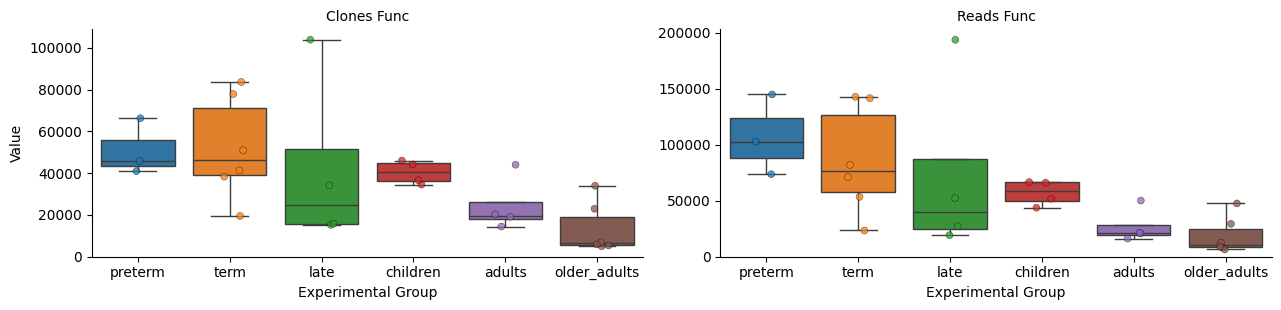

In [ ]:
rsplot.clonoset_stats(clonoset_stats_cd8, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)


In [ ]:
clonoset_stats_cd8.sort_values(by="reads_func")


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
13,o7_nCD8_TRB_1,TRB,5972,5823,5515,308,149,0.024950,6522,6368,154,0.023612,NaN,NaN,NaN,NaN,NaN
3,o2_nCD8_TRB_1,TRB,7077,6818,6027,791,259,0.036597,8325,8056,269,0.032312,NaN,NaN,NaN,NaN,NaN
26,o3_nCD8_TRB_1,TRB,5635,5332,3493,1839,303,0.053771,9313,8941,372,0.039944,NaN,NaN,NaN,NaN,NaN
1,o4_nCD8_TRB_1,TRB,5273,4931,2274,2657,342,0.064859,12971,12500,471,0.036312,NaN,NaN,NaN,NaN,NaN
24,a5_nCD8_TRB_1,TRB,15111,14377,12881,1496,734,0.048574,16879,16091,788,0.046685,NaN,NaN,NaN,NaN,NaN
16,UCB7_nCD8_TRB_1,TRB,16440,15764,13016,2748,676,0.041119,19808,19100,708,0.035743,NaN,NaN,NaN,NaN,NaN
18,a6_nCD8_TRB_1,TRB,19712,19070,17800,1270,642,0.032569,21232,20571,661,0.031132,NaN,NaN,NaN,NaN,NaN
20,a12_nCD8_TRB_1,TRB,20752,20166,19099,1067,586,0.028238,21981,21375,606,0.027569,NaN,NaN,NaN,NaN,NaN
9,UCB12_nCD8_TRB_1,TRB,20368,19465,16504,2961,903,0.044334,24244,23304,940,0.038772,NaN,NaN,NaN,NaN,NaN
5,UCB4_nCD8_TRB_1,TRB,15945,15199,8248,6951,746,0.046786,27886,27005,881,0.031593,NaN,NaN,NaN,NaN,NaN


In [ ]:
depth=int(clonoset_stats_cd8.reads_func.min()//100*100)
assert depth>1
half_depth=depth//2
print('Основная глубина:',depth,'; дополнительная:',half_depth)


Основная глубина: 6300 ; дополнительная: 3150


## Фильтры

In [ ]:
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=depth, by_umi=True, seed=100)


In [ ]:
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter


In [ ]:
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter


In [ ]:
downsample_filter = clf.Filter(functionality="f", downsample=depth, by_umi=True, seed=100)
downsample_filter


## CDR3 свойства

In [ ]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd8, cl_filter=func_filter, cpu=1)
cdr3_properties


Using 1 core
CalcCDR3aaProperties |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,c5_nCD8_TRB_1,TRB,42.744296,6.925158,0.026872,0.000029,-4.014302,-3.617472,-0.059677,-0.557042,...,5.904939,14.877178,4.486514,14.064015,4.791427,13.911549,0.288422,0.765138,2.427380,2.725190
1,o4_nCD8_TRB_1,TRB,43.345440,7.112000,0.025520,0.000203,-3.701512,-3.804624,0.075200,-0.489360,...,5.782857,14.944432,4.499513,14.259789,4.866736,14.214689,0.287841,0.777616,2.104160,2.466080
2,c1_nCD8_TRB_1,TRB,43.008672,7.370145,0.022018,0.000022,-3.909778,-3.416638,0.051341,-0.450538,...,5.842508,14.870714,4.489455,14.161060,4.822227,14.046562,0.288655,0.770913,2.335863,2.621648
3,o2_nCD8_TRB_1,TRB,43.014399,7.015641,0.024578,0.000147,-3.907833,-4.361470,-0.004469,-0.662984,...,5.863577,14.865843,4.483966,14.194882,4.822704,14.056503,0.289034,0.771607,2.317031,2.641261
4,UCB13_nCD8_TRB_1,TRB,42.122559,5.696076,0.086504,0.000024,-3.668463,-3.464806,-0.070706,-0.653986,...,5.867639,14.560540,4.505142,13.948072,4.812484,13.717956,0.290146,0.754900,2.276620,2.594243
5,UCB4_nCD8_TRB_1,TRB,42.294834,5.994483,0.061248,0.000066,-3.550628,-3.677452,-0.085021,-0.707684,...,5.884632,14.665745,4.494832,13.960893,4.812020,13.791584,0.289566,0.759499,2.267506,2.531124
6,UCB1_nCD8_TRB_2,TRB,40.757759,3.236641,0.268110,0.000024,-3.738162,-3.291969,-0.144244,-0.705151,...,5.884342,14.097323,4.483096,13.469358,4.842228,13.313068,0.293609,0.733226,2.162663,2.272664
7,o1_nCD8_TRB_1,TRB,43.324907,7.304388,0.025048,0.000029,-3.648183,-4.068196,-0.025575,-0.622575,...,5.849771,15.015972,4.495659,14.281683,4.825410,14.134755,0.288660,0.776980,2.257726,2.664560
8,UCB6_nCD8_TRB_1,TRB,42.541789,6.460846,0.044748,0.000026,-3.546183,-3.426323,-0.060556,-0.634102,...,5.859073,14.730095,4.505533,14.043847,4.815520,13.876357,0.289049,0.763096,2.259961,2.536843
9,UCB12_nCD8_TRB_1,TRB,42.765448,5.990474,0.068314,0.000051,-3.445503,-3.327922,0.026090,-0.513217,...,5.823235,14.805898,4.493573,14.077000,4.840383,13.972930,0.289971,0.769046,2.115560,2.385814


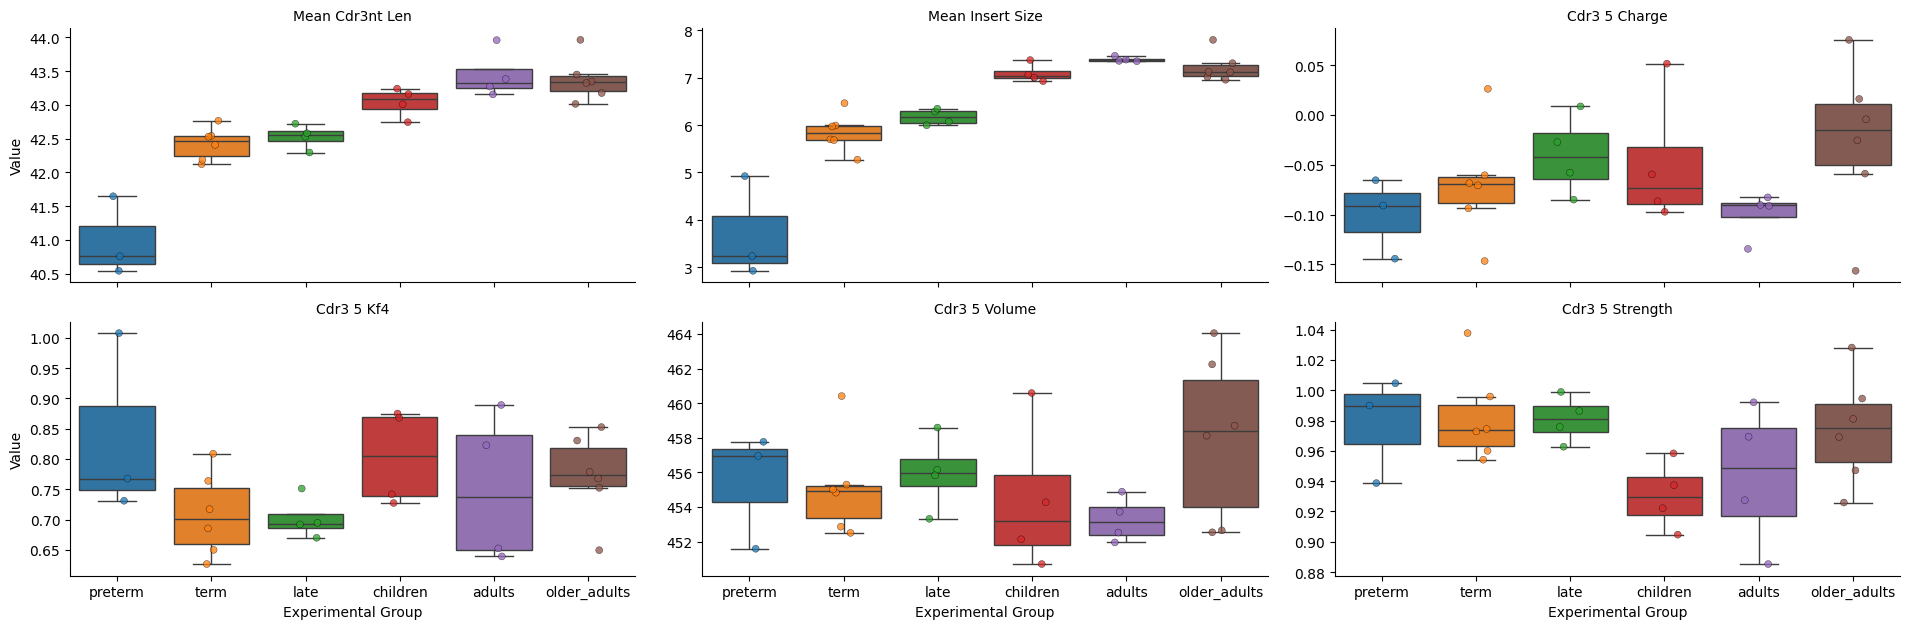

In [ ]:
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )


In [ ]:
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)


## CDR3len распределение

In [ ]:
preterm_late_cd8 = clonosets_cd8.query("experimental_group in ['preterm', 'late']")
preterm_late_cd8


,sample_id,chain,filename,experimental_group,donor_id,subset,source
5,UCB4_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB4,nCD8,UCB
6,UCB1_nCD8_TRB_2,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB1,nCD8,UCB
11,UCB8_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB8,nCD8,UCB
14,UCB5_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB5,nCD8,UCB
16,UCB7_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB7,nCD8,UCB
17,UCB9_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,late,UCB9,nCD8,UCB
19,UCB11_nCD8_TRB_1,TRB,/content/tcr_input/ImmuneSem/data/ucb_figshare...,preterm,UCB11,nCD8,UCB


In [ ]:
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_cd8,
                                                        cl_filter=func_filter,
                                                        cpu=2,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs


Using 2 cores
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD8_TRB_1,TRB,4,0.000014
1,UCB11_nCD8_TRB_1,TRB,5,0.000041
2,UCB11_nCD8_TRB_1,TRB,6,0.000035
3,UCB11_nCD8_TRB_1,TRB,7,0.000104
4,UCB11_nCD8_TRB_1,TRB,8,0.000801
...,...,...,...,...
163,UCB9_nCD8_TRB_1,TRB,23,0.000041
164,UCB9_nCD8_TRB_1,TRB,24,0.000016
165,UCB9_nCD8_TRB_1,TRB,26,0.000005
166,UCB9_nCD8_TRB_1,TRB,27,0.000005


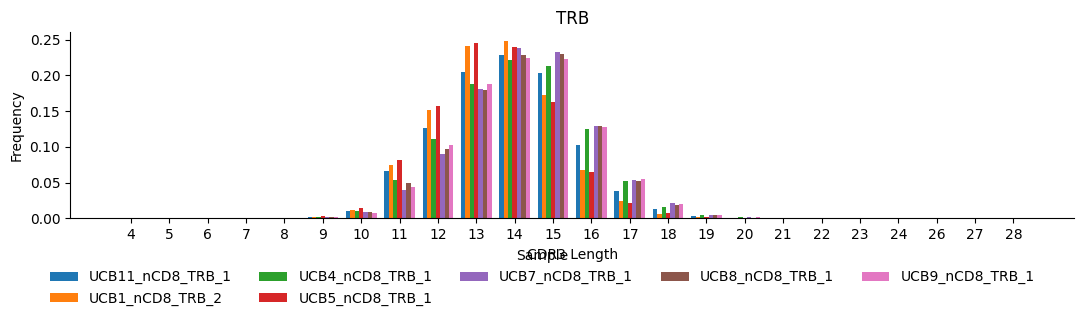

In [ ]:
rsplot.cdr3_length_distributions(cdr3_len_distribs)


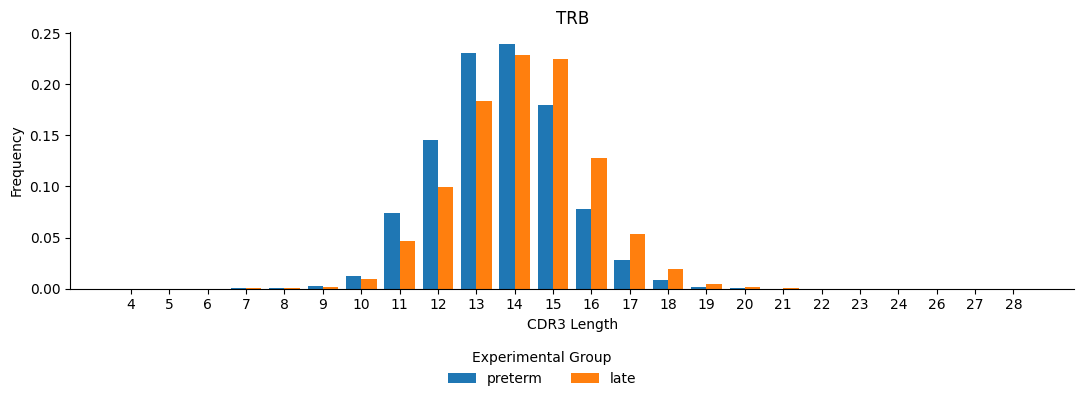

In [ ]:
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)


## V-usage

In [ ]:
v_usage = stats.calc_segment_usage(clonosets_cd8, segment="v", cl_filter=func_filter, table="long")
v_usage


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,v,usage
0,c5_nCD8_TRB_1,TRB,TRBV1,0.000092
1,o4_nCD8_TRB_1,TRB,TRBV1,0.000560
2,c1_nCD8_TRB_1,TRB,TRBV1,0.000180
3,o2_nCD8_TRB_1,TRB,TRBV1,0.000248
4,UCB13_nCD8_TRB_1,TRB,TRBV1,0.000169
...,...,...,...,...
1669,UCB3_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1670,a4_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1671,a5_nCD8_TRB_1,TRB,TRBV22-1,0.000000
1672,UCB2_nCD8_TRB_1,TRB,TRBV22-1,0.000000


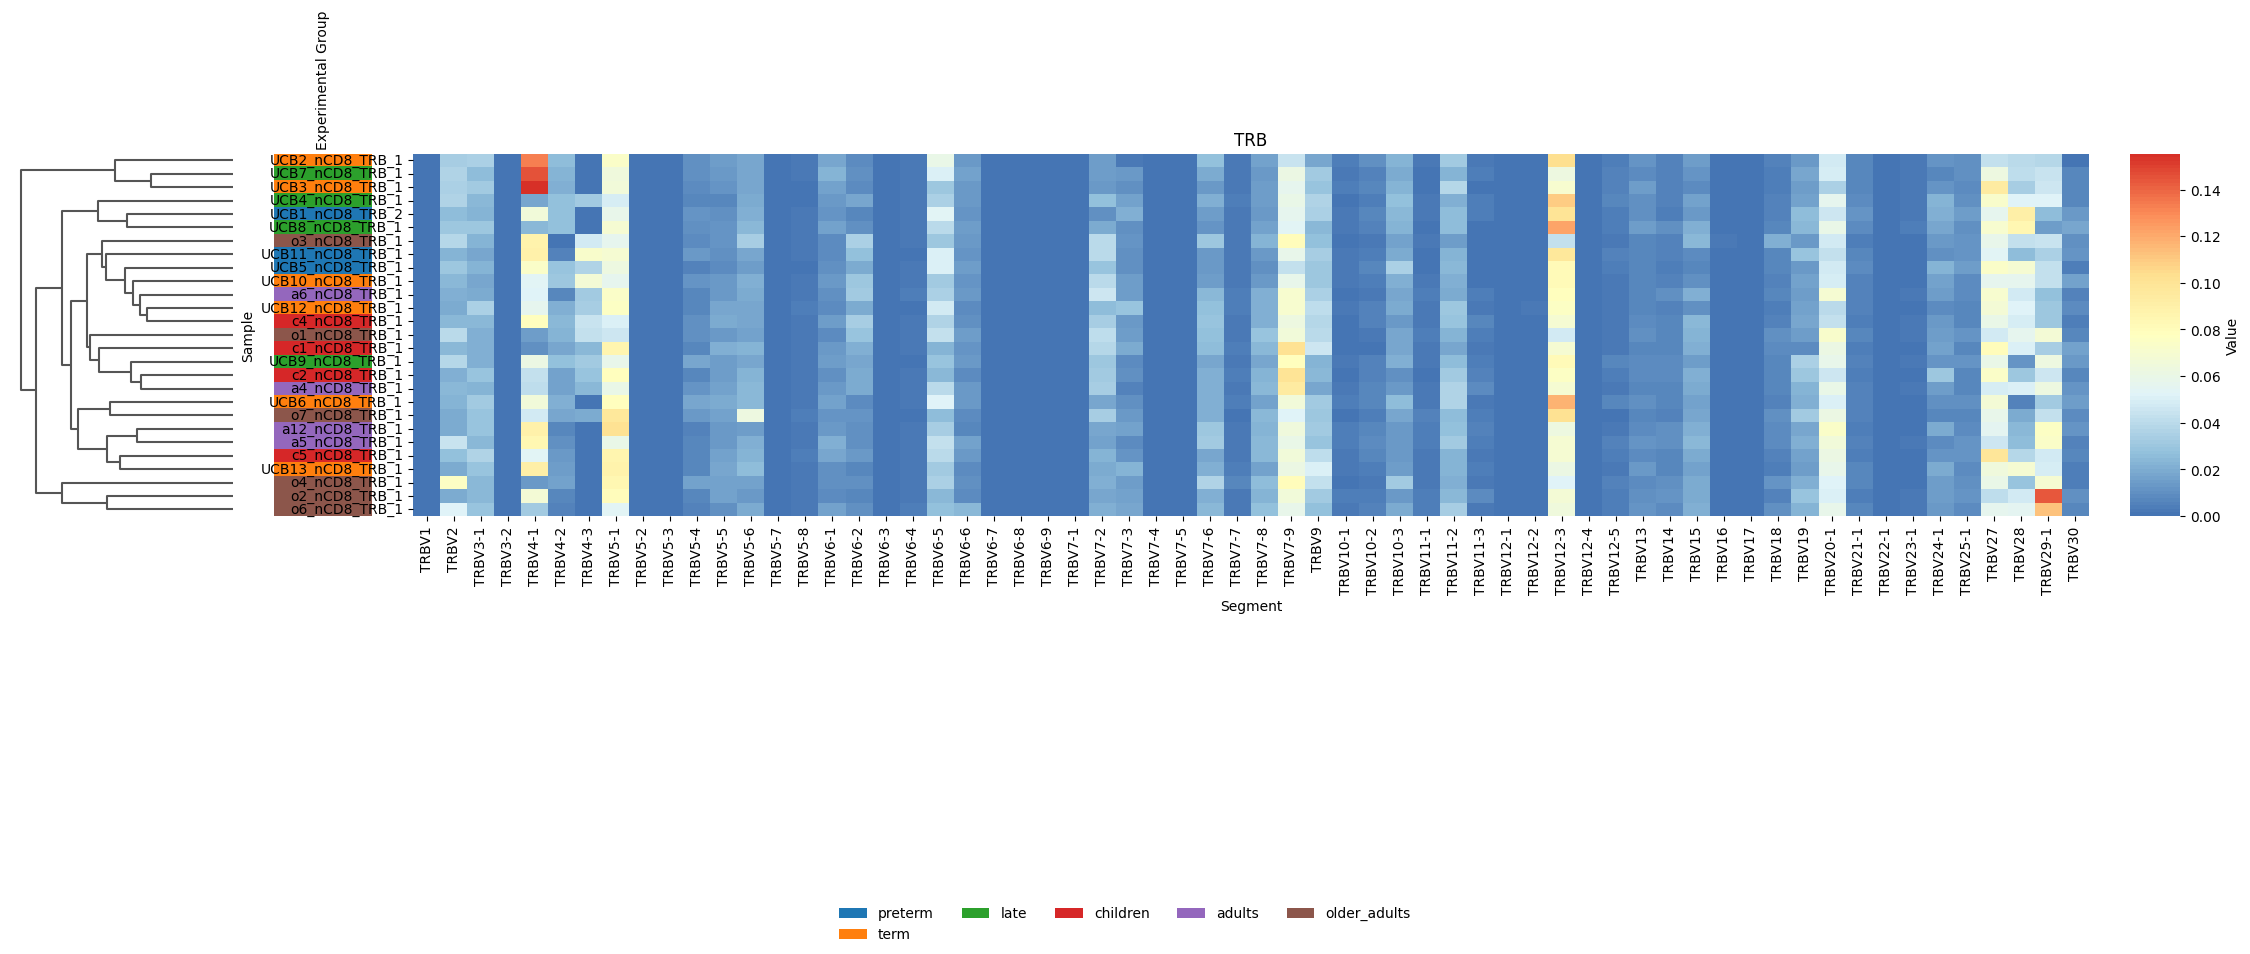

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)


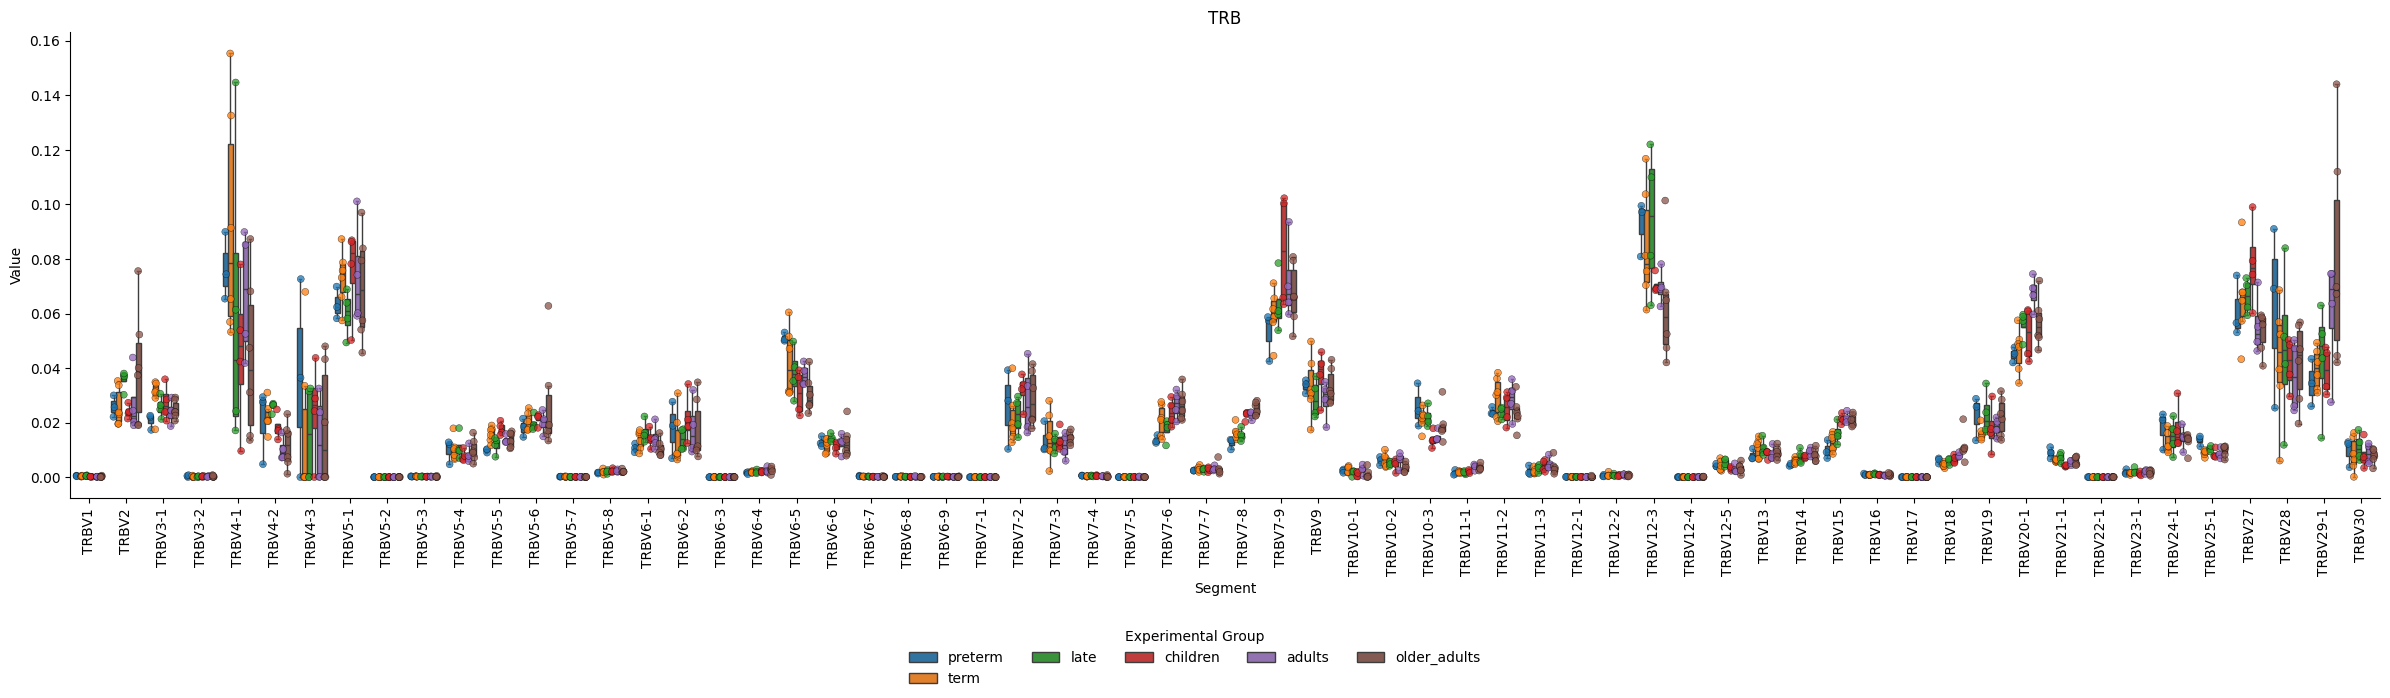

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )


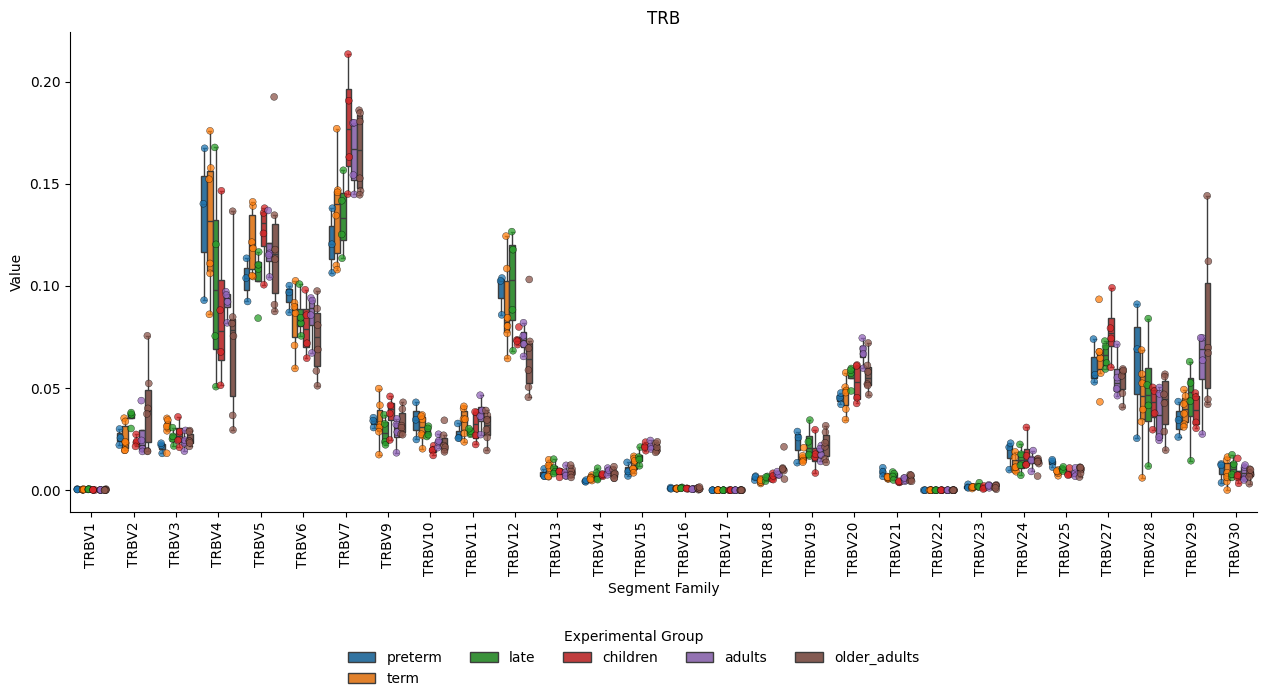

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)


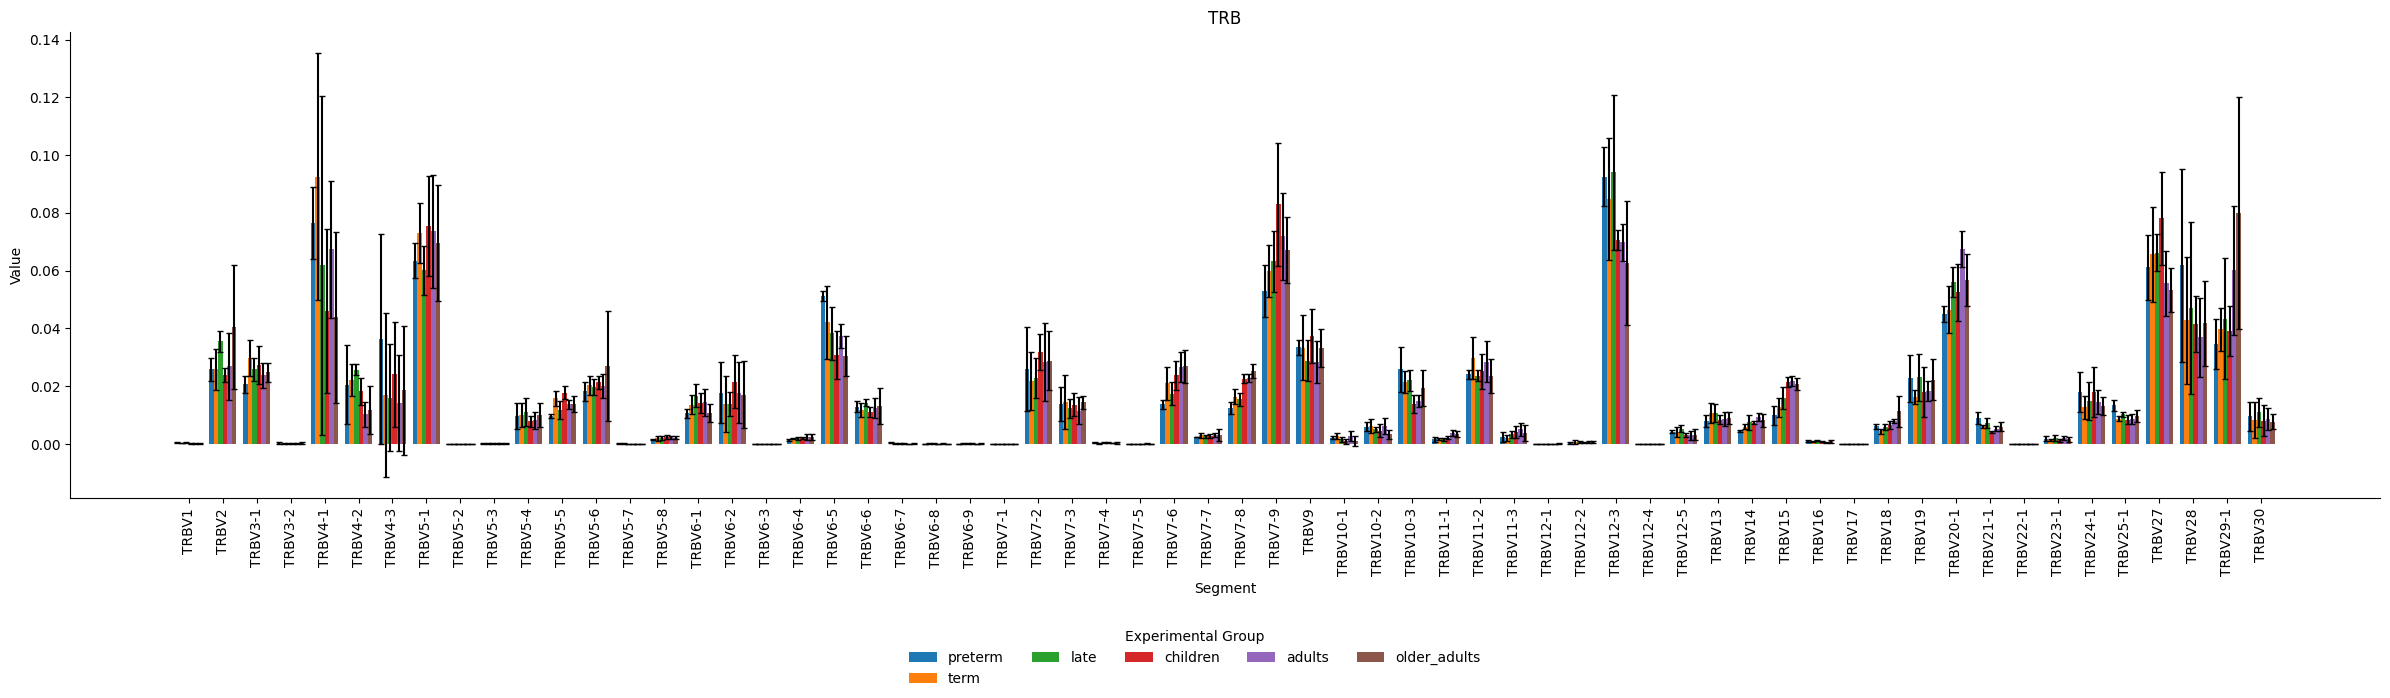

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)


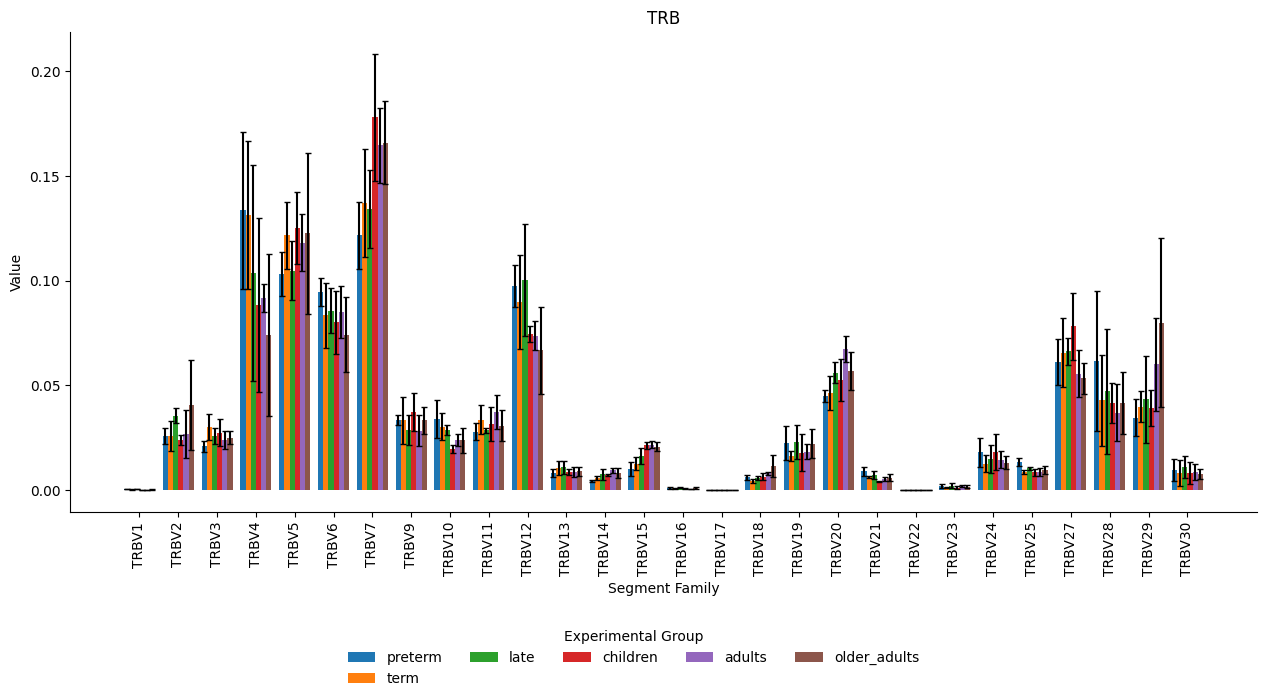

In [ ]:
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)


## J-usage

In [ ]:
j_usage = stats.calc_segment_usage(clonosets_cd8, segment="j", cl_filter=func_filter)
j_usage


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,j,usage
0,c5_nCD8_TRB_1,TRB,TRBJ1-1,0.154128
1,o4_nCD8_TRB_1,TRB,TRBJ1-1,0.075840
2,c1_nCD8_TRB_1,TRB,TRBJ1-1,0.144779
3,o2_nCD8_TRB_1,TRB,TRBJ1-1,0.094960
4,UCB13_nCD8_TRB_1,TRB,TRBJ1-1,0.076421
...,...,...,...,...
346,UCB3_nCD8_TRB_1,TRB,TRBJ2-7,0.288171
347,a4_nCD8_TRB_1,TRB,TRBJ2-7,0.238869
348,a5_nCD8_TRB_1,TRB,TRBJ2-7,0.147163
349,UCB2_nCD8_TRB_1,TRB,TRBJ2-7,0.138187


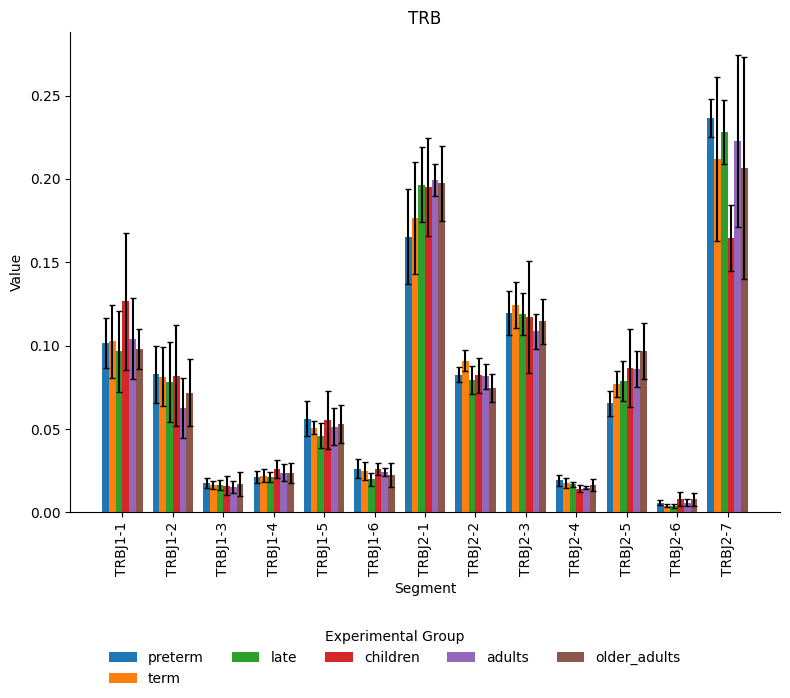

In [ ]:
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)


## Convergence

In [ ]:
convergence = stats.calc_convergence(clonosets_cd8,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence


CalcConvergence settings: seed=42, downsample=6300, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c5_nCD8_TRB_1, o4_nCD8_TRB_1, c1_nCD8_TRB_1, o2_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB1_nCD8_TRB_2, o1_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB12_nCD8_TRB_1, c4_nCD8_TRB_1, UCB8_nCD8_TRB_1, c2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, a6_nCD8_TRB_1, UCB11_nCD8_TRB_1, a12_nCD8_TRB_1, o6_nCD8_TRB_1, UCB3_nCD8_TRB_1, a4_nCD8_TRB_1, a5_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,c5_nCD8_TRB_1,TRB,1.005531,1.000667,1.000667
1,o4_nCD8_TRB_1,TRB,1.004557,1.002421,1.002421
2,c1_nCD8_TRB_1,TRB,1.003355,1.001004,1.001004
3,o2_nCD8_TRB_1,TRB,1.006630,1.001507,1.001507
4,UCB13_nCD8_TRB_1,TRB,1.013624,1.003538,1.003538
5,UCB4_nCD8_TRB_1,TRB,1.010703,1.001893,1.001893
6,UCB1_nCD8_TRB_2,TRB,1.087925,1.018127,1.018127
7,o1_nCD8_TRB_1,TRB,1.003970,1.001032,1.001032
8,UCB6_nCD8_TRB_1,TRB,1.010437,1.001378,1.001378
9,UCB12_nCD8_TRB_1,TRB,1.012172,1.002410,1.002410


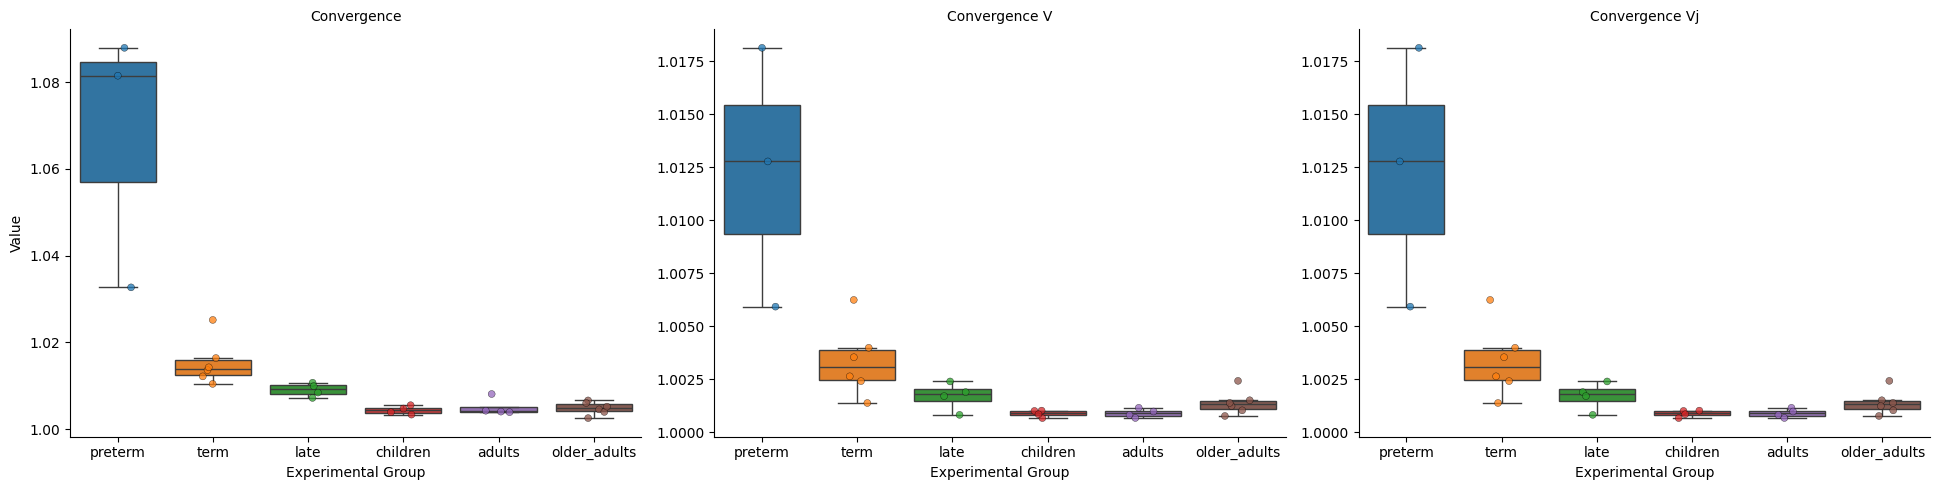

In [ ]:
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )


## Разнообразие

In [ ]:
diversity_stats = stats.calc_diversity_stats(clonosets_cd8,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False,
                                             verbose=True
                                            )
diversity_stats


CalcDiversityStats settings: seed=123, downsample=6300, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c5_nCD8_TRB_1, o4_nCD8_TRB_1, c1_nCD8_TRB_1, o2_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB1_nCD8_TRB_2, o1_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB12_nCD8_TRB_1, c4_nCD8_TRB_1, UCB8_nCD8_TRB_1, c2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, a6_nCD8_TRB_1, UCB11_nCD8_TRB_1, a12_nCD8_TRB_1, o6_nCD8_TRB_1, UCB3_nCD8_TRB_1, a4_nCD8_TRB_1, a5_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,c5_nCD8_TRB_1,TRB,6069.0,0.998358,0.001642,8.696644,87095.672986,6069.0,86826.220717,0.071746,0.480969,0.000171,5852.255972,0.999829,0.000476,0.035387
1,o4_nCD8_TRB_1,TRB,3416.0,0.957828,0.042172,7.793108,6298.050136,3416.0,6504.411087,0.672540,0.237119,0.001476,677.511864,0.998524,0.031270,0.349477
2,c1_nCD8_TRB_1,TRB,6033.0,0.998121,0.001879,8.688639,74130.861224,6033.0,73939.652352,0.083016,0.477872,0.000173,5789.089848,0.999827,0.000476,0.040653
3,o2_nCD8_TRB_1,TRB,5476.0,0.986790,0.013210,8.494414,33280.388636,5476.0,38939.457874,0.214762,0.424763,0.000361,2772.035200,0.999639,0.010000,0.122380
4,UCB13_nCD8_TRB_1,TRB,6066.0,0.998310,0.001690,8.695734,88177.009615,6066.0,87677.466509,0.072222,0.480712,0.000171,5841.919341,0.999829,0.000476,0.035860
5,UCB4_nCD8_TRB_1,TRB,5364.0,0.993518,0.006482,8.531804,19699.688889,5364.0,19844.560015,0.278730,0.412752,0.000213,4703.721261,0.999787,0.000794,0.128371
6,UCB1_nCD8_TRB_2,TRB,5817.0,0.996197,0.003803,8.635571,45645.688525,5817.0,46980.073821,0.142857,0.458484,0.000187,5337.547068,0.999813,0.000794,0.071847
7,o1_nCD8_TRB_1,TRB,5903.0,0.996278,0.003722,8.650893,60060.142857,5903.0,65800.191982,0.114921,0.466373,0.000189,5293.411576,0.999811,0.002540,0.060094
8,UCB6_nCD8_TRB_1,TRB,5838.0,0.996488,0.003512,8.641689,43164.300254,5838.0,43787.901989,0.140159,0.460432,0.000186,5370.771313,0.999814,0.001746,0.068492
9,UCB12_nCD8_TRB_1,TRB,5952.0,0.997492,0.002508,8.669681,58557.906977,5952.0,58383.499365,0.106667,0.470766,0.000178,5632.983253,0.999822,0.000635,0.052424


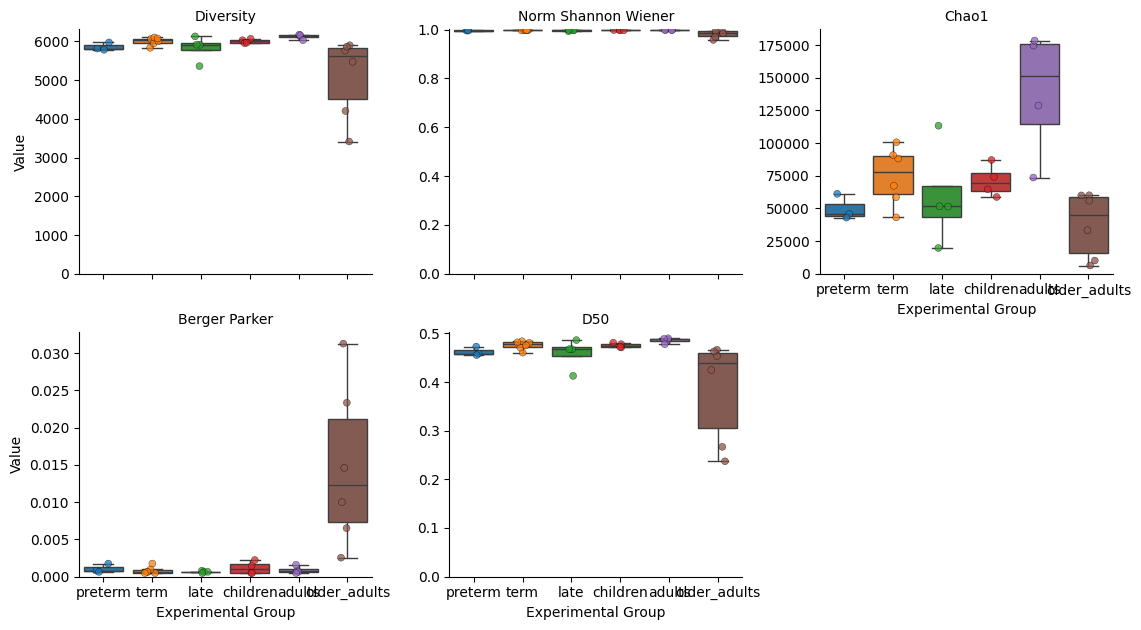

In [ ]:
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )


## Downsample sensitivity

CalcDiversityStats settings: seed=123, downsample=3150, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): c5_nCD8_TRB_1, o4_nCD8_TRB_1, c1_nCD8_TRB_1, o2_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB1_nCD8_TRB_2, o1_nCD8_TRB_1, UCB6_nCD8_TRB_1, UCB12_nCD8_TRB_1, c4_nCD8_TRB_1, UCB8_nCD8_TRB_1, c2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB5_nCD8_TRB_1, UCB10_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, a6_nCD8_TRB_1, UCB11_nCD8_TRB_1, a12_nCD8_TRB_1, o6_nCD8_TRB_1, UCB3_nCD8_TRB_1, a4_nCD8_TRB_1, a5_nCD8_TRB_1, UCB2_nCD8_TRB_1, o3_nCD8_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,c5_nCD8_TRB_1,TRB,3091.0,0.999060,0.000940,8.028694,89960.716981,3091.0,89521.538629,0.036508,0.490456,0.000330,3030.696396,0.999670,0.000952,0.018407
1,o4_nCD8_TRB_1,TRB,2161.0,0.968294,0.031706,7.434880,5134.785714,2161.0,5731.993802,0.498095,0.271171,0.001539,649.973798,0.998461,0.029524,0.260000
2,c1_nCD8_TRB_1,TRB,3077.0,0.998919,0.001081,8.023031,64864.753425,3077.0,66387.328767,0.046349,0.488138,0.000332,3010.467233,0.999668,0.000635,0.022625
3,o2_nCD8_TRB_1,TRB,2868.0,0.990648,0.009352,7.886912,27621.534247,2868.0,32279.376644,0.146349,0.450837,0.000512,1954.017330,0.999488,0.009524,0.085810
4,UCB13_nCD8_TRB_1,TRB,3084.0,0.998938,0.001062,8.025447,81786.258621,3084.0,81188.444031,0.040635,0.489300,0.000332,3015.957447,0.999668,0.000952,0.020555
5,UCB4_nCD8_TRB_1,TRB,2902.0,0.996207,0.003793,7.942917,19655.314554,2902.0,19643.996190,0.151746,0.457271,0.000371,2693.403909,0.999629,0.001270,0.072912
6,UCB1_nCD8_TRB_2,TRB,3024.0,0.997967,0.002033,7.998045,42899.264151,3024.0,42365.579573,0.076825,0.479167,0.000345,2899.620105,0.999655,0.000952,0.038577
7,o1_nCD8_TRB_1,TRB,3028.0,0.997453,0.002547,7.995244,54726.614458,3028.0,65947.599382,0.069841,0.479855,0.000353,2833.380925,0.999647,0.003175,0.037698
8,UCB6_nCD8_TRB_1,TRB,3026.0,0.997937,0.002063,7.998463,43808.000000,3026.0,44829.005719,0.075238,0.479511,0.000345,2896.234676,0.999655,0.001587,0.038017
9,UCB12_nCD8_TRB_1,TRB,3046.0,0.998314,0.001686,8.008059,52475.261364,3046.0,51847.899651,0.063492,0.482928,0.000340,2940.871369,0.999660,0.000952,0.032049


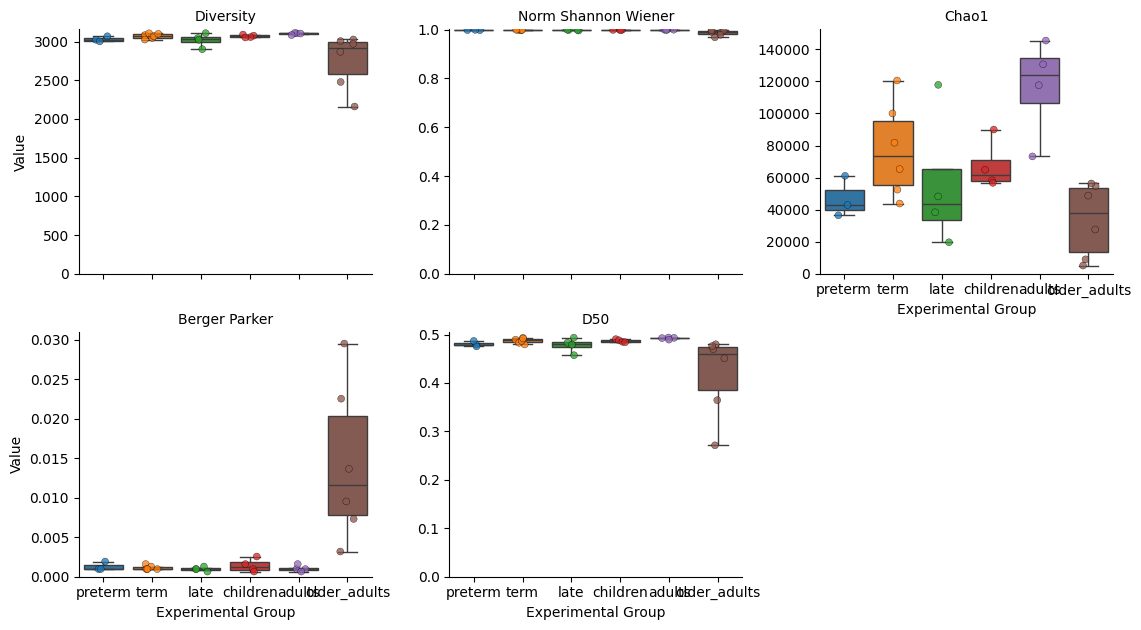

In [ ]:
smaller_filter=clf.Filter(functionality='f',downsample=half_depth,by_umi=True,seed=100)
diversity_half=stats.calc_diversity_stats(clonosets_cd8,cl_filter=smaller_filter,
    seed=123,cpu=2,iterations=3,drop_small_samples=False,verbose=True)
display(diversity_half)
rsplot.diversity_stats(diversity_half,metadata=metadata,group='experimental_group')


## Rarefaction

In [ ]:
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd8, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb


Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 27/27 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD8_TRB_1,TRB,32,32.000000
1,UCB10_nCD8_TRB_1,TRB,100,100.000000
2,UCB10_nCD8_TRB_1,TRB,316,315.666667
3,UCB10_nCD8_TRB_1,TRB,1000,994.666667
4,UCB10_nCD8_TRB_1,TRB,3162,3107.333333
...,...,...,...,...
202,o7_nCD8_TRB_1,TRB,100,99.000000
203,o7_nCD8_TRB_1,TRB,316,304.333333
204,o7_nCD8_TRB_1,TRB,1000,962.000000
205,o7_nCD8_TRB_1,TRB,3162,2977.666667


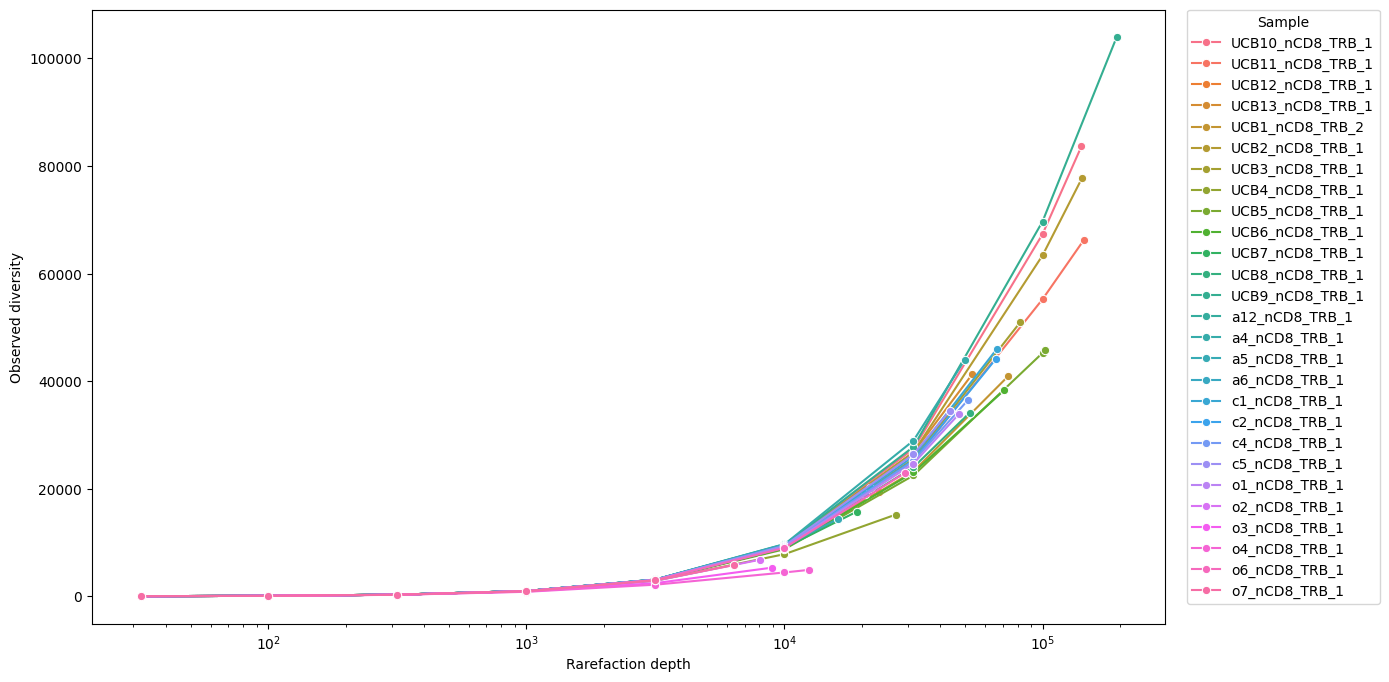

In [ ]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)


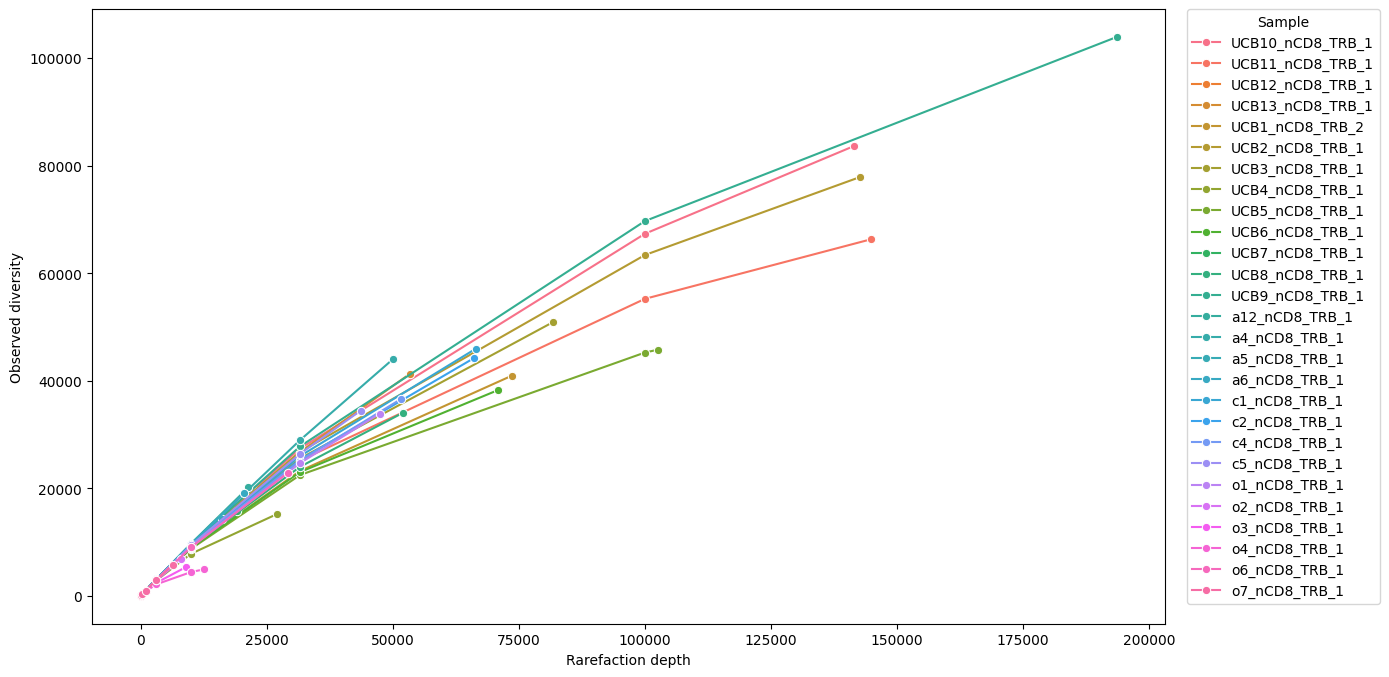

In [ ]:
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)


## Бета-разнообразие

In [ ]:
beta_diversity = beta.metrics(clonosets_cd8,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=2                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )


Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 27/27 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 351/351 pairs processed


In [ ]:
beta_diversity.keys()


dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [ ]:
beta_diversity["f2"]


sample2,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB12_nCD8_TRB_1,UCB13_nCD8_TRB_1,UCB1_nCD8_TRB_2,UCB2_nCD8_TRB_1,UCB3_nCD8_TRB_1,UCB4_nCD8_TRB_1,UCB5_nCD8_TRB_1,UCB6_nCD8_TRB_1,...,c1_nCD8_TRB_1,c2_nCD8_TRB_1,c4_nCD8_TRB_1,c5_nCD8_TRB_1,o1_nCD8_TRB_1,o2_nCD8_TRB_1,o3_nCD8_TRB_1,o4_nCD8_TRB_1,o6_nCD8_TRB_1,o7_nCD8_TRB_1
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD8_TRB_1,1.000000,0.010267,0.004599,0.007024,0.014318,0.005447,0.008859,0.005977,0.021850,0.003964,...,0.002737,0.001978,0.002578,0.002261,0.002803,0.002919,0.000701,0.000859,0.000476,0.003438
UCB11_nCD8_TRB_1,0.010267,1.000000,0.009350,0.009033,0.026338,0.009221,0.012084,0.007041,0.033791,0.008011,...,0.003465,0.002830,0.001905,0.004030,0.002830,0.004972,0.001134,0.001200,0.002694,0.005296
UCB12_nCD8_TRB_1,0.004599,0.009350,1.000000,0.003713,0.014813,0.002491,0.005613,0.004989,0.016190,0.002443,...,0.000859,0.001243,0.001518,0.002102,0.001560,0.003502,0.001134,0.000976,0.001018,0.001719
UCB13_nCD8_TRB_1,0.007024,0.009033,0.003713,1.000000,0.012878,0.005335,0.008652,0.005233,0.015178,0.003922,...,0.002536,0.002362,0.001587,0.001812,0.001769,0.002448,0.001452,0.001266,0.002512,0.001971
UCB1_nCD8_TRB_2,0.014318,0.026338,0.014813,0.012878,1.000000,0.014464,0.023349,0.012263,0.059522,0.012382,...,0.003368,0.005678,0.003778,0.006263,0.003554,0.006084,0.002466,0.002038,0.004297,0.004884
UCB2_nCD8_TRB_1,0.005447,0.009221,0.002491,0.005335,0.014464,1.000000,0.007336,0.004593,0.012658,0.005704,...,0.002261,0.002830,0.001177,0.003531,0.000897,0.002354,0.000592,0.000804,0.002311,0.003438
UCB3_nCD8_TRB_1,0.008859,0.012084,0.005613,0.008652,0.023349,0.007336,1.000000,0.006460,0.024016,0.005830,...,0.002102,0.001976,0.003054,0.004970,0.001270,0.003209,0.001545,0.002139,0.002152,0.002671
UCB4_nCD8_TRB_1,0.005977,0.007041,0.004989,0.005233,0.012263,0.004593,0.006460,1.000000,0.014126,0.002152,...,0.001560,0.001478,0.001467,0.003799,0.001885,0.002108,0.002059,0.001243,0.002036,0.002512
UCB5_nCD8_TRB_1,0.021850,0.033791,0.016190,0.015178,0.059522,0.012658,0.024016,0.014126,1.000000,0.010774,...,0.003022,0.005151,0.003147,0.003910,0.004080,0.008716,0.001951,0.001841,0.002643,0.005048


In [ ]:
beta_diversity["full_table"].query("pair == 'UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1'")


,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CSAKEGPGTDTQYF,TRBV20-1,1,0,0.000159,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
1,CASSLAQMAYNEQFF,TRBV12-3,0,1,0.000000,0.000159,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
2,CASSYQGTLFYNEQFF,TRBV6-2,0,1,0.000000,0.000159,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
3,CASSIPLAGEQFF,TRBV19,0,2,0.000000,0.000317,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
4,CASSDRTGPRGTEAFF,TRBV6-7,1,0,0.000159,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
...,...,...,...,...,...,...,...,...,...
11915,CASSSYLYNEQFF,TRBV12-3,1,0,0.000159,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11916,CASSSGGLNQPQHF,TRBV12-3,0,1,0.000000,0.000159,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11917,CASSPPSRMANEKLFF,TRBV5-6,0,1,0.000000,0.000159,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1
11918,CASRQNTEAFF,TRBV23-1,1,0,0.000159,0.000000,UCB10_nCD8_TRB_1,UCB11_nCD8_TRB_1,UCB10_nCD8_TRB_1_vs_UCB11_nCD8_TRB_1


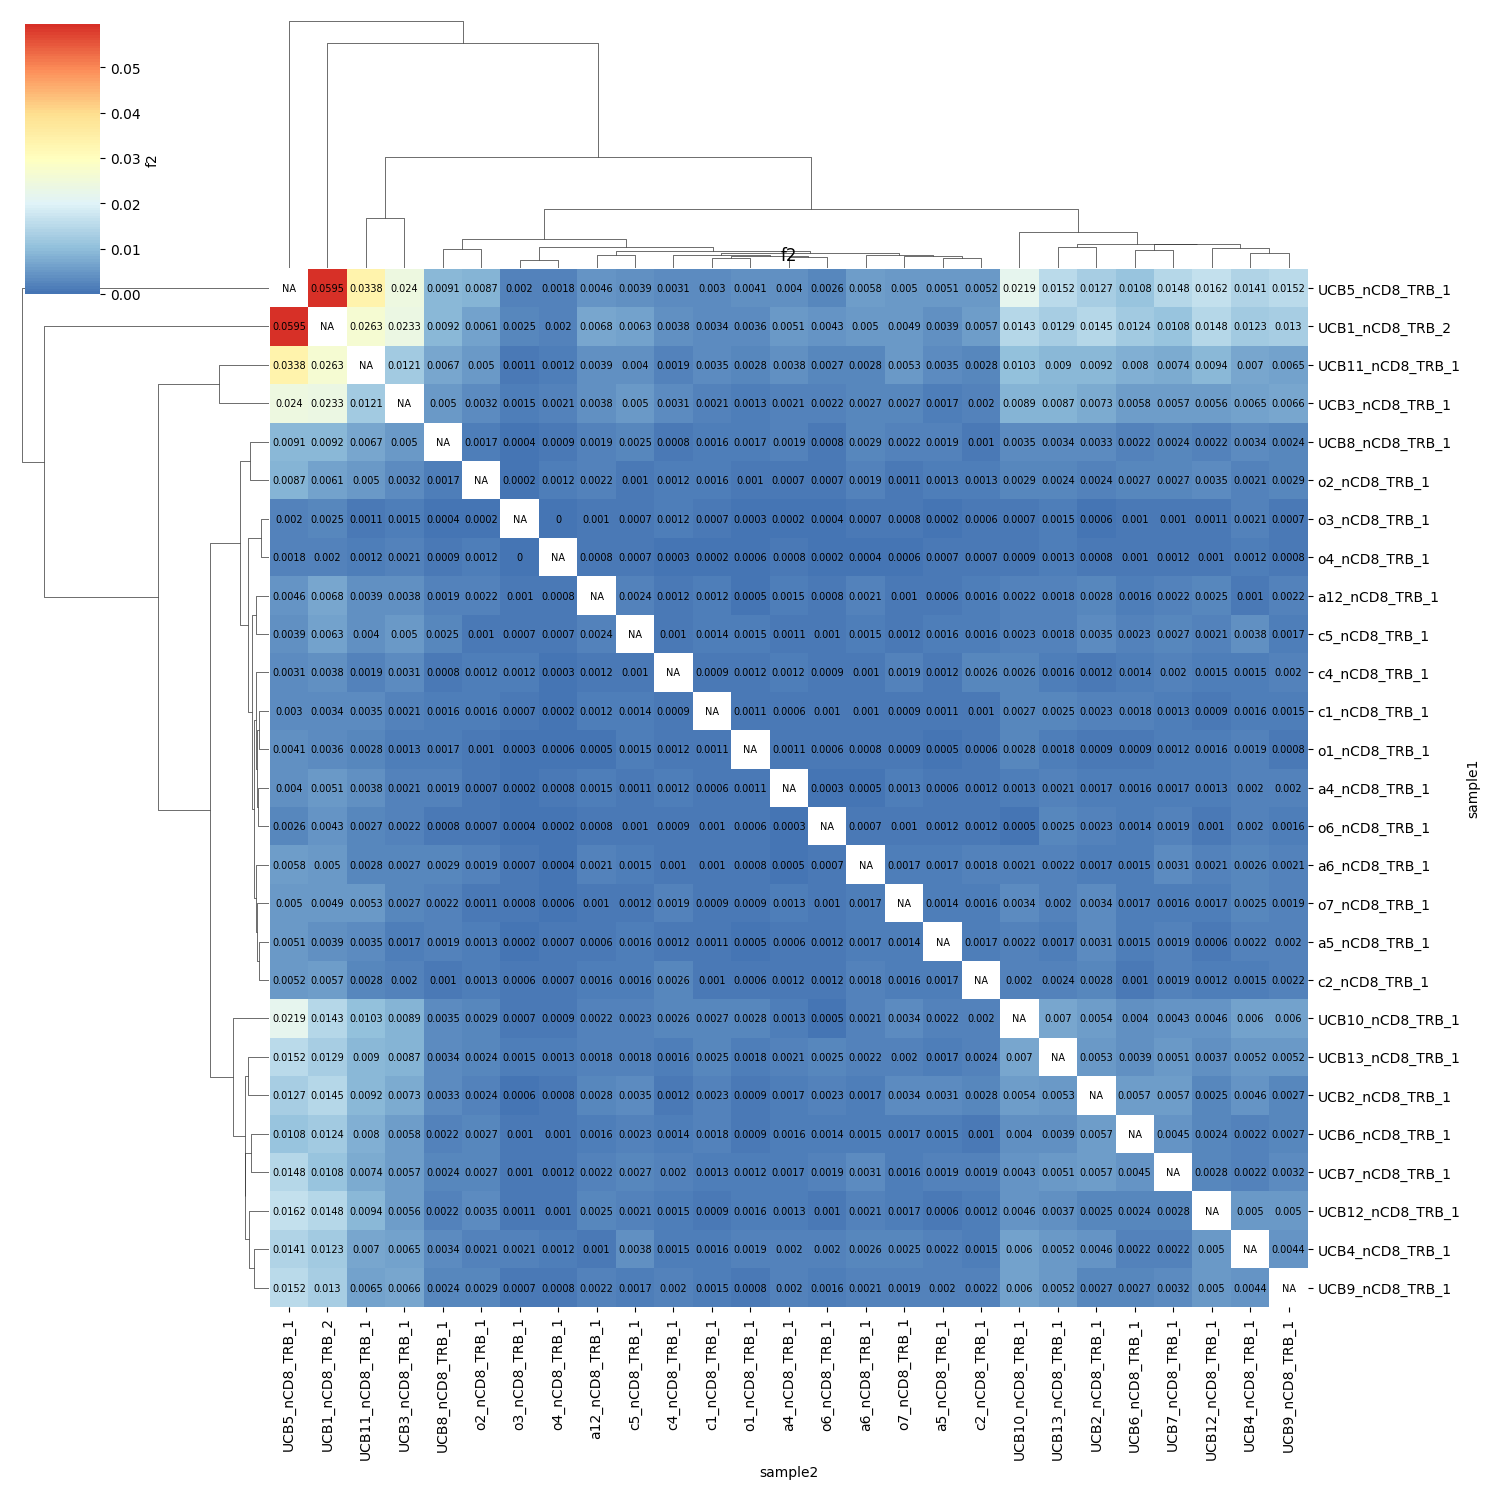

In [ ]:
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )


In [ ]:
ucb_cd8_mds = beta.mds(beta_diversity)
ucb_cd8_mds


,sample_id,MDS1,MDS2
0,UCB10_nCD8_TRB_1,0.078945,-0.455092
1,UCB11_nCD8_TRB_1,0.059486,-0.083662
2,UCB12_nCD8_TRB_1,-0.073102,-0.809802
3,UCB13_nCD8_TRB_1,-0.082867,-0.027155
4,UCB1_nCD8_TRB_2,-0.049140,-0.127661
5,UCB2_nCD8_TRB_1,0.086303,0.514801
6,UCB3_nCD8_TRB_1,0.007346,-0.206253
7,UCB4_nCD8_TRB_1,-0.148788,-0.150913
8,UCB5_nCD8_TRB_1,0.039982,-0.166271
9,UCB6_nCD8_TRB_1,0.024688,0.019250


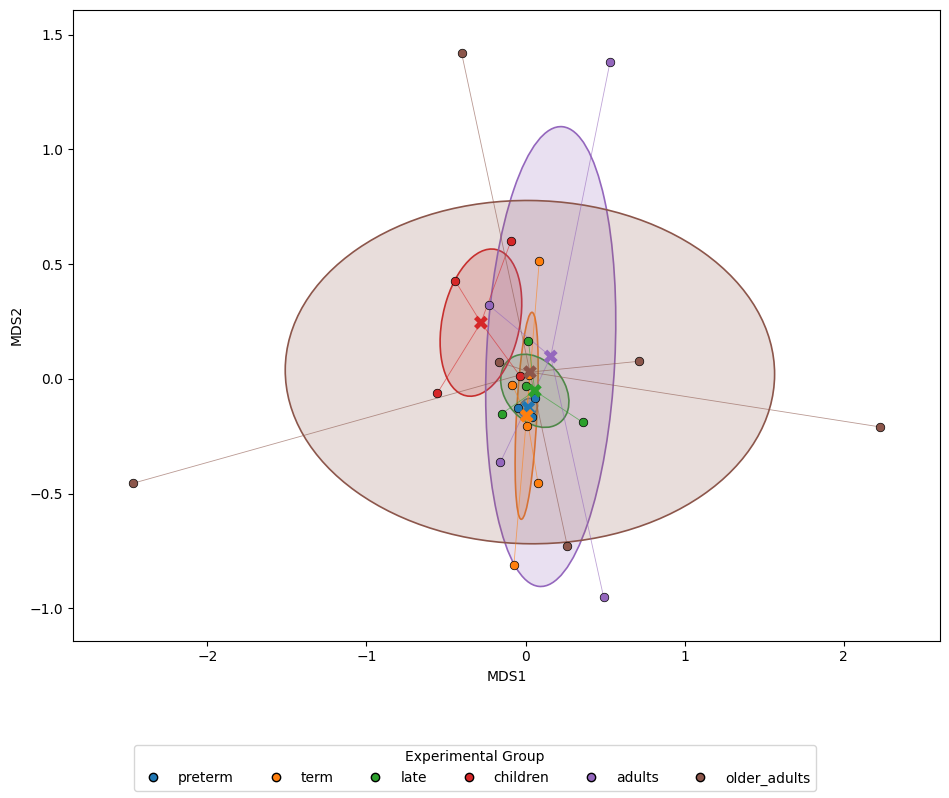

In [ ]:
rsplot.beta_mds(ucb_cd8_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)


## Кластеризация

In [ ]:
clusters = clustering.Clusters()
clusters


Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [ ]:
clusters.read_from_clonosets_df(clonosets_cd8, cl_filter=downsample_filter)


Pooled 156113 clonotypes from 27 samples


In [ ]:
clusters.create_clusters(overlap_type='aaV', mismatches=1, cpu=1)


Nodes list created: 156113 nodes
Using 1 core
Find neighbour clonotypes |##################################################| 737/737 tasks processed
found 97099 edges
-----------------------------
NexworkX graph created
Found 8282 clusters (2 or more nodes) and 112542 single nodes. Total: 120824


In [ ]:
clusters.add_metadata(metadata)


In [ ]:
clusters_df = clusters.as_dataframe()
clusters_df


,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,121188,CASSPSGDEQFF,TRBV12-3,TRBJ2-1,TGTGCCAGCAGTCCCTCAGGGGATGAGCAGTTCTTC,a12_nCD8_TRB_1,0.000159,1,None,2,adults,a12,nCD8,PB
1,0,140670,CASSLTGNEQFF,TRBV12-3,TRBJ2-1,TGTGCCAGCAGTTTAACCGGGAATGAGCAGTTCTTC,a5_nCD8_TRB_1,0.000159,1,None,23,adults,a5,nCD8,PB
2,0,134754,CASSPGWTEAFF,TRBV12-3,TRBJ1-1,TGTGCCAGCAGCCCCGGATGGACTGAAGCTTTCTTT,a4_nCD8_TRB_1,0.000159,1,None,3,adults,a4,nCD8,PB
3,0,81409,CASSLAGVEQFF,TRBV12-3,TRBJ2-1,TGTGCCAGCAGTTTAGCGGGAGTTGAGCAGTTCTTC,UCB5_nCD8_TRB_1,0.000159,1,None,5,preterm,UCB5,nCD8,UCB
4,0,140671,CASSLVGYEQYF,TRBV12-3,TRBJ2-7,TGTGCCAGCAGTTTGGTAGGCTACGAGCAGTACTTC,a5_nCD8_TRB_1,0.000159,1,None,25,adults,a5,nCD8,PB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156108,120819,79564,WREDTQYF,TRBV19,TRBJ2-3,TGGCGGGAAGATACGCAGTATTTT,o7_nCD8_TRB_1,0.000159,1,None,0,older_adults,o7,nCD8,PB
156109,120820,44126,WVAGLTGELFF,TRBV28,TRBJ2-2,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,o1_nCD8_TRB_1,0.000159,1,None,0,older_adults,o1,nCD8,PB
156110,120821,85219,YAIRDRGYEQYF,TRBV10-3,TRBJ2-7,TATGCCATCAGGGACAGGGGATACGAGCAGTACTTC,UCB5_nCD8_TRB_1,0.000159,1,None,0,preterm,UCB5,nCD8,UCB
156111,120822,107964,YSARGQENTGELFF,TRBV20-1,TRBJ2-2,TACAGTGCTCGGGGACAGGAGAACACCGGGGAGCTGTTTTTT,a6_nCD8_TRB_1,0.000159,1,None,0,adults,a6,nCD8,PB


In [ ]:
cluster_properties = clusters.properties(cpu=1)
cluster_properties


Using 1 core
Calculating cluster properties |##################################################| 120824/120824 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,835,4328,932,23,0.012430,16.548503,CASSLGGYEQYF,TGTGCCAGCAGTTTAGGGGGCGATGAGCAGTACTTC,TRBV12-3,TRBJ2-7
1,1,cluster_1,744,5153,828,22,0.018644,14.970430,CASSLGGYEQFF,TGTGCCAGCAGCTTAGGGGGCAATGAGCAGTTCTTC,TRBV7-9,TRBJ2-7
2,2,cluster_2,585,3154,634,18,0.018464,12.955556,CASSLGGSYEQYF,TGTGCCAGCAGTTTAGGGGGGTCCTACGAGCAGTACTTC,TRBV27,TRBJ2-7
3,3,cluster_3,521,3681,584,14,0.027174,11.207294,CASSLGGYEQFF,TGCGCCAGCAGCTTGGGCGGCAATGAGCAGTTCTTC,TRBV5-1,TRBJ2-7
4,4,cluster_4,505,2826,580,16,0.022207,11.405941,CASSLGGGYEQYF,TGCGCCAGCAGCTTGGGAGGGGCCTACGAGCAGTACTTC,TRBV5-1,TRBJ2-7
...,...,...,...,...,...,...,...,...,...,...,...,...
120819,120819,cluster_120819,1,0,1,0,0.000000,0.000000,WREDTQYF,TGGCGGGAAGATACGCAGTATTTT,TRBV19,TRBJ2-3
120820,120820,cluster_120820,1,0,1,0,0.000000,0.000000,WVAGLTGELFF,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,TRBV28,TRBJ2-2
120821,120821,cluster_120821,1,0,1,0,0.000000,0.000000,YAIRDRGYEQYF,TATGCCATCAGGGACAGGGGATACGAGCAGTACTTC,TRBV10-3,TRBJ2-7
120822,120822,cluster_120822,1,0,1,0,0.000000,0.000000,YSARGQENTGELFF,TACAGTGCTCGGGGACAGGAGAACACCGGGGAGCTGTTTTTT,TRBV20-1,TRBJ2-2


In [ ]:
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
10,10,cluster_10,321,1425,345,20,0.027745,15.651090,CASSQGGDEQFF,TGCGCCAGCAGCCAAGAGGGCGATGAGCAGTTCTTC,TRBV4-1,TRBJ2-1
14,14,cluster_14,258,1111,283,16,0.033511,11.542636,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV27,TRBJ1-1
22,22,cluster_22,166,532,173,14,0.038846,10.240964,CASSLGGGYNEQFF,TGTGCCAGCAGTTTAGGGGGGGCCTACAATGAGCAGTTCTTC,TRBV27,TRBJ2-1
23,23,cluster_23,160,618,173,17,0.048585,12.900000,CASSYSGNTEAFF,TGTGCCAGCAGTTACTCGGGGAACACTGAAGCTTTCTTT,TRBV6-5,TRBJ1-1
24,24,cluster_24,159,669,181,11,0.053260,7.893082,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV12-3,TRBJ1-1
...,...,...,...,...,...,...,...,...,...,...,...,...
120814,120814,cluster_120814,1,0,1,0,0.000000,0.000000,WDNTGELFF,TGGGACAACACCGGGGAGCTGTTTTTT,TRBV9,TRBJ2-2
120815,120815,cluster_120815,1,0,1,0,0.000000,0.000000,WGGRNTEAFF,TGGGGAGGCAGAAACACTGAAGCTTTCTTT,TRBV9,TRBJ1-1
120818,120818,cluster_120818,1,0,1,0,0.000000,0.000000,WPEKAGVISTEAFF,TGGCCGGAAAAGGCTGGGGTTATTTCCACTGAAGCTTTCTTT,TRBV7-8,TRBJ1-1
120820,120820,cluster_120820,1,0,1,0,0.000000,0.000000,WVAGLTGELFF,TGGGTAGCGGGCCTGACCGGGGAGCTGTTTTTT,TRBV28,TRBJ2-2


## Кластеры

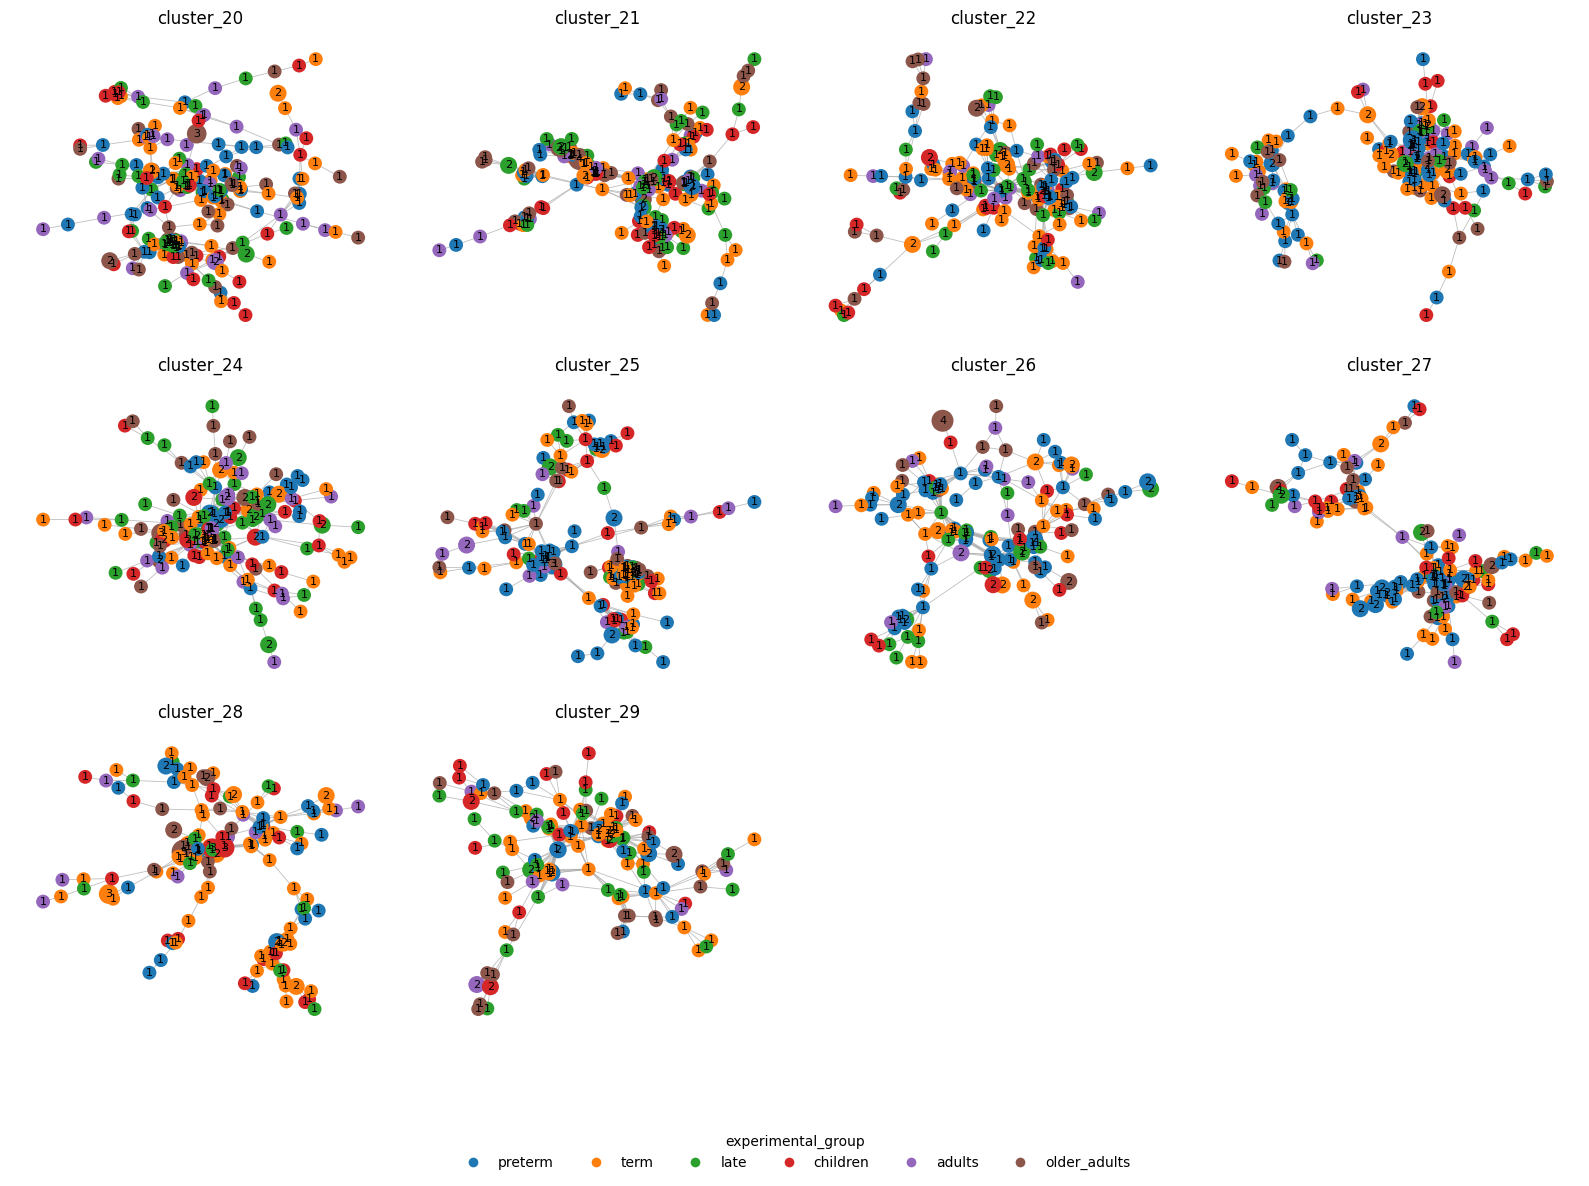

In [ ]:
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)


## Результаты

В следующей ячейке сравниваются медианы по группам и результаты на двух глубинах. Статистические тесты не проводились, поэтому выводы основаны на таблицах и графиках. F2 показывает сходство репертуаров, а оси MDS служат условными координатами образцов. Кластеры aaV объединяют похожие последовательности, но не доказывают, что они распознают один и тот же антиген.

In [ ]:
stats_table=diversity_stats.merge(metadata[['sample_id','experimental_group']],on='sample_id',validate='one_to_one')
summary=stats_table.groupby('experimental_group',observed=False)[['diversity','shannon_wiener','clonality','inverse_simpson']].median()
display(summary)
sensitivity=diversity_stats[['sample_id','diversity','shannon_wiener']].merge(
    diversity_half[['sample_id','diversity','shannon_wiener']],on='sample_id',suffixes=('_main','_half'),validate='one_to_one')
sensitivity['richness_ratio']=sensitivity.diversity_half/sensitivity.diversity_main
sensitivity['shannon_change']=sensitivity.shannon_wiener_half-sensitivity.shannon_wiener_main
display(sensitivity)
length_summary=cdr3_properties.merge(metadata[['sample_id','experimental_group']],on='sample_id',validate='one_to_one')
length_summary['mean_length_aa']=length_summary.mean_cdr3nt_len/3
display(length_summary.groupby('experimental_group',observed=False).mean_length_aa.median())
text=f'''## nCD8
В анализ включено {len(clonosets_cd8)} образцов. Основная глубина {depth}, дополнительная {half_depth}.
Медианное по образцам отношение богатств при уменьшении глубины составляет {sensitivity.richness_ratio.median():.3f}, изменение Shannon составляет {sensitivity.shannon_change.median():.3f}.
По групповым медианам наибольший Shannon наблюдается в {summary.shannon_wiener.idxmax()}, наименьший в {summary.shannon_wiener.idxmin()}.
Число кластеров с двумя и более вершинами: {int((cluster_properties.nodes>1).sum())}. Максимальный размер компоненты: {int(cluster_properties.nodes.max())}.
'''
display(Markdown(text))
(Path(WORKING_DIR)/'interpretation.md').write_text(text,encoding='utf-8')
for name,frame in {'samples':clonosets_cd8,'clonoset_stats':clonoset_stats_cd8,
    'cdr3_properties':cdr3_properties,'cdr3_lengths':cdr3_len_distribs,'v_usage':v_usage,
    'j_usage':j_usage,'convergence':convergence,'diversity':diversity_stats,
    'diversity_half':diversity_half,'rarefaction':rarefaction_points_ucb,
    'cluster_clonotypes':clusters_df,'cluster_properties':cluster_properties,
    'group_medians':summary.reset_index(),'sensitivity':sensitivity}.items():
    frame.to_csv(Path(WORKING_DIR)/(name+'.csv'),index=False)
beta_diversity['f2'].to_csv(Path(WORKING_DIR)/'f2.csv')
ucb_cd8_mds.to_csv(Path(WORKING_DIR)/'mds.csv',index=False)
del clusters,clusters_df,cluster_properties,beta_diversity
import gc
gc.collect()


,diversity,shannon_wiener,clonality,inverse_simpson
experimental_group,,,,
preterm,5817.0,8.635571,0.003803,5337.547068
term,6035.0,8.688803,0.001897,5787.077521
late,5916.5,8.661857,0.002722,5576.006257
children,6001.0,8.679065,0.002243,5694.347407
adults,6148.5,8.712801,0.001279,5945.210901
older_adults,5620.0,8.510748,0.014245,2082.626699


,sample_id,diversity_main,shannon_wiener_main,diversity_half,shannon_wiener_half,richness_ratio,shannon_change
0,c5_nCD8_TRB_1,6069.0,8.696644,3091.0,8.028694,0.509310,-0.667950
1,o4_nCD8_TRB_1,3416.0,7.793108,2161.0,7.434880,0.632611,-0.358228
2,c1_nCD8_TRB_1,6033.0,8.688639,3077.0,8.023031,0.510028,-0.665608
3,o2_nCD8_TRB_1,5476.0,8.494414,2868.0,7.886912,0.523740,-0.607502
4,UCB13_nCD8_TRB_1,6066.0,8.695734,3084.0,8.025447,0.508408,-0.670287
5,UCB4_nCD8_TRB_1,5364.0,8.531804,2902.0,7.942917,0.541014,-0.588887
6,UCB1_nCD8_TRB_2,5817.0,8.635571,3024.0,7.998045,0.519856,-0.637526
7,o1_nCD8_TRB_1,5903.0,8.650893,3028.0,7.995244,0.512960,-0.655649
8,UCB6_nCD8_TRB_1,5838.0,8.641689,3026.0,7.998463,0.518328,-0.643226
9,UCB12_nCD8_TRB_1,5952.0,8.669681,3046.0,8.008059,0.511761,-0.661622


,mean_length_aa
experimental_group,
preterm,13.585920
term,14.156291
late,14.184965
children,14.361736
adults,14.442689
older_adults,14.445058


## nCD8
В анализ включено 27 образцов. Основная глубина 6300, дополнительная 3150.
Медианное по образцам отношение богатств при уменьшении глубины составляет 0.512, изменение Shannon составляет -0.659.
По групповым медианам наибольший Shannon наблюдается в adults, наименьший в older_adults.
Число кластеров с двумя и более вершинами: 8282. Максимальный размер компоненты: 835.


42

В анализ вошли 27 образцов из шести групп. Основную глубину даунсэмплирования выбрали равной 6300 функциональным наблюдениям, дополнительную - 3150. При основной глубине удалось сохранить все образцы.

В preterm CDR3 короче, чем в late: медианы средней взвешенной длины составили 13,59 и 14,18 аминокислоты. Как и в CD4, меньший размер вставок сочетается с более высокой общей конвергенцией. У образцов preterm разные нуклеотидные последовательности чаще соответствуют одинаковым аминокислотным вариантам CDR3.

Наиболее представлены V-сегменты TRBV12-3, TRBV5-1 и TRBV7-9, а среди J-сегментов — TRBJ2-7, TRBJ2-1 и TRBJ2-3. Частоты различаются как между группами, так и между отдельными донорами.

Наиболее заметная особенность альфа-разнообразия наблюдается в older_adults. В этой группе медиана Shannon ниже, чем в adults: 8,511 против 8,713. Клональность, наоборот, выше: 0,0142 против 0,0013. Значит, у части старших доноров частоты распределены менее равномерно и сильнее выражен вклад частых клонотипов. При этом внутри группы есть большой разброс. Например, в образце o4_nCD8_TRB_1 на глубине 6300 обнаружено 3416 клонотипов.

После уменьшения глубины до 3150 медианное отношение числа обнаруженных клонотипов к основному расчёту составило 0,512, Shannon также снизился. Особенности older_adults сохранились: у части образцов по-прежнему ниже равномерность частот, а разброс показателей больше. Следовательно, эта картина сохраняется при выбранном изменении глубины.

Кривые rarefaction продолжают расти. Значения F2 между разными донорами невелики, а возрастные группы на MDS частично перекрываются. Некоторые доноры заметно удалены от основной области точек, но полного разделения групп нет.

Кластеризация выявила 8282 компоненты с двумя и более вершинами; крупнейшая содержит 835 вершин. Они объединяют близкие варианты CDR3 с одинаковым V-геном, но не доказывают общую антигенную специфичность. Интерпретацию возрастных различий ограничивают небольшие группы, индивидуальные особенности доноров и разные правила сортировки клеток


## Сопоставление CD4 и CD8
В обеих выборках у preterm CDR3 короче, размер вставок меньше, а конвергенция выше, чем у late. При этом картина разнообразия различается: в CD4 последовательного снижения с возрастом не видно, а в CD8 у older_adults ниже медиана Shannon и выше клональность. Это указывает на менее равномерное распределение частот клонотипов в CD8 у части старших доноров. Такая особенность сохраняется при уменьшении глубины вдвое.

На MDS возрастные группы в обеих выборках перекрываются. Различия остаются описательными, поскольку группы небольшие, а возраст связан с источником материала и условиями сортировки. Число клонотипов CD4 и CD8 напрямую не сравниваем: расчёты выполнены на разных глубинах - 5900 и 6300 наблюдений соответственно.

# Ограничения TCR-анализа

В группах немного образцов, и их количество различается. Возраст доноров связан с источником материала: UCB или PB. Кроме того, клетки выделяли по разным гейтам, в том числе внутри группы term. Поэтому различия между группами могут зависеть как от возраста, так и от клеточного состава.

Молекулярные счётчики отражают число наблюдений, но не позволяют напрямую определить количество клеток. Число найденных клонотипов характеризует исследованную библиотеку, а не весь репертуар организма. Чтобы сравнить богатство CD4 и CD8 между собой, нужно отдельно рассчитать его при одинаковой глубине.


## Скачать TCR-результаты

In [ ]:
archive=Path('/content/TCR_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for sub in ['nCD4','nCD8']:
        for p in (PROJECT/'results'/sub).rglob('*'):
            if p.is_file():z.write(p,p.relative_to(PROJECT))
files.download(str(archive))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Часть 2. BCR: MiXCR и анализ клонотипов


## 1. Установка Python-библиотек

In [1]:
# Устанавливаем библиотеки только в виртуальную машину Colab.
import sys, subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'repseq==0.1.3', 'scipy', 'matplotlib', 'seaborn>=0.13',
                'scikit-learn', 'nbformat', 'nbclient', 'ipykernel', 'psutil'], check=True)
print('Установка завершена. Переходите к следующей ячейке.')


Установка завершена. Переходите к следующей ячейке.


In [2]:
from pathlib import Path
import os, sys
PROJECT = Path('/content/Immune_homework')
(PROJECT / 'scripts').mkdir(parents=True, exist_ok=True)
(PROJECT / 'notebooks').mkdir(exist_ok=True)
(PROJECT / 'results').mkdir(exist_ok=True)
(PROJECT / 'environment.yml').write_text('# Colab project marker\n')
assets = {'repseq_compat.py': 'import copy\nfrom repseq.clone_filter import Filter\n\ndef preserve_filter_parameters():\n    Filter.spawn=lambda self: copy.deepcopy(self)\n', 'plot_helpers.py': '"""Explicitly display figures returned (and sometimes closed) by repseq."""\nfrom matplotlib.figure import Figure\nimport matplotlib.pyplot as plt\nfrom IPython.display import display\n\ndef show_plot(obj):\n    shown=set()\n    def visit(value):\n        if isinstance(value,dict):\n            for child in value.values(): visit(child)\n        elif isinstance(value,(list,tuple)):\n            for child in value: visit(child)\n        else:\n            fig=value if isinstance(value,Figure) else getattr(value,\'figure\',None)\n            if isinstance(fig,Figure) and id(fig) not in shown:\n                shown.add(id(fig))\n                group_labels={\'preterm\',\'term\',\'late\',\'children\',\'adults\',\'older_adults\'}\n                categorical=False\n                for ax in fig.axes:\n                    if any(t.get_text() in group_labels for t in ax.get_xticklabels()):\n                        categorical=True\n                        for t in ax.get_xticklabels():\n                            t.set_rotation(35);t.set_horizontalalignment(\'right\')\n                if categorical:\n                    fig.tight_layout()\n                import os\n                from pathlib import Path\n                folder=os.environ.get(\'PLOT_OUTPUT_DIR\')\n                if folder:\n                    target=Path(folder);target.mkdir(parents=True,exist_ok=True)\n                    existing=[int(p.stem) for p in target.glob(\'*.png\') if p.stem.isdigit()]\n                    number=max(existing,default=0)+1\n                    fig.savefig(target/f\'{number:02d}.png\',dpi=160,bbox_inches=\'tight\')\n                display(fig); plt.close(fig)\n    visit(obj)\n', 'fastq_qc.py': '"""Validate paired FASTQ and inspect the candidate MiLab R1 adapter (stdlib only)."""\nimport argparse, gzip, json, re\nfrom collections import Counter\nfrom pathlib import Path\n\ndef records(path):\n    with gzip.open(path, \'rt\') as f:\n        while True:\n            h=f.readline().rstrip()\n            if not h: return\n            s=f.readline().rstrip(); p=f.readline().rstrip(); q=f.readline().rstrip()\n            if not h.startswith(\'@\') or not p.startswith(\'+\') or len(s)!=len(q):\n                raise ValueError(f\'Invalid FASTQ: {path}: {h}\')\n            yield h.split()[0].removesuffix(\'/1\').removesuffix(\'/2\'), s, q\n\ndef main():\n    a=argparse.ArgumentParser(); a.add_argument(\'r1\'); a.add_argument(\'r2\'); a.add_argument(\'out\'); a.add_argument(\'--limit\',type=int,default=0)\n    a=a.parse_args(); it1=records(a.r1); it2=records(a.r2)\n    n=matched=q30=bases=0; lens=[Counter(),Counter()]; offsets=Counter()\n    from itertools import zip_longest\n    for x,y in zip_longest(it1,it2):\n        if x is None or y is None or x[0]!=y[0]: raise ValueError(\'Read pairs are not synchronized\')\n        n+=1\n        for k,rec in enumerate((x,y)):\n            lens[k][len(rec[1])]+=1; bases+=len(rec[2]); q30+=sum(ord(c)-33>=30 for c in rec[2])\n        m=re.match(r\'^([ACGTN]{0,2})TGGTATCAACGCAGAGT([ACGTN]{14})\',x[1])\n        if m: matched+=1; offsets[len(m[1])]+=1\n        if a.limit and n>=a.limit: break\n    out={\'read_pairs\':n,\'complete_file_scan\':not bool(a.limit),\'lengths_R1\':dict(lens[0]),\'lengths_R2\':dict(lens[1]),\n         \'Q30_base_fraction\':q30/bases if bases else None,\'candidate_adapter_exact_fraction_R1\':matched/n if n else None,\n         \'adapter_prefix_offset_counts\':dict(offsets),\n         \'interpretation\':\'Adapter compatibility supports but does not prove MiLab IG RNA UMI protocol; inspect MiXCR alignment/tag reports.\'}\n    Path(a.out).parent.mkdir(parents=True,exist_ok=True)\n    Path(a.out).write_text(json.dumps(out,indent=2),encoding=\'utf-8\'); print(json.dumps(out,indent=2))\nif __name__==\'__main__\': main()\n', 'colab_upload.py': "from pathlib import Path\nimport zipfile\nfrom google.colab import files\n\ndef unpack_upload(name, destination):\n    path=Path('/content')/name\n    if not path.is_file():\n        print('Выберите файл '+name+' на своём компьютере.')\n        files.upload(target_dir='/content')\n    if not path.is_file():\n        matches=[p for p in Path('/content').glob('*.zip') if p.name.startswith(Path(name).stem)]\n        assert len(matches)==1, 'Ожидался '+name+'; проверьте имя выбранного архива.'\n        path=matches[0]\n    destination=Path(destination);destination.mkdir(parents=True,exist_ok=True)\n    with zipfile.ZipFile(path) as z:\n        for item in z.infolist():\n            target=(destination/item.filename).resolve()\n            assert target.is_relative_to(destination.resolve()), 'Unexpected archive path'\n        z.extractall(destination)\n    print('Распакован:',path.name)\n"}
for name, text in assets.items():
    (PROJECT / 'scripts' / name).write_text(text, encoding='utf-8')
sys.path.insert(0, str(PROJECT / 'scripts'))
os.chdir(PROJECT)
print('Рабочая папка:', PROJECT)


Рабочая папка: /content/Immune_homework


## 2. Загрузка BCR_homework.zip

In [3]:
from colab_upload import unpack_upload
unpack_upload('BCR_homework.zip','/content/bcr_input')
r1s=list(Path('/content/bcr_input').rglob('DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz'))
assert len(r1s)==1, 'Не найдена единственная пара FASTQ'
R1=r1s[0]; R2=R1.with_name(R1.name.replace('_R1.','_R2.'))
assert R2.is_file(), 'Не найден R2'
print('R1:',R1.name,'; R2:',R2.name)


Выберите файл BCR_homework.zip на своём компьютере.


Saving BCR_homework.zip to /content/BCR_homework.zip
Распакован: BCR_homework.zip
R1: DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz ; R2: DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz


## 3. Установка Java и MiXCR 4.7.0

In [5]:
import subprocess, shutil, urllib.request, zipfile
subprocess.run(['apt-get','update','-qq'],check=True)
subprocess.run(['apt-get','install','-y','-qq','openjdk-17-jre-headless'],check=True)
JAVA_BIN=str(next(Path('/usr/lib/jvm').glob('java-17*/bin/java')))
subprocess.run([JAVA_BIN,'-version'],check=True)
dist=Path('/content/mixcr-4.7.0.zip')
if not dist.exists():
    urllib.request.urlretrieve('https://github.com/milaboratory/mixcr/releases/download/v4.7.0/mixcr-4.7.0.zip',dist)
tools=Path('/content/mixcr_tools');tools.mkdir(exist_ok=True)
with zipfile.ZipFile(dist) as z:z.extractall(tools)
jars=list(tools.rglob('mixcr.jar'))
assert len(jars)==1, 'Не найден единственный mixcr.jar'
MIXCR_JAR=jars[0]
result = subprocess.run(
    [JAVA_BIN, '-jar', str(MIXCR_JAR), '-v'],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
result.check_returncode()


MiXCR v4.7.0 (built Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; branch=no_branch; host=fv-az1019-185)
RepSeq.IO v2.5.0 (rev=06fa1852ee)
MiLib v3.5.0 (rev=b6cfcdc2af)
Built-in V/D/J/C library: repseqio.v5.1

Library search path:
- built-in libraries
- /content/Immune_homework/.




## 4. Ключ MiXCR


In [6]:
from getpass import getpass
license_key=getpass('Ключ MiXCR: ').strip()
if not license_key:
    raise RuntimeError('Ключ не введён. Получите лицензию, затем повторите эту ячейку.')
os.environ['MI_LICENSE']=license_key
del license_key
print('Ключ передан MiXCR; его содержимое не выводится.')


Ключ MiXCR: ··········
Ключ передан MiXCR; его содержимое не выводится.


## 5. FASTQ и MiXCR


In [7]:
import time, psutil
BCR_OUT=PROJECT/'results'/'bcr'/time.strftime('%Y%m%d_%H%M%S')
BCR_OUT.mkdir(parents=True,exist_ok=False)
subprocess.run([sys.executable,str(PROJECT/'scripts/fastq_qc.py'),str(R1),str(R2),str(BCR_OUT/'fastq_qc.json')],check=True)
heap_gb=max(2,min(8,int(psutil.virtual_memory().available/(1024**3)*0.65)))
command=[JAVA_BIN,f'-Xmx{heap_gb}g','-jar',str(MIXCR_JAR),
         'analyze','milab-human-rna-ig-umi-multiplex','--threads','2',
         str(R1),str(R2),str(BCR_OUT/'DChu_T7_pbmc_d7COVID2_2')]
with (BCR_OUT/'mixcr.log').open('w') as logfile:
    process=subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in process.stdout:
        print(line,end='');logfile.write(line);logfile.flush()
    returncode=process.wait()
if returncode:
    raise RuntimeError(f'MiXCR завершился с кодом {returncode}; смотрите текст ошибки выше.')
os.environ['BCR_CLONES_DIR']=str(BCR_OUT)
print('MiXCR завершён. Можно выполнять анализ ниже.')



>>>>>>>>>>>>>>>>>>>>>>> mixcr align <<<<<<<<<<<<<<<<<<<<<<<
Running:
mixcr align --report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.report.txt --json-report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.report.json --threads 2 --preset milab-human-rna-ig-umi-multiplex --save-output-file-names /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.list.tsv /content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz /content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.alignments.vdjca
The following tags and their roles will be associated with each output alignment:
  Payload tags: R1, R2
  Molecule tags: UMI(SQ)
Alignment: 0%
Alignment: 10.5%  ETA: 00:10:54
Alignment: 21.1%  ETA: 00:08:14
Alignment: 31.6%  ETA: 00:06:35
Alignment: 42.2%  ETA: 00:05:51
Alignment: 52.7%  ETA: 00:04:33
Alignment: 62.8%  ETA: 00:0

# BCR анализ

In [8]:
from pathlib import Path
import os, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repseq import clonosets as cl, clone_filter as clf, stats, io
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'environment.yml').exists() and (p/'notebooks').is_dir())
assert os.environ.get('BCR_CLONES_DIR'), 'Set BCR_CLONES_DIR to the MiXCR output directory'
import sys
sys.path.insert(0, str(ROOT/'scripts'))
from repseq_compat import preserve_filter_parameters
preserve_filter_parameters()
DATA = Path(os.environ['BCR_CLONES_DIR'])
OUT = DATA/'postanalysis'; OUT.mkdir(exist_ok=True)
samples = cl.find_all_mixcr_clonosets(str(DATA), show_offtarget=True)
samples = samples[samples.chain.isin(['IGH','IGK','IGL'])].reset_index(drop=True)
assert len(samples)>0, 'No IGH/IGK/IGL clone tables found'
assert samples.chain.is_unique, 'Expected one bulk sample per chain; inspect files'
display(samples)
samples.to_csv(OUT/'samples.csv',index=False)


,sample_id,chain,filename
0,DChu_T7_pbmc_d7COVID2_2,IGH,/content/Immune_homework/results/bcr/20261117_...


## QC MiXCR

In [9]:
for p in sorted(DATA.glob('*.report.txt')):
    display(Markdown('### '+p.name))
    print(p.read_text(errors='replace'))
qc = stats.calc_clonoset_stats(samples, cpu=1)
display(qc)
qc.to_csv(OUT/'clonoset_stats.csv',index=False)
for row in samples.itertuples():
    raw = pd.read_csv(row.filename, sep='\t')
    umi_cols = [c for c in ['uniqueUMICount','uniqueMoleculeCount','umi_count'] if c in raw]
    assert umi_cols, f'No explicit UMI count in {row.filename}; inspect MiXCR export'
    assert raw[umi_cols[0]].notna().all(), 'Missing UMI counts'


### DChu_T7_pbmc_d7COVID2_2.align.report.txt

Analysis date: Tue Nov 17 08:48:22 UTC 2026
Input file(s): /content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz,/content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz
Output file(s): /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.alignments.vdjca
Version: 4.7.0; built=Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; lib=repseqio.v5.1
Command line arguments: align --report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.report.txt --json-report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.report.json --threads 2 --preset milab-human-rna-ig-umi-multiplex --save-output-file-names /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.align.list.tsv /content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz /content/bcr_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.alignments.vdjca
Analysis time: 10.

### DChu_T7_pbmc_d7COVID2_2.assemble.report.txt

Analysis date: Tue Nov 17 09:00:55 UTC 2026
Input file(s): /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refined.vdjca
Output file(s): /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.clns
Version: 4.7.0; built=Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; lib=repseqio.v5.1
Command line arguments: assemble --report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.assemble.report.txt --json-report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.assemble.report.json /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refined.vdjca /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.clns
Analysis time: 7.93m
Final clonotype count: 37516
Reads used in clonotypes, percent of total: 716879 (91.59%)
Average number of reads per clonotype: 19.11
Reads dropped due to the lack of a clone sequence, percent of total: 22210 (2.84%)
Read

### DChu_T7_pbmc_d7COVID2_2.refine.report.txt

Analysis date: Tue Nov 17 09:00:55 UTC 2026
Input file(s): /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.alignments.vdjca
Output file(s): /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refined.vdjca
Version: 4.7.0; built=Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; lib=repseqio.v5.1
Command line arguments: refineTagsAndSort --report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refine.report.txt --json-report /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refine.report.json /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.alignments.vdjca /content/Immune_homework/results/bcr/20261117_084737/DChu_T7_pbmc_d7COVID2_2.refined.vdjca
Analysis time: 2.34m
Number of input records: 865681
Number of output records: 782678 (90.41%)
UMI correction report:
  UMI input diversity: 175450
  UMI output diversity: 163191 (93.01%)
  UMI input records: 8656

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,DChu_T7_pbmc_d7COVID2_2,IGH,37516,36416,24463,11953,1100,0.029321,716879,706820,10059,0.014032,90924,89665,1259,0.013847,7.88


## Определение клонотипа и разнообразие

,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,DChu_T7_pbmc_d7COVID2_2,IGH,29619.0,0.878809,0.121191,9.048373,45695.343494,29619.0,47648.159247,0.823287,0.060738,0.000935,1069.777355,0.999065,0.019127,0.576292


,sample_id,chain,convergence,convergence_v,convergence_vj
0,DChu_T7_pbmc_d7COVID2_2,IGH,1.00773,1.007489,1.007415


Using 1 core
CalcCDR3LengthDistribution |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,DChu_T7_pbmc_d7COVID2_2,IGH,6,0.000357
1,DChu_T7_pbmc_d7COVID2_2,IGH,7,0.002309
2,DChu_T7_pbmc_d7COVID2_2,IGH,8,0.004517
3,DChu_T7_pbmc_d7COVID2_2,IGH,9,0.004004
4,DChu_T7_pbmc_d7COVID2_2,IGH,10,0.007316


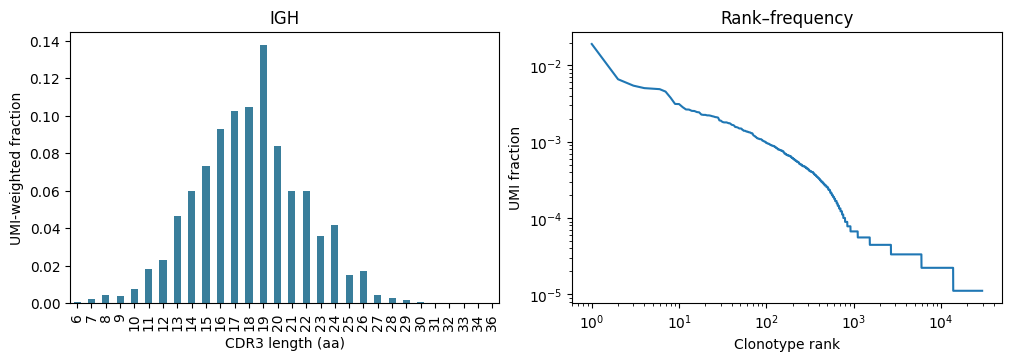

In [10]:
func_filter = clf.Filter(functionality='f', by_umi=True, pool_clonoset_by='ntVJ')
div = stats.calc_diversity_stats(samples, cl_filter=func_filter, iterations=1, seed=123, cpu=1, verbose=False)
display(div); div.to_csv(OUT/'diversity_ntVJ.csv',index=False)
conv = stats.calc_convergence(samples, cl_filter=func_filter, iterations=1, seed=123, cpu=1, verbose=False)
display(conv); conv.to_csv(OUT/'convergence_ntVJ.csv',index=False)
lengths = stats.cdr3_length_distributions(samples, cl_filter=func_filter, cpu=1, seq_type='aa', table='long', count_by_freq=True)
lengths.to_csv(OUT/'cdr3_lengths.csv', index=False)
display(lengths.head())
# Построения непосредственно по отфильтрованным таблицам, без фиктивных групп.
for row in samples.itertuples():
    frame = func_filter.apply(io.read_clonoset(row.filename))
    aa=frame['cdr3aa'].astype(str)
    counts=frame['count'].astype(float)
    freq=counts/counts.sum()
    dist=pd.DataFrame({'length':aa.str.len(),'frequency':freq}).groupby('length').frequency.sum()
    fig,axs=plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
    dist.plot.bar(ax=axs[0],color='#397E9B'); axs[0].set(xlabel='CDR3 length (aa)',ylabel='UMI-weighted fraction',title=row.chain)
    axs[1].plot(np.arange(1,len(freq)+1),np.sort(freq)[::-1]); axs[1].set(xscale='log',yscale='log',xlabel='Clonotype rank',ylabel='UMI fraction',title='Rank–frequency')
    fig.savefig(OUT/f'{row.chain}_cdr3_rank.png',dpi=180); plt.show()


## V/J usage, изотипы и rarefaction

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


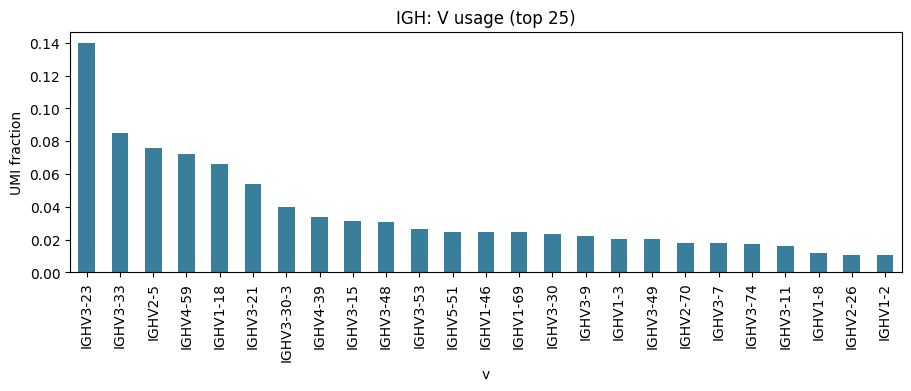

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


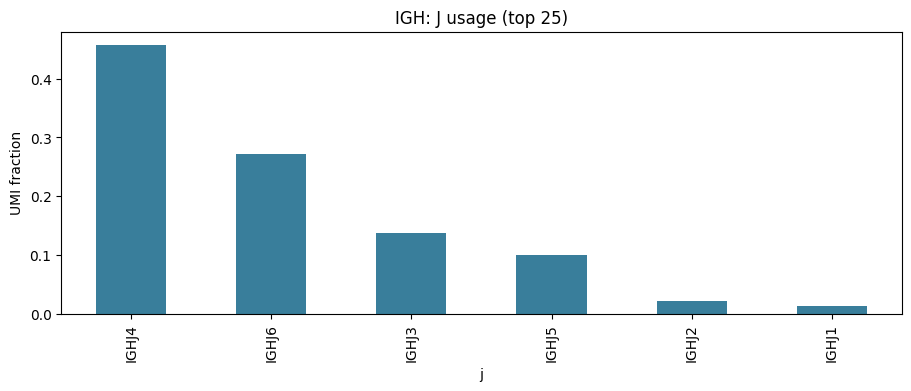

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,c,usage
0,DChu_T7_pbmc_d7COVID2_2,IGH,<NA>,0.000056
1,DChu_T7_pbmc_d7COVID2_2,IGH,IGHA1,0.114638
2,DChu_T7_pbmc_d7COVID2_2,IGH,IGHA2,0.027145
3,DChu_T7_pbmc_d7COVID2_2,IGH,IGHD,0.215636
4,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG1,0.186059
5,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG2,0.014242
6,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG3,0.032621
7,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG4,0.000167
8,DChu_T7_pbmc_d7COVID2_2,IGH,IGHGP,0.000011
9,DChu_T7_pbmc_d7COVID2_2,IGH,IGHM,0.409424


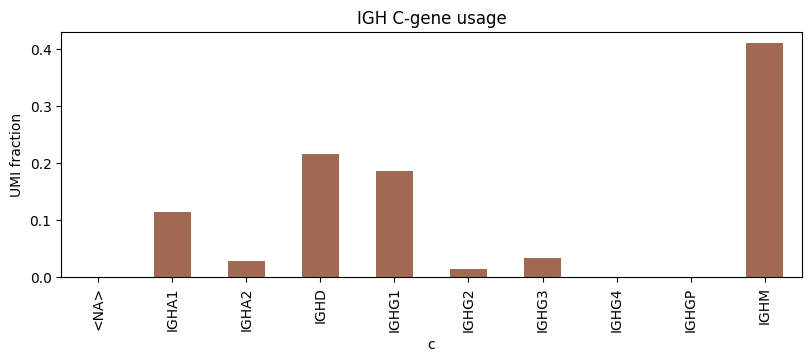

Using 1 core
CalcRarefactionPoints |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,DChu_T7_pbmc_d7COVID2_2,IGH,32,32.000000
1,DChu_T7_pbmc_d7COVID2_2,IGH,100,98.333333
2,DChu_T7_pbmc_d7COVID2_2,IGH,316,293.000000
3,DChu_T7_pbmc_d7COVID2_2,IGH,1000,827.333333
4,DChu_T7_pbmc_d7COVID2_2,IGH,3162,2242.666667
5,DChu_T7_pbmc_d7COVID2_2,IGH,10000,5902.000000
6,DChu_T7_pbmc_d7COVID2_2,IGH,31623,14947.000000
7,DChu_T7_pbmc_d7COVID2_2,IGH,89665,29619.000000


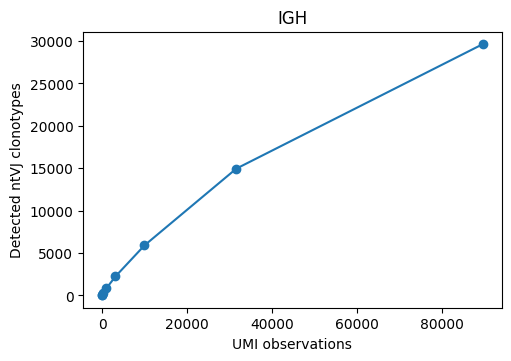

In [11]:
for row in samples.itertuples():
    one = samples[samples.chain==row.chain]
    for segment in ['v','j']:
        usage = stats.calc_segment_usage(one, segment=segment, cl_filter=func_filter, table='long', cpu=1)
        usage.to_csv(OUT/f'{row.chain}_{segment}_usage.csv',index=False)
        u=usage.set_index(segment).usage.sort_values(ascending=False).head(25)
        fig,ax=plt.subplots(figsize=(9,3.8),layout='constrained')
        u.plot.bar(ax=ax,color='#397E9B'); ax.set(ylabel='UMI fraction',title=f'{row.chain}: {segment.upper()} usage (top 25)')
        fig.savefig(OUT/f'{row.chain}_{segment}_usage.png',dpi=180); plt.show()
    if row.chain=='IGH':
        cusage=stats.calc_segment_usage(one,segment='c',cl_filter=clf.Filter(functionality='f',by_umi=True),table='long',cpu=1)
        display(cusage); cusage.to_csv(OUT/'IGH_c_usage.csv',index=False)
        fig,ax=plt.subplots(figsize=(8,3.5),layout='constrained')
        cusage.set_index('c').usage.plot.bar(ax=ax,color='#A26952'); ax.set(ylabel='UMI fraction',title='IGH C-gene usage')
        fig.savefig(OUT/'IGH_c_usage.png',dpi=180); plt.show()
rare=stats.calc_rarefaction_curve(samples,cl_filter=func_filter,cpu=1,seed=100)
display(rare); rare.to_csv(OUT/'rarefaction.csv',index=False)
for chain,part in rare.groupby('chain'):
    fig,ax=plt.subplots(figsize=(5,3.5),layout='constrained')
    ax.plot(part.rarefaction_depth,part.diversity,'o-'); ax.set(xlabel='UMI observations',ylabel='Detected ntVJ clonotypes',title=chain)
    fig.savefig(OUT/f'{chain}_rarefaction.png',dpi=180); plt.show()


## Сводка и интерпретация по рассчитанным данным

In [15]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd

summary_rows=[]
paragraphs=['# Результаты анализа BCR',
'''Один bulk-образец; цепи анализируются раздельно. В downstream-анализе вариант определён как CDR3nt+V+J. Это не реконструкция B-клеточных клональных линий.''']
for row in samples.itertuples():
    filtered=func_filter.apply(io.read_clonoset(row.filename))
    assert len(filtered)>0, f'Нет продуктивных вариантов для {row.chain}'
    count=filtered['count'].to_numpy(dtype=float)
    frequency=count/count.sum()
    top10=float(np.sort(frequency)[-10:].sum())
    mean_length=float(np.average(filtered.cdr3aa.str.len(),weights=count))
    d=div[div.chain==row.chain].iloc[0]
    q=qc[qc.chain==row.chain].iloc[0]
    record={'chain':row.chain,'exported_clonotypes':int(q.clones),
            'productive_exported_clonotypes':int(q.clones_func),
            'ntVJ_clonotypes':len(filtered),'summed_UMI_counts_ntVJ':float(count.sum()),
            'shannon':float(d.shannon_wiener),'clonality':float(d.clonality),
            'top10_UMI_fraction':top10,'weighted_mean_CDR3_length_aa':mean_length}
    summary_rows.append(record)
    paragraphs.append(f'''## {row.chain}
В исходном экспорте {int(q.clones)} клонотипов, из них {int(q.clones_func)} продуктивных. После объединения по ntVJ осталось {len(filtered)} вариантов. Сумма их UMI-счётчиков — {count.sum():.0f}; это молекулярные наблюдения, а не число B-клеток.

Shannon = {float(d.shannon_wiener):.3f}, клональность = {float(d.clonality):.4f}. Десять наиболее частых вариантов составляют {top10:.1%} всех UMI-наблюдений в этом определении репертуара. Эти показатели характеризуют концентрацию частот внутри образца; для вывода об изменении при болезни нужен сопоставимый контроль.

Средняя длина CDR3, взвешенная UMI-счётчиками, — {mean_length:.2f} аминокислоты.''')
    for segment in ['v','j']:
        usage=pd.read_csv(OUT/f'{row.chain}_{segment}_usage.csv')
        leaders=usage.nlargest(3,'usage')
        description=', '.join(f'{x[segment]} ({x["usage"]:.1%})' for _,x in leaders.iterrows())
        paragraphs.append(f'Наиболее представленные {segment.upper()}-сегменты: {description}. Это частоты молекулярных наблюдений; они не устанавливают антигенную специфичность.')
    part=rare[rare.chain==row.chain].sort_values('rarefaction_depth')
    if len(part)>1:
        last=part.iloc[-1];previous=part.iloc[-2]
        paragraphs.append(f'''На двух последних точках rarefaction глубина составляет {int(previous.rarefaction_depth)} и {int(last.rarefaction_depth)} наблюдений, число обнаруженных вариантов — {previous.diversity:.1f} и {last.diversity:.1f}. Кривая rarefaction продолжает расти без выраженного плато. При увеличении глубины с 31 623 до 89 665 наблюдений число обнаруженных вариантов выросло с 14 947 до 29 619. Значит, глубина заметно влияет на обнаруженное богатство, и при дополнительном секвенировании могут выявляться новые редкие варианты.''')
    if row.chain=='IGH' and (OUT/'IGH_c_usage.csv').exists():
        cusage=pd.read_csv(OUT/'IGH_c_usage.csv').nlargest(5,'usage')
        text=', '.join(f'{x["c"]} ({x["usage"]:.1%})' for _,x in cusage.iterrows())
        paragraphs.append('Наиболее представленные C-сегменты IGH: '+text+'. Их частоты относятся к исходным продуктивным строкам экспорта, до объединения ntVJ. Не следует приравнивать их к долям клеток.')

paragraphs.append(''' ## Проверка качества MiXCR
На вход MiXCR поступило 938 889 пар прочтений. Структура тегов распознана у 99,67% пар, успешно выровнялись 865 681 пары — 92,2% исходных данных. После коррекции число различных UMI уменьшилось со 175 450 до 163 191, а после фильтрации осталось 103 842 группы UMI.

В итоговую сборку вошли 716 879 прочтений — около 76,4% исходного количества. Обработка завершилась успешно. MiXCR отметил два предупреждения: коллизии баркодов при сборке составили 2,73%, а при фильтрации тегов было потеряно 9,59% записей. Эти особенности учитываются при интерпретации UMI-счётчиков.
## Ограничения
Один образец не позволяет оценить различия между пациентами, динамику болезни или эффект лечения. R1/R2 не являются биологическими репликами. Цепи IGH/IGK/IGL в bulk-данных не образуют восстановленные пары рецептора. Разные варианты BCR могут возникать при SHM; сходство CDR3 само по себе не доказывает общее происхождение или специфичность. Объединение ntVJ теряет различия изотипов и мутации вне CDR3. При суммировании экспортированных UMI-счётчиков нельзя повторно устранить возможный учёт одной UMI в разных строках.''')
summary=pd.DataFrame(summary_rows)
summary.to_csv(OUT/'BCR_summary.csv',index=False)
text='\n\n'.join(paragraphs)
(OUT/'BCR_interpretation.md').write_text(text,encoding='utf-8')
display(summary)
display(Markdown(text))


,chain,exported_clonotypes,productive_exported_clonotypes,ntVJ_clonotypes,summed_UMI_counts_ntVJ,shannon,clonality,top10_UMI_fraction,weighted_mean_CDR3_length_aa
0,IGH,37516,36416,29619,89665.0,9.048373,0.121191,0.060681,18.077154


# Результаты анализа BCR

Один bulk-образец; цепи анализируются раздельно. В downstream-анализе вариант определён как CDR3nt+V+J. Это не реконструкция B-клеточных клональных линий.

## IGH
В исходном экспорте 37516 клонотипов, из них 36416 продуктивных. После объединения по ntVJ осталось 29619 вариантов. Сумма их UMI-счётчиков — 89665; это молекулярные наблюдения, а не число B-клеток.

Shannon = 9.048, клональность = 0.1212. Десять наиболее частых вариантов составляют 6.1% всех UMI-наблюдений в этом определении репертуара. Эти показатели характеризуют концентрацию частот внутри образца; для вывода об изменении при болезни нужен сопоставимый контроль.

Средняя длина CDR3, взвешенная UMI-счётчиками, — 18.08 аминокислоты.

Наиболее представленные V-сегменты: IGHV3-23 (14.0%), IGHV3-33 (8.5%), IGHV2-5 (7.6%). Это частоты молекулярных наблюдений; они не устанавливают антигенную специфичность.

Наиболее представленные J-сегменты: IGHJ4 (45.7%), IGHJ6 (27.1%), IGHJ3 (13.8%). Это частоты молекулярных наблюдений; они не устанавливают антигенную специфичность.

На двух последних точках rarefaction глубина составляет 31623 и 89665 наблюдений, число обнаруженных вариантов — 14947.0 и 29619.0. Кривая rarefaction продолжает расти без выраженного плато. При увеличении глубины с 31 623 до 89 665 наблюдений число обнаруженных вариантов выросло с 14 947 до 29 619. Значит, глубина заметно влияет на обнаруженное богатство, и при дополнительном секвенировании могут выявляться новые редкие варианты.

Наиболее представленные C-сегменты IGH: IGHM (40.9%), IGHD (21.6%), IGHG1 (18.6%), IGHA1 (11.5%), IGHG3 (3.3%). Их частоты относятся к исходным продуктивным строкам экспорта, до объединения ntVJ. Не следует приравнивать их к долям клеток.

 ## Проверка качества MiXCR 
На вход MiXCR поступило 938 889 пар прочтений. Структура тегов распознана у 99,67% пар, успешно выровнялись 865 681 пары — 92,2% исходных данных. После коррекции число различных UMI уменьшилось со 175 450 до 163 191, а после фильтрации осталось 103 842 группы UMI.

В итоговую сборку вошли 716 879 прочтений — около 76,4% исходного количества. Обработка завершилась успешно. MiXCR отметил два предупреждения: коллизии баркодов при сборке составили 2,73%, а при фильтрации тегов было потеряно 9,59% записей. Эти особенности учитываются при интерпретации UMI-счётчиков.
## Ограничения
Один образец не позволяет оценить различия между пациентами, динамику болезни или эффект лечения. R1/R2 не являются биологическими репликами. Цепи IGH/IGK/IGL в bulk-данных не образуют восстановленные пары рецептора. Разные варианты BCR могут возникать при SHM; сходство CDR3 само по себе не доказывает общее происхождение или специфичность. Объединение ntVJ теряет различия изотипов и мутации вне CDR3. При суммировании экспортированных UMI-счётчиков нельзя повторно устранить возможный учёт одной UMI в разных строках.

В результате обработки 938 889 пар прочтений успешно выровнялись 92,2%. В итоговую сборку вошли 716 879 прочтений — около 76,4% исходных данных. MiXCR завершил обработку успешно, но отметил коллизии баркодов при сборке (2,73%) и потерю записей при фильтрации тегов (9,59%). Эти предупреждения нужно учитывать при интерпретации молекулярных счётчиков.

В полученных таблицах представлена тяжёлая цепь иммуноглобулина IGH. Из 37 516 экспортированных клонотипов фильтр продуктивности repseq сохранил 36 416, то есть около 97,1%. После объединения по нуклеотидной последовательности CDR3, V- и J-генам осталось 29 619 вариантов с суммарным UMI-счётчиком 89 665. При таком объединении теряются различия изотипов и мутации за пределами CDR3, поэтому эти варианты нельзя напрямую считать B-клеточными клональными линиями.

Репертуар содержит много редких вариантов, но их частоты заметно различаются. Индекс Shannon составил 9,048, нормированный Shannon — 0,879, клональность — 0,121. На десять наиболее частых вариантов приходится около 6,1% молекулярных наблюдений, а на самый частый — около 1,9%. На ранговом графике этому соответствует небольшое число частых вариантов и длинный хвост редких.

Средняя длина CDR3 с учётом UMI-счётчиков составила 18,08 аминокислоты. Основная часть распределения сосредоточена в центральной области, короткие и длинные CDR3 встречаются реже. Конвергенция близка к единице: отношение числа уникальных CDR3nt к числу CDR3aa составляет 1,0077. Разные нуклеотидные последовательности, кодирующие одинаковую аминокислотную CDR3, встречаются, но слабо влияют на общее число вариантов.

Использование V- и J-сегментов неравномерно. Среди V-сегментов наиболее представлены IGHV3-23 (14,0%), IGHV3-33 (8,5%) и IGHV2-5 (7,6%). Среди J-сегментов преобладают IGHJ4 (45,7%), IGHJ6 (27,1%) и IGHJ3 (13,8%). Эти частоты описывают исследованный образец; сами по себе они не позволяют определить антигенную специфичность.

Среди C-сегментов преобладают IGHM (40,9%), IGHD (21,6%), IGHG1 (18,6%) и IGHA1 (11,5%). Вместе IGHM и IGHD составляют около 62,5% молекулярных наблюдений. Доли рассчитаны до объединения вариантов по CDR3nt+V+J. Они отражают состав транскриптов в библиотеке и не равны долям клеток соответствующих типов.

Кривая rarefaction продолжает расти без выраженного плато. При глубине 31 623 наблюдения обнаруживается в среднем 14 947 вариантов, а на полной глубине 89 665 наблюдений — 29 619. Значит, число обнаруженных вариантов существенно зависит от глубины: дополнительное секвенирование может выявить ещё часть редких последовательностей. Полученное богатство характеризует эту библиотеку, а не полный репертуар организма.

Анализ выполнен для одного образца, поэтому сравнить группы или оценить изменения во времени нельзя. UMI отражают число молекул, а не клеток. Для исследования соматических гипермутаций и восстановления клональных линий нужен отдельный анализ.

## Скачать результаты


In [16]:
from pathlib import Path
import zipfile
from google.colab import files
archive=Path('/content/BCR_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in (PROJECT/'results'/'bcr').rglob('*'):
        if p.is_file():
            z.write(p,p.relative_to(PROJECT))
files.download(str(archive))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>